# Demo Enclosure — Water Leakage Overpressure Transient

Models water leaking from the powerstick cooling circuit into the hot zone, vaporising via film boiling, and pressurising the Argon-filled enclosure.

**Steps:**
1. Max exhaust-stack flow capacity at rated pressure (1 inH₂O gauge)
2. Equivalent water leak rate that saturates that capacity
3. Film-boiling-limited vaporisation rate on hot cavity walls
4. P(t) sweeping hot-cavity temperature and stack diameter

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP

g        = 9.81
sigma_sb = 5.67e-8
R        = 8.314
M_Ar     = 0.03995
M_w      = 0.01802

in_m    = 0.0254
ft_m    = 0.3048
ft3_m3  = ft_m**3
Pa_inH2O = 1/249.089

In [41]:
# --- Enclosure ---
V_enc       = 14700 * ft3_m3   # 416.3 m3
P_max_gauge = 1 / Pa_inH2O     # 249 Pa (1 inH2O)
P_atm       = 101325.0         # Pa
T_bulk      = 313.15           # K (40 C enclosure bulk)
T_amb       = 293.15           # K (20 C ambient)
eps_wall    = 0.8              # graphite hot-zone wall emissivity

# --- Hot zone (vertical rectangular prism, internal surfaces) ---
H_hz = 67.75  * in_m           # 1.721 m
W_hz = 10.875 * in_m           # 0.2762 m
A_hot = 4 * W_hz * H_hz + W_hz**2   # 4 side walls + bottom [m2]
print(f"Hot zone internal area: {A_hot:.4f} m2  ({A_hot/in_m**2:.1f} in2)")

# Radiation model: if True, h_rad is multiplied by Planck-weighted steam
# absorptivity (cavity path = W_hz/2). Set False to assume fully opaque water
# (standard pool film-boiling assumption).
apply_steam_absorptivity = True

# Reaction model: if True, water immediately reacts with the graphite wall via
# the water-gas reaction  C(s) + H2O → CO(g) + H2(g)  instead of boiling.
# Effect: (a) endothermic ΔH_rxn ~131 kJ/mol adds to effective latent heat,
# reducing the mass consumption rate; (b) 2 mol of gas (CO+H2) are produced
# per mol H2O (doubles molar generation); net effect is lower enclosure pressure
# because the reaction enthalpy penalty outweighs the doubled molar production.
water_gas_reaction = False

# Maximum water volume that can be spilled; simulation continues until
# pressure decays back to 0.1 inH2O after the supply is exhausted.
gal_m3       = 3.785411784e-3   # m3 per US gallon
V_spill_gal  = 7.5              # US gallons of water available to spill

# --- Exhaust stack ---
d_port          = 6 * in_m     # 0.1524 m  — fixed enclosure port (6" max)
d_stack_default = 6 * in_m     # 0.1524 m
L_stack         = 31 * ft_m    # 9.449 m
roughness_stack = 1e-6         # m
K_ent           = 0.5             # sharp-edged entry (no bell-mouth)
K_exit          = 1.0

# --- Liner-break scenario ---
# When liner_break=True the water covers the full hot-zone floor (A_floor_break),
# and the wall temperature is held constant at T_block_K (no transient cooling).
liner_break    = True
A_floor_break  = 18.0             # m^2  full hot-zone floor area
water_shutoff  = True             # False = infinite supply (no exhaustion cutoff)

# --- Emergency exhaust duct (liner_break case) ---
d_emerg        = 3 * ft_m         # 3 ft diameter = 0.9144 m
K_ent_emerg    = 0.5              # sharp-edged entry, same as main duct
K_exit_emerg   = 0.2

Hot zone internal area: 1.9777 m2  (3065.4 in2)


In [42]:
P_boil = P_atm

T_sat      = CP.PropsSI('T', 'Q', 0,       'P', P_boil, 'Water')
k_v        = CP.PropsSI('L', 'T', T_sat+1, 'P', P_boil, 'Water')
rho_v      = CP.PropsSI('D', 'T', T_sat+1, 'P', P_boil, 'Water')
rho_l      = CP.PropsSI('D', 'T', T_sat-1, 'P', P_boil, 'Water')
mu_v       = CP.PropsSI('V', 'T', T_sat+1, 'P', P_boil, 'Water')
h_fg       = (CP.PropsSI('H', 'T', T_sat+1, 'P', P_boil, 'Water') -
              CP.PropsSI('H', 'T', T_sat-1, 'P', P_boil, 'Water'))
sigma_surf = CP.PropsSI('I', 'T', T_sat, 'Q', 0.5, 'Water')

print(f"T_sat      = {T_sat-273.15:.1f} C")
print(f"h_fg       = {h_fg/1e3:.1f} kJ/kg")
print(f"rho_liquid = {rho_l:.1f} kg/m3")
print(f"rho_vapour = {rho_v:.4f} kg/m3")
print(f"k_vapour   = {k_v:.4f} W/(m*K)")
print(f"mu_vapour  = {mu_v:.3e} Pa*s")
print(f"sigma_surf = {sigma_surf:.4f} N/m")

T_inlet    = 313.15  # K (40 C), water inlet temperature
cp_l       = CP.PropsSI('C', 'T', 0.5*(T_sat + T_inlet), 'P', P_boil, 'Water')
dh_subcool = cp_l * (T_sat - T_inlet)  # J/kg, sensible heat to reach saturation
print(f"T_inlet    = {T_inlet-273.15:.0f} C")
print(f"dh_subcool = {dh_subcool/1e3:.1f} kJ/kg")

def cp_steam(T_K):
    """Steam cp [J/(kg K)] — CoolProp IAPWS-95 up to 1273 K,
    NIST Shomate phase-2 above (phase-1 overshoots near 1700 K).
    Vectorised: accepts scalar or array T_K.
    """
    T_K    = np.asarray(T_K, dtype=float)
    scalar = T_K.ndim == 0
    T_K    = np.atleast_1d(T_K)
    result = np.empty_like(T_K)
    lo = T_K <= 1273.0
    hi = ~lo
    if lo.any():
        result[lo] = np.vectorize(
            lambda T: CP.PropsSI("Cpmass", "T", max(T, T_sat + 0.05), "P", P_atm, "Water")
        )(T_K[lo])
    if hi.any():
        t = T_K[hi] / 1000.0
        result[hi] = (30.030 + 8.7730*t - 3.9883*t**2
                      + 0.7880*t**3 - 0.7416/t**2) / M_w
    return float(result[0]) if scalar else result

def h_superheat(T_lo_K, T_hi_K, n=50):
    """Enthalpy to heat 1 kg of steam from T_lo to T_hi [J/kg].
    CoolProp enthalpy difference below 1273 K (exact); integrates cp_steam above.
    """
    T_lim = 1273.0
    _T_lo = max(T_lo_K, T_sat + 0.05)   # avoid T+P saturation ambiguity in CoolProp
    if T_hi_K <= T_lim:
        return float(CP.PropsSI("H", "T", T_hi_K, "P", P_atm, "Water") -
                     CP.PropsSI("H", "T", _T_lo, "P", P_atm, "Water"))
    if T_lo_K < T_lim:
        h_base = float(CP.PropsSI("H", "T", T_lim, "P", P_atm, "Water") -
                       CP.PropsSI("H", "T", _T_lo, "P", P_atm, "Water"))
        T_arr  = np.linspace(T_lim, T_hi_K, n)
        return h_base + float(np.trapz(cp_steam(T_arr), T_arr))
    T_arr = np.linspace(T_lo_K, T_hi_K, n)
    return float(np.trapz(cp_steam(T_arr), T_arr))

# --- Steam cavity absorptivity (Planck-weighted H2O band model) ---
# Radiation from the liner wall must cross the steam-filled cavity before
# reaching the water spray/film.  Path length = liner inner side / 2.
# Liquid water is optically thicker per mm (much higher kappa), but the
# steam column is ~138 mm long vs ~1-5 mm of water film; at near-IR
# wavelengths (dominant for T_wall > 1000 C) both are partially transparent.
L_rad_steam = W_hz / 2   # m, avg path from wall to opposite water surface

# Piecewise H2O absorption coefficient (m^-1) at ~1 atm, ~100 C
# Refs: Modest "Radiative Heat Transfer"; HITRAN spectroscopic database
_STEAM_KAPPA_BANDS = [
    #  lam_lo  lam_hi  kappa [m^-1]
    (  0.0,    1.0,    0.10),   # near-IR overtones (mostly transparent)
    (  1.0,    1.5,    1.50),   # 1.14 and 1.38 um overtone bands
    (  1.5,    2.2,    4.00),   # 1.87 um combination band
    (  2.2,    3.5,   60.0 ),   # strong 2.7 um stretch fundamental (opaque)
    (  3.5,    5.0,    2.50),   # intermediate window
    (  5.0,    8.0,   18.0 ),   # 6.3 um H2O bending fundamental
    (  8.0,   25.0,    4.00),   # rotation band wing
    ( 25.0,  100.0,   15.0 ),   # far-IR rotation
]

def _planck_um_s(lam_um, T_K):
    h_P = 6.626e-34; c0 = 3e8; kB = 1.381e-23
    x = h_P * c0 / (lam_um * 1e-6 * kB * T_K)
    return lam_um**-5 / np.expm1(x) if x < 700 else 0.0

def _steam_alpha_planck(T_K, L):
    from scipy.integrate import quad
    tot = 0.0; num = 0.0
    for lo, hi, kappa in _STEAM_KAPPA_BANDS:
        B, _ = quad(_planck_um_s, lo, hi, args=(T_K,), limit=60)
        tot += B
        num += (1.0 - np.exp(-kappa * L)) * B
    return num / tot if tot > 0 else 0.0

print('Building steam absorptivity LUT (path = W_hz/2)...', end=' ', flush=True)
_alpha_steam_T = np.linspace(400, 3000, 30)   # K
_alpha_steam_a = np.array([_steam_alpha_planck(T, L_rad_steam) for T in _alpha_steam_T])
print('done')
print(f'  alpha_steam: {np.interp(773., _alpha_steam_T, _alpha_steam_a):.3f} @ 500 C'
      f'   {np.interp(1273., _alpha_steam_T, _alpha_steam_a):.3f} @ 1000 C'
      f'   {np.interp(1773., _alpha_steam_T, _alpha_steam_a):.3f} @ 1500 C'
      f'   {np.interp(2273., _alpha_steam_T, _alpha_steam_a):.3f} @ 2000 C'
      f'   {np.interp(2673., _alpha_steam_T, _alpha_steam_a):.3f} @ 2400 C')
print('  (alpha < 1 because near-IR radiation peaks at high T_wall where steam is transparent)')

# --- Water-gas reaction thermodynamics: C(s) + H2O(g) → CO(g) + H2(g) ---
# ΔH_rxn ≈ +131.3 kJ/mol at 298 K (endothermic); increases slightly with T
# (ΔCp_products > ΔCp_reactants), ~135-140 kJ/mol at 1000-2000 C.
# We use 131.3 kJ/mol (298 K reference) as a conservative (lower) bound; it
# under-predicts the endothermic sink at high T by ~5-8 %.
M_CO  = 0.028015   # kg/mol, molar mass of CO
M_H2  = 0.002016   # kg/mol, molar mass of H2
H_rxn = 131.3e3    # J/mol H2O consumed — endothermic heat absorbed by reaction
print(f'Water-gas reaction: ΔH_rxn = {H_rxn/1e3:.1f} kJ/mol H2O '
      f'= {H_rxn/M_w/1e6:.2f} MJ/kg H2O  (vs h_fg = {h_fg/1e6:.2f} MJ/kg)')


T_sat      = 100.0 C
h_fg       = 2262.8 kJ/kg
rho_liquid = 959.1 kg/m3
rho_vapour = 0.5959 kg/m3
k_vapour   = 0.0247 W/(m*K)
mu_vapour  = 1.227e-05 Pa*s
sigma_surf = 0.0589 N/m
T_inlet    = 40 C
dh_subcool = 251.3 kJ/kg
Building steam absorptivity LUT (path = W_hz/2)... done
  alpha_steam: 0.647 @ 500 C   0.649 @ 1000 C   0.561 @ 1500 C   0.457 @ 2000 C   0.382 @ 2400 C
  (alpha < 1 because near-IR radiation peaks at high T_wall where steam is transparent)
Water-gas reaction: ΔH_rxn = 131.3 kJ/mol H2O = 7.29 MJ/kg H2O  (vs h_fg = 2.26 MJ/kg)


In [43]:
def film_boiling_htc(T_wall_K, eps=eps_wall):
    # Berenson pool film-boiling (convective) + radiation (Bromley), combined iteratively
    dT = T_wall_K - T_sat
    if dT <= 50:
        return 0.0
    h_fg_p = h_fg + 0.4 * h_superheat(T_sat, T_wall_K)
    lam    = np.sqrt(sigma_surf / (g * (rho_l - rho_v)))  # capillary length [m]
    h_conv = 0.425 * (k_v**3 * rho_v * g * (rho_l - rho_v) * h_fg_p /
                      (mu_v * dT * lam))**0.25
    h_rad  = eps * sigma_sb * (T_wall_K**4 - T_sat**4) / dT
    # Planck-weighted steam absorptivity (cavity path = W_hz/2)
    _aT = globals().get('_alpha_steam_T')
    if _aT is not None and globals().get('apply_steam_absorptivity', True):
        h_rad *= float(np.interp(T_wall_K, _aT, globals()['_alpha_steam_a']))
    h = h_conv
    for _ in range(100):
        h_new = (h_conv**(4/3) + h_rad * h**(1/3))**0.75
        if abs(h_new - h) < 0.05:
            break
        h = h_new
    return h_new


def _ff(Re, D, rough):
    # Pipe friction factor: laminar or Swamee-Jain (turbulent)
    if Re < 2300:
        return 64.0 / max(Re, 1)
    return 0.25 / (np.log10(rough/(3.7*D) + 5.74/Re**0.9))**2


def exhaust_Q(P_gauge, d_stack, T_gas=T_bulk, K_ent_ov=None, K_exit_ov=None, d_port_ov=None):
    # Volumetric flow [m3/s] through vertical exhaust stack.
    # The enclosure port is fixed at d_port (6"). For stacks wider than 6" the flow
    # must pass through that orifice, so entry + Borda-Carnot expansion losses scale
    # with the port-to-stack area ratio r_A = (d_stack/d_port)^2.
    rho_Ar  = P_atm * M_Ar / (R * T_gas)
    rho_air = P_atm * 0.02897 / (R * T_amb)
    dP_grav = (rho_Ar - rho_air) * g * L_stack
    dP_net  = P_gauge - dP_grav
    if dP_net <= 0:
        return 0.0
    _K_ent  = K_ent_ov  if K_ent_ov  is not None else K_ent
    _K_exit = K_exit_ov if K_exit_ov is not None else K_exit
    _d_port = d_port_ov if d_port_ov is not None else d_port
    A_st   = np.pi * d_stack**2 / 4
    A_port = np.pi * _d_port**2  / 4
    A_eff  = min(A_st, A_port)          # entry area capped at duct port
    r_A    = A_st / A_eff               # area ratio (>= 1)
    K_entry = _K_ent * r_A**2
    mu_Ar  = CP.PropsSI('V', 'T', T_gas, 'P', P_atm, 'Argon')
    v = np.sqrt(2 * dP_net / (rho_Ar * (K_entry + _K_exit + 1.0)))
    for _ in range(40):
        Re    = rho_Ar * v * d_stack / mu_Ar
        f     = _ff(Re, d_stack, roughness_stack)
        K_tot = f * L_stack / d_stack + K_entry + _K_exit
        v_new = np.sqrt(2 * dP_net / (rho_Ar * K_tot))
        if abs(v_new - v) < 1e-5:
            break
        v = v_new
    return A_st * v

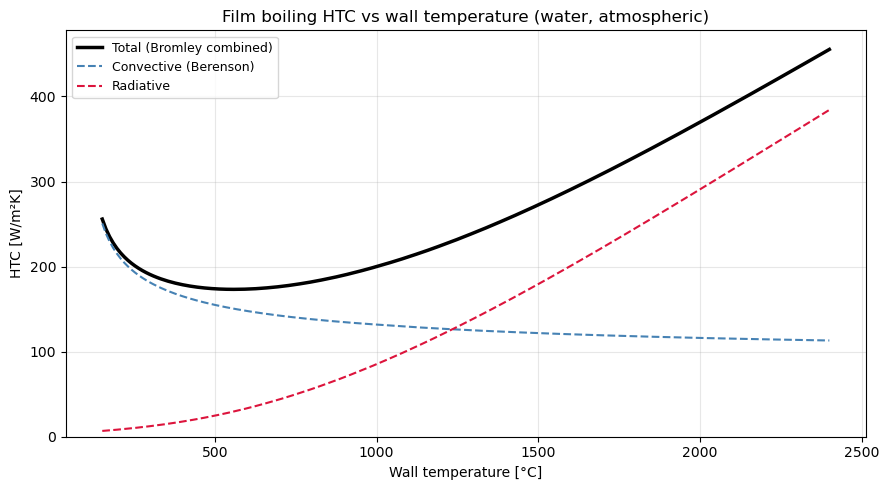

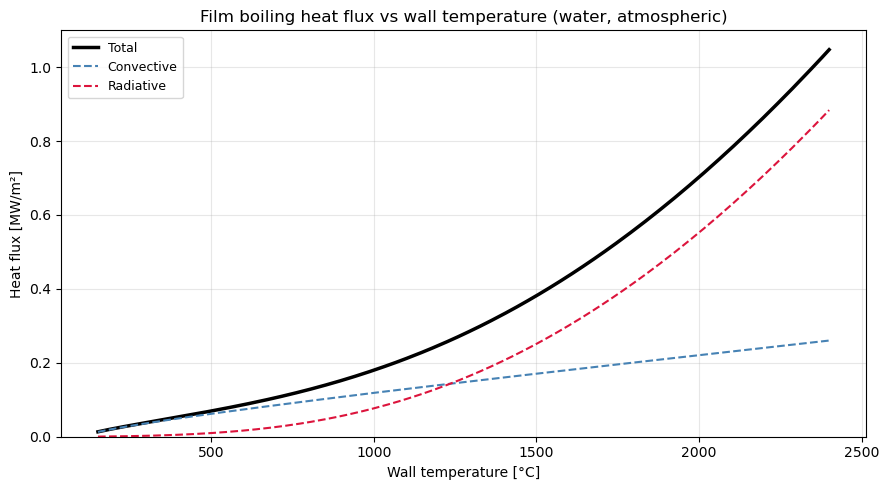

In [44]:
# Film boiling HTC vs wall temperature — convective + radiative breakdown
T_w_arr   = np.linspace(T_sat + 52, 2673, 200)   # just above film-boiling onset to 2400 C
dT_arr    = T_w_arr - T_sat
lam       = np.sqrt(sigma_surf / (g * (rho_l - rho_v)))

h_sup_arr  = np.array([h_superheat(T_sat, T) for T in T_w_arr])
h_conv_arr = 0.425 * (k_v**3 * rho_v * g * (rho_l - rho_v) * (h_fg + 0.4 * h_sup_arr) /
                      (mu_v * dT_arr * lam))**0.25
h_rad_arr  = eps_wall * sigma_sb * (T_w_arr**4 - T_sat**4) / dT_arr
# Apply same steam absorptivity correction used inside film_boiling_htc
if '_alpha_steam_T' in globals() and globals().get('apply_steam_absorptivity', True):
    h_rad_arr *= np.interp(T_w_arr, _alpha_steam_T, _alpha_steam_a)
h_tot_arr  = np.array([film_boiling_htc(T) for T in T_w_arr])

T_C = T_w_arr - 273.15

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(T_C, h_tot_arr,  color='k',         lw=2.5, label='Total (Bromley combined)')
ax.plot(T_C, h_conv_arr, color='steelblue', lw=1.5, ls='--', label='Convective (Berenson)')
ax.plot(T_C, h_rad_arr,  color='crimson',   lw=1.5, ls='--', label='Radiative')
ax.set_xlabel('Wall temperature [°C]')
ax.set_ylabel('HTC [W/m²K]')
ax.set_title('Film boiling HTC vs wall temperature (water, atmospheric)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(T_C, h_tot_arr  * dT_arr / 1e6, color='k',         lw=2.5, label='Total')
ax.plot(T_C, h_conv_arr * dT_arr / 1e6, color='steelblue', lw=1.5, ls='--', label='Convective')
ax.plot(T_C, h_rad_arr  * dT_arr / 1e6, color='crimson',   lw=1.5, ls='--', label='Radiative')
ax.set_xlabel('Wall temperature [°C]')
ax.set_ylabel('Heat flux [MW/m²]')
ax.set_title('Film boiling heat flux vs wall temperature (water, atmospheric)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

In [45]:
rho_Ar_bulk = P_atm * M_Ar / (R * T_bulk)

print('=== Exhaust stack capacity at 1 inH2O gauge (6" stack) ===')
Q_max       = exhaust_Q(P_max_gauge, d_stack_default)
mdot_Ar_max = Q_max * rho_Ar_bulk
mdot_w_equiv = mdot_Ar_max * M_w / M_Ar
Q_w_gpm = mdot_w_equiv / 997 * 264.2 * 60

v_stack = Q_max / (np.pi * d_stack_default**2 / 4)
print(f"  Stack velocity at 1 inH2O:  {v_stack:.2f} m/s")
print(f"  Q_exhaust (volumetric):      {Q_max*1000:.1f} L/s  |  {Q_max*2119:.0f} ACFM")
print(f"  mdot_Ar exhausted:           {mdot_Ar_max*1000:.1f} g/s")
print(f"  Equiv. water leak rate:      {mdot_w_equiv*1000:.2f} g/s  =  {Q_w_gpm:.4f} GPM")
print()
print("Capacity vs stack diameter (at 1 inH2O gauge):")
print(f"  {'d_stack':>8}  {'Q [L/s]':>10}  {'Q [ACFM]':>10}  {'mdot_Ar [g/s]':>14}  {'water equiv [GPM]':>18}")
for d_in in [6, 8, 10, 12, 18, 24]:
    d   = d_in * in_m
    Q   = exhaust_Q(P_max_gauge, d)
    ma  = Q * rho_Ar_bulk
    mw  = ma * M_w / M_Ar
    gpm = mw / 997 * 264.2 * 60
    print(f"  {d_in:>6}\"    {Q*1000:>10.1f}  {Q*2119:>10.0f}  {ma*1000:>14.1f}  {gpm:>18.4f}")

=== Exhaust stack capacity at 1 inH2O gauge (6" stack) ===
  Stack velocity at 1 inH2O:  10.35 m/s
  Q_exhaust (volumetric):      188.8 L/s  |  400 ACFM
  mdot_Ar exhausted:           293.6 g/s
  Equiv. water leak rate:      132.41 g/s  =  2.1053 GPM

Capacity vs stack diameter (at 1 inH2O gauge):
   d_stack     Q [L/s]    Q [ACFM]   mdot_Ar [g/s]   water equiv [GPM]
       6"         188.8         400           293.6              2.1053
       8"         294.5         624           457.8              3.2835
      10"         360.7         764           560.8              4.0216
      12"         394.2         835           612.9              4.3959
      18"         423.4         897           658.3              4.7213
      24"         428.4         908           666.1              4.7773


In [46]:
print("=== Film-boiling limited vaporisation rate ===")
print(f"Hot zone area: {A_hot:.3f} m2")
print(f"  T_inlet = {T_inlet-273.15:.0f} C   dh_subcool = {dh_subcool/1e3:.1f} kJ/kg")
print(f"  h_fg    = {h_fg/1e3:.1f} kJ/kg  (latent, at T_sat = {T_sat-273.15:.0f} C)")
if water_gas_reaction:
    print(f"  H_rxn   = {H_rxn/1e3:.1f} kJ/mol = {H_rxn/M_w/1e3:.0f} kJ/kg H2O  (water-gas, endothermic)")
    print( "  Reaction: C + H2O → CO + H2  (2 mol gas produced per mol H2O consumed)")
else:
    print( "  (steam superheat energy uses NIST Shomate cp_v(T), Berenson 0.4 factor)")
print()

_h_rxn_extra = H_rxn / M_w if water_gas_reaction else 0.0
_last_col_hdr = 'gas_prod [g/s]' if water_gas_reaction else 'equiv GPM'
print(f"  {'T_hot [C]'!s:>12}  {'h_film [W/m2K]'!s:>16}  {'Q_film [kW]'!s:>12}  "
      f"{'h_sup [kJ/kg]'!s:>14}  {'h_eff [kJ/kg]'!s:>14}  {'mdot_w [g/s]'!s:>13}  {_last_col_hdr:>13}")
for T_C in [500, 700, 1000, 1200, 1500, 2000, 2400]:
    T_K   = T_C + 273.15
    h     = film_boiling_htc(T_K)
    dT    = T_K - T_sat
    h_sup = h_superheat(T_sat, T_K)
    h_eff = h_fg + dh_subcool + 0.4 * h_sup + _h_rxn_extra
    Q_f   = h * A_hot * dT
    mdot  = Q_f / h_eff          # kg/s water consumed
    if water_gas_reaction:
        # 1 mol CO + 1 mol H2 per mol H2O → combined mass = (M_CO + M_H2) / M_w * mdot
        gas_gs = mdot * (M_CO + M_H2) / M_w * 1e3
        print(f"  {T_C!s:>12}  {h:>16.0f}  {Q_f/1e3:>12.1f}  "
              f"{h_sup/1e3:>14.1f}  {h_eff/1e3:>14.1f}  {mdot*1e3:>13.2f}  {gas_gs:>13.2f}")
    else:
        gpm_e = mdot / 997 * 264.2 * 60
        print(f"  {T_C!s:>12}  {h:>16.0f}  {Q_f/1e3:>12.1f}  "
              f"{h_sup/1e3:>14.1f}  {h_eff/1e3:>14.1f}  {mdot*1e3:>13.2f}  {gpm_e:>13.4f}")

print()
print("=== liner_break=True: full floor ({:.0f} m\u00b2), wall = T_block (no transient) ===".format(A_floor_break))
print(f"  {'T_hot [C]'!s:>12}  {'h_film [W/m2K]'!s:>16}  {'Q_film [kW]'!s:>12}  "
      f"{'h_sup [kJ/kg]'!s:>14}  {'h_eff [kJ/kg]'!s:>14}  {'mdot_w [g/s]'!s:>13}  {'equiv GPM':>12}")
for T_C in [500, 700, 1000, 1200, 1500, 2000, 2400]:
    T_K   = T_C + 273.15
    h     = film_boiling_htc(T_K)        # wall IS T_block, no liner cool-down
    dT    = T_K - T_sat
    h_sup = h_superheat(T_sat, T_K)
    h_eff = h_fg + dh_subcool + 0.4 * h_sup + _h_rxn_extra
    Q_f   = h * A_floor_break * dT
    mdot  = Q_f / h_eff
    gpm_e = mdot / 997 * 264.2 * 60
    print(f"  {T_C!s:>12}  {h:>16.0f}  {Q_f/1e3:>12.1f}  "
          f"{h_sup/1e3:>14.1f}  {h_eff/1e3:>14.1f}  {mdot*1e3:>13.2f}  {gpm_e:>12.4f}")


=== Film-boiling limited vaporisation rate ===
Hot zone area: 1.978 m2
  T_inlet = 40 C   dh_subcool = 251.3 kJ/kg
  h_fg    = 2262.8 kJ/kg  (latent, at T_sat = 100 C)
  (steam superheat energy uses NIST Shomate cp_v(T), Berenson 0.4 factor)

     T_hot [C]    h_film [W/m2K]   Q_film [kW]   h_sup [kJ/kg]   h_eff [kJ/kg]   mdot_w [g/s]      equiv GPM
           500               174         137.6           813.1          2839.3          48.46         0.7704
           700               176         209.4          1253.7          3015.6          69.44         1.1040
          1000               200         356.0          1966.8          3300.8         107.86         1.7149
          1200               225         489.2          2369.6          3461.9         141.32         2.2470
          1500               273         754.6          2984.5          3707.9         203.52         3.2359
          2000               370        1389.3          4036.2          4128.5         336.51         5

Geometry summary:
  r_ps      = 0.0828 m   A_ps      = 0.8948 m2
  r_lin_in  = 0.1759 m   A_lin_in  = 1.9014 m2
  r_lin_out = 0.1886 m   A_lin_out = 2.0390 m2
  r_blk_in  = 0.6366 m   A_blk_in  = 6.8834 m2
  VF_block->liner_out = 0.2962
  VF_liner_in->PS     = 0.4706
Building spectral tables (one-time)... done

TaC Planck-weighted emissivity by band:
  T=1000C  below-bg: 0.295  above-bg: 0.149  graphite: 0.755
  T=1500C  below-bg: 0.329  above-bg: 0.201  graphite: 0.785
  T=2000C  below-bg: 0.362  above-bg: 0.243  graphite: 0.815
  T=2400C  below-bg: 0.388  above-bg: 0.272  graphite: 0.839


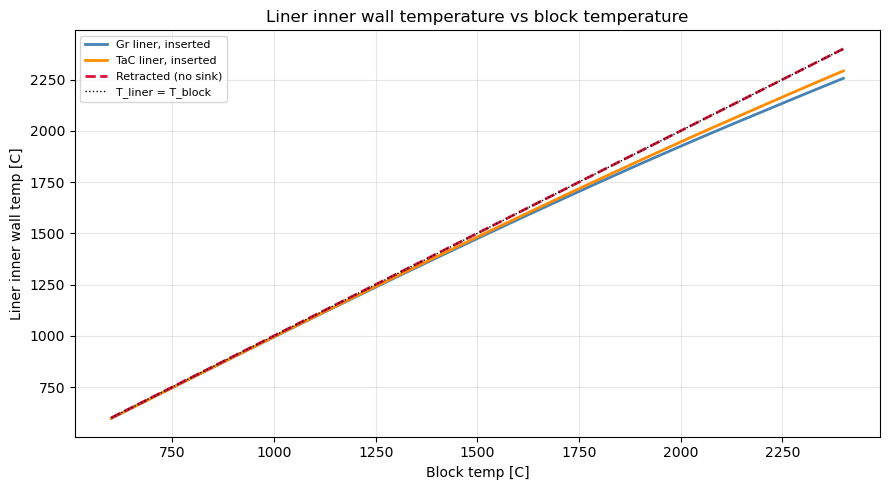

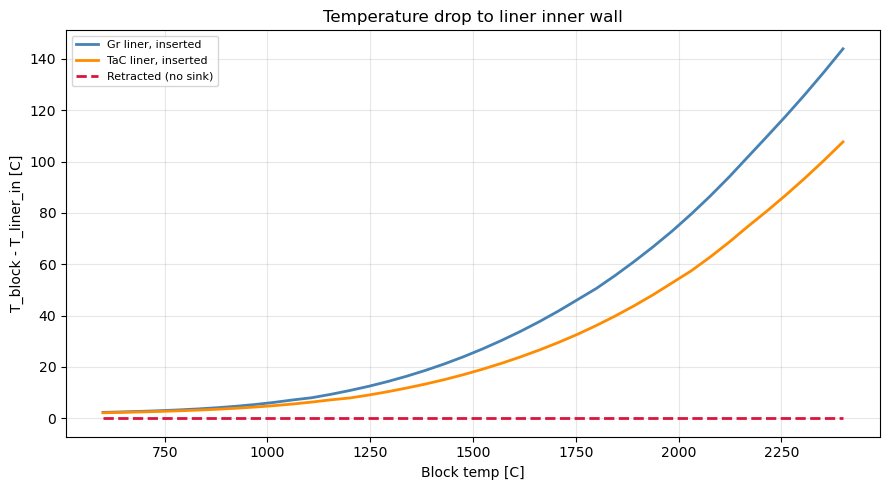

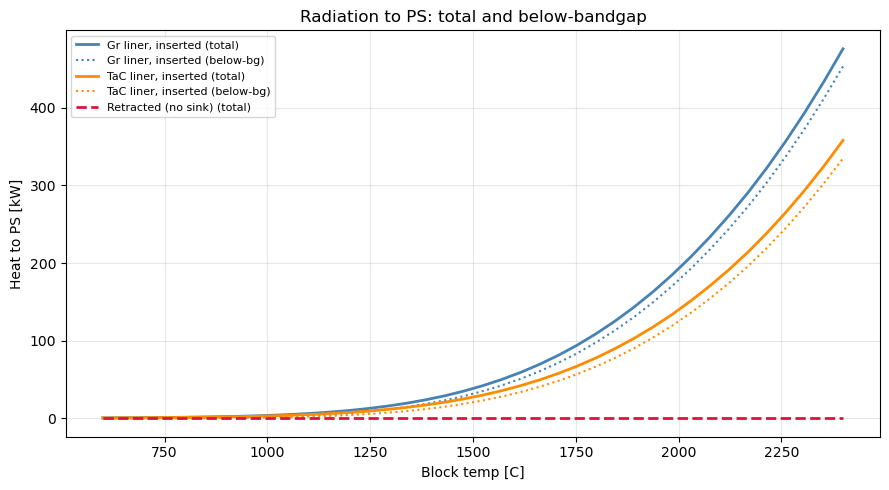


Summary at key block temperatures (stick inserted, water boiling at T_sat):
    T_blk    T_lo Gr    T_li Gr   Q Gr kW    T_lo TaC    T_li TaC    Q TaC kW    Q_bel kW
     1000        995        994      3.59         996         995        2.89        0.96
     1500       1480       1475     38.20        1486        1482       27.19       20.55
     2000       1953       1925    192.50        1966        1946      139.53      124.74
     2400       2330       2256    476.04        2348        2292      358.06      334.83
  Q_bel = below-bandgap power to PS (convertible by cells)


In [47]:
import scipy.optimize as spo
from scipy.integrate import quad

# Geometry (mirroring tinless system model)
PS_side          = 0.13            # m, PS square cross-section
liner_inner_side = W_hz            # m, liner inner = Demo hot zone inner wall (10.875")
liner_th         = 0.01           # m, graphite liner wall thickness
liner_outer_side = liner_inner_side + 2 * liner_th
block_inner_side = 1           # m, block inner cavity (~12") -- adjust as needed

H_lin = H_hz

r_ps      = 2 * PS_side          / np.pi
r_lin_in  = 2 * liner_inner_side / np.pi
r_lin_out = 2 * liner_outer_side / np.pi
r_blk_in  = 2 * block_inner_side / np.pi

A_ps      = 4 * PS_side          * H_lin
A_lin_in  = 4 * liner_inner_side * H_lin
A_lin_out = 4 * liner_outer_side * H_lin
A_blk_in  = 4 * block_inner_side * H_lin

VF_blk_lin = A_lin_out / A_blk_in   # block inner -> liner outer (coaxial)
VF_lin_ps  = A_ps      / A_lin_in   # liner inner -> PS (coaxial)

print('Geometry summary:')
print(f'  r_ps      = {r_ps:.4f} m   A_ps      = {A_ps:.4f} m2')
print(f'  r_lin_in  = {r_lin_in:.4f} m   A_lin_in  = {A_lin_in:.4f} m2')
print(f'  r_lin_out = {r_lin_out:.4f} m   A_lin_out = {A_lin_out:.4f} m2')
print(f'  r_blk_in  = {r_blk_in:.4f} m   A_blk_in  = {A_blk_in:.4f} m2')
print(f'  VF_block->liner_out = {VF_blk_lin:.4f}')
print(f'  VF_liner_in->PS     = {VF_lin_ps:.4f}')

# Material properties (from thermal/properties.py)
def gr_emis_d(T_K):
    return float(np.clip(0.679 + 6e-5 * T_K, 0.0, 1.0))

def gr_tcx_d(T_K):
    Ts = np.array([1000., 1200., 1400., 1600., 1800., 2000., 2200., 2400.])
    ks = np.array([  54.,   49.,   45.,   42.,   40.,   39.,   37.,   34.])
    return float(np.interp(T_K, Ts, ks))

# TaC spectral emissivity -- wavelength lam_um in micrometers (from thermal/properties.py)
def eps_tac(T_K, lam_um):
    return float(np.clip(-0.0351 + 8.15e-5*T_K + (0.3008 - 4.46e-5*T_K)/lam_um, 0.0, 1.0))

# PS emissivity per band (f_bare=0.05, f_active=0.90, from tinless YAML)
_f_bare = 0.05;  _f_act = 0.90
EPS_PS = {
    'below': _f_bare*0.02 + (1-_f_bare)*_f_act*0.90  + (1-_f_bare)*(1-_f_act)*0.02,
    'above': _f_bare*0.02 + (1-_f_bare)*_f_act*0.015 + (1-_f_bare)*(1-_f_act)*0.02,
}

# Spectral integration
LAM_C = 1.24   # um, GaAs bandgap cutoff

def _planck_um(lam_um, T_K):
    h_P=6.626e-34; c0=3e8; kB=1.381e-23
    x = h_P*c0 / (lam_um*1e-6 * kB * T_K)
    return lam_um**-5 / np.expm1(x) if x < 700 else 0.0

def _frac_below(T_K):
    tot, _ = quad(_planck_um, 0.1, 40., args=(T_K,), limit=300)
    bel, _ = quad(_planck_um, 0.1, LAM_C, args=(T_K,), limit=300)
    return bel/tot if tot > 0 else 0.0

def _tac_eps_band_avg(T_K, band):
    # Planck-weighted average TaC emissivity in 'below' or 'above' band
    lam_lo, lam_hi = (0.1, LAM_C) if band == 'below' else (LAM_C, 40.)
    def _Be(lam): return _planck_um(lam, T_K) * eps_tac(T_K, lam)
    tot, _ = quad(_planck_um, lam_lo, lam_hi, args=(T_K,), limit=300)
    num, _ = quad(_Be,        lam_lo, lam_hi,               limit=300)
    return num/tot if tot > 0 else 0.5

print('Building spectral tables (one-time)...', end=' ', flush=True)
_T_tab       = np.linspace(400, 3000, 55)
_fb_tab      = np.array([_frac_below(T)              for T in _T_tab])
_tac_bel_tab = np.array([_tac_eps_band_avg(T,'below') for T in _T_tab])
_tac_abv_tab = np.array([_tac_eps_band_avg(T,'above') for T in _T_tab])
print('done')

def _fb(T_K):
    return float(np.interp(T_K, _T_tab, _fb_tab))

def tac_eps_b(T_K, band):
    tab = _tac_bel_tab if band == 'below' else _tac_abv_tab
    return float(np.interp(T_K, _T_tab, tab))

print('\nTaC Planck-weighted emissivity by band:')
for _T in [1000, 1500, 2000, 2400]:
    print(f'  T={_T}C  below-bg: {tac_eps_b(_T+273.15,"below"):.3f}  '
          f'above-bg: {tac_eps_b(_T+273.15,"above"):.3f}  '
          f'graphite: {gr_emis_d(_T+273.15):.3f}')

# Radiation: block inner wall (gray graphite) -> liner outer face
def Q_rad_blk_lin(T_blk_K, T_lo_K):
    eps_b  = gr_emis_d(T_blk_K)
    eps_lo = gr_emis_d(T_lo_K)
    denom  = (A_lin_out/A_blk_in)*(1/eps_b - 1) + 1/eps_lo
    return A_lin_out * sigma_sb * (T_blk_K**4 - T_lo_K**4) / denom

# Radiation: liner inner wall -> PS, 2-bin spectral model
# Returns (Q_total, Q_below, Q_above) in Watts
def Q_rad_lin_ps(T_li_K, T_ps_K, coated):
    Q_bel = Q_abv = 0.0
    for band, eps_ps in EPS_PS.items():
        eps_l  = tac_eps_b(T_li_K, band) if coated else gr_emis_d(T_li_K)
        fb_lin = _fb(T_li_K) if band == 'below' else 1 - _fb(T_li_K)
        fb_ps  = _fb(T_ps_K) if band == 'below' else 1 - _fb(T_ps_K)
        Eb_l   = sigma_sb * T_li_K**4 * fb_lin
        Eb_ps  = sigma_sb * T_ps_K**4 * fb_ps
        denom  = (A_ps/A_lin_in)*(1/eps_l - 1) + 1/eps_ps
        Qb     = A_ps * (Eb_l - Eb_ps) / denom
        if band == 'below': Q_bel = Qb
        else:               Q_abv = Qb
    return Q_bel + Q_abv, Q_bel, Q_abv

# Energy balance: solve for T_lin_out (and hence T_lin_in) where
#   Q_rad(block->liner_out) = Q_cond(liner) = Q_rad(liner_in->PS)
def liner_temps(T_block_K, stick_inserted=True, coated=False, T_ps_K=323):
    if not stick_inserted:
        return dict(T_lin_out=T_block_K, T_lin_in=T_block_K,
                    Q_tot=0., Q_below=0., Q_above=0.)
    def residual(T_lo):
        Q_in = Q_rad_blk_lin(T_block_K, T_lo)
        T_li = T_lo - Q_in * liner_th / (gr_tcx_d(T_lo) * A_lin_in)
        T_li = max(T_ps_K + 1., T_li)
        Q_out, _, _ = Q_rad_lin_ps(T_li, T_ps_K, coated)
        return Q_in - Q_out
    lo_b, hi_b = T_ps_K + 10., T_block_K - 0.1
    if hi_b <= lo_b or residual(lo_b)*residual(hi_b) > 0:
        return dict(T_lin_out=T_block_K, T_lin_in=T_block_K,
                    Q_tot=0., Q_below=0., Q_above=0.)
    T_lo  = spo.brentq(residual, lo_b, hi_b, xtol=0.5)
    Q_in  = Q_rad_blk_lin(T_block_K, T_lo)
    T_li  = max(T_ps_K + 1., T_lo - Q_in * liner_th / (gr_tcx_d(T_lo) * A_lin_in))
    Q_tot, Q_bel, Q_abv = Q_rad_lin_ps(T_li, T_ps_K, coated)
    return dict(T_lin_out=T_lo, T_lin_in=T_li,
                Q_tot=Q_tot, Q_below=Q_bel, Q_above=Q_abv)

# Convenience: return T_lin_in [K] only (used by demo_liner_cool)
def liner_inner_temp(T_block_K, stick_inserted=True, coated=False, T_ps_K=T_sat):
    return liner_temps(T_block_K, stick_inserted, coated, T_ps_K)['T_lin_in']

# Pre-compute results for all cases
T_blk_arr = np.linspace(600, 2400, 40)
cases = [
    ('Gr liner, inserted',  False, True),
    ('TaC liner, inserted', True,  True),
    ('Retracted (no sink)', False, False),
]
colors_lt = ['steelblue', 'darkorange', 'crimson']
styles_lt  = ['-', '-', '--']

_all = {}
for (lbl, coat, ins), col, ls in zip(cases, colors_lt, styles_lt):
    T_li_l = []; Q_tot_l = []; Q_bel_l = []
    for T_C in T_blk_arr:
        res = liner_temps(T_C+273.15, stick_inserted=ins, coated=coat)
        T_li_l.append(res['T_lin_in'] - 273.15)
        Q_tot_l.append(res['Q_tot'])
        Q_bel_l.append(res['Q_below'])
    _all[lbl] = dict(coat=coat, ins=ins, col=col, ls=ls,
                     T_li=np.array(T_li_l),
                     Q_tot=np.array(Q_tot_l),
                     Q_bel=np.array(Q_bel_l))

# Figure: liner inner wall temperature vs block temperature
fig, ax = plt.subplots(figsize=(9, 5))
for lbl, d in _all.items():
    ax.plot(T_blk_arr, d['T_li'], color=d['col'], ls=d['ls'], lw=2, label=lbl)
ax.plot(T_blk_arr, T_blk_arr, 'k:', lw=1, label='T_liner = T_block')
ax.set_xlabel('Block temp [C]')
ax.set_ylabel('Liner inner wall temp [C]')
ax.set_title('Liner inner wall temperature vs block temperature')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure: temperature drop through liner and radiation gap
fig, ax = plt.subplots(figsize=(9, 5))
for lbl, d in _all.items():
    ax.plot(T_blk_arr, T_blk_arr - d['T_li'], color=d['col'], ls=d['ls'], lw=2, label=lbl)
ax.set_xlabel('Block temp [C]')
ax.set_ylabel('T_block - T_liner_in [C]')
ax.set_title('Temperature drop to liner inner wall')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure: total and below-bandgap radiation to PS
fig, ax = plt.subplots(figsize=(9, 5))
for lbl, d in _all.items():
    ax.plot(T_blk_arr, d['Q_tot']/1e3, color=d['col'], ls=d['ls'], lw=2,
            label=f'{lbl} (total)')
    if d['ins']:
        ax.plot(T_blk_arr, d['Q_bel']/1e3, color=d['col'], ls=':', lw=1.5,
                label=f'{lbl} (below-bg)')
ax.set_xlabel('Block temp [C]')
ax.set_ylabel('Heat to PS [kW]')
ax.set_title('Radiation to PS: total and below-bandgap')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nSummary at key block temperatures (stick inserted, water boiling at T_sat):')
hdr  = f"  {'T_blk':>7}  {'T_lo Gr':>9}  {'T_li Gr':>9}  {'Q Gr kW':>8}  "
hdr += f"{'T_lo TaC':>10}  {'T_li TaC':>10}  {'Q TaC kW':>10}  {'Q_bel kW':>10}"
print(hdr)
for _TC in [1000, 1500, 2000, 2400]:
    rG = liner_temps(_TC+273.15, coated=False)
    rT = liner_temps(_TC+273.15, coated=True)
    print(f"  {_TC:>7}  {rG['T_lin_out']-273.15:>9.0f}  {rG['T_lin_in']-273.15:>9.0f}  "
          f"{rG['Q_tot']/1e3:>8.2f}  "
          f"{rT['T_lin_out']-273.15:>10.0f}  {rT['T_lin_in']-273.15:>10.0f}  "
          f"{rT['Q_tot']/1e3:>10.2f}  {rT['Q_below']/1e3:>10.2f}")
print('  Q_bel = below-bandgap power to PS (convertible by cells)')


Liner mass (4 side walls, 10 mm thick): 34.22 kg
Liner thermal mass:  58.18 kJ/K


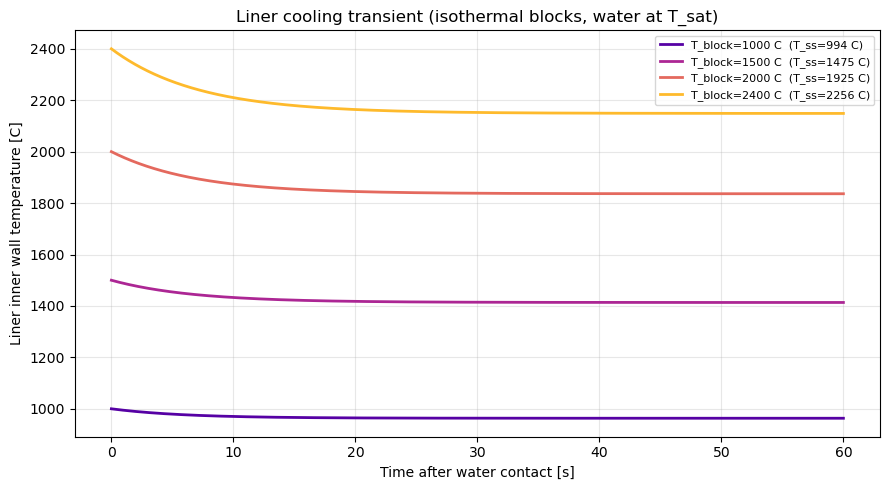

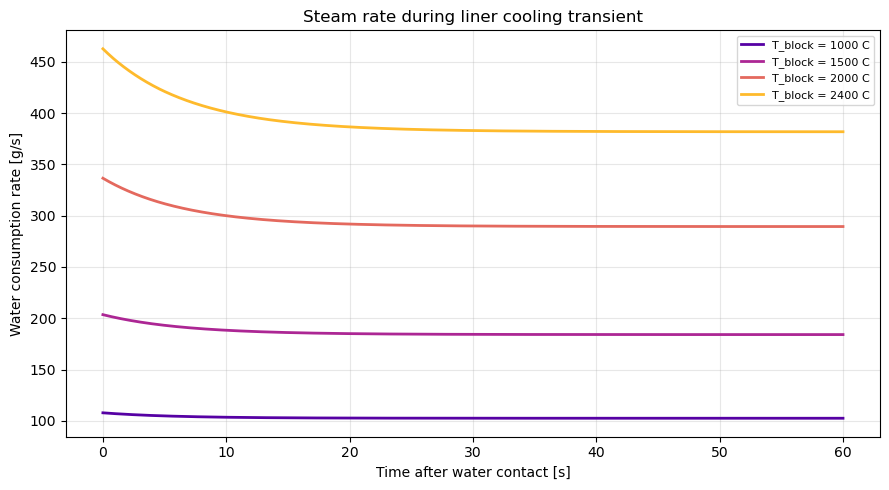


Liner cooling summary:
     T_block    T_lin_ss   tau_lin [s]   mdot_ss [g/s]   mdot_peak [g/s]
        1000         994           6.2          107.00            107.86
        1500        1475           7.1          197.70            203.52
        2000        1925           7.6          314.51            336.51
        2400        2256           8.0          415.73            462.63
  tau = thermal time constant of liner (time to ~63% of steady-state drop)


In [48]:
# Liner thermal mass and cooling transient
# How fast does T_liner_in drop from T_block to steady-state when water suddenly appears?
# Blocks are treated as an isothermal reservoir (worst-case for vaporization, best-case for liner)

rho_gr  = 1800.0   # kg/m3, graphite bulk density
Cp_gr   = 1700.0   # J/(kg*K), graphite specific heat at ~2000 K
m_liner = rho_gr * A_lin_in * liner_th   # kg, thin-wall approx (4 side walls)

print(f"Liner mass (4 side walls, {liner_th*1e3:.0f} mm thick): {m_liner:.2f} kg")
print(f"Liner thermal mass:  {m_liner * Cp_gr / 1e3:.2f} kJ/K")

def sim_liner_transient(T_block_K, t_end=60, n=6000):
    # Start at T_block (no water), water appears at t=0
    T_li = np.empty(n + 1)
    T_li[0] = T_block_K
    dt = t_end / n
    for i in range(n):
        T_i  = T_li[i]
        # Conduction into liner from blocks
        k    = gr_tcx_d(0.5 * (T_block_K + T_i))
        Q_in = k * A_lin_in * (T_block_K - T_i) / liner_th
        # Film boiling heat out from liner inner wall to water
        h_fb  = film_boiling_htc(T_i)
        dT_b  = T_i - T_sat
        Q_out = h_fb * A_hot * dT_b   # use full A_hot (incl. top/bottom) for vaporization
        dTdt  = (Q_in - Q_out) / (m_liner * Cp_gr)
        T_li[i+1] = max(T_sat + 2, T_i + dTdt * dt)
    t = np.linspace(0, t_end, n + 1)
    return t, T_li

T_blocks_c = [1000, 1500, 2000, 2400]
colors_c   = plt.cm.plasma(np.linspace(0.15, 0.85, len(T_blocks_c)))

# Pre-compute transient data for all block temperatures
_transients = {}
for T_C, col in zip(T_blocks_c, colors_c):
    T_K  = T_C + 273.15
    T_ss = liner_inner_temp(T_K)
    t_tr, T_li_tr = sim_liner_transient(T_K)
    _h_rxn_extra = H_rxn / M_w if water_gas_reaction else 0.0
    mdot_arr = np.array([
        film_boiling_htc(Tl) * A_hot * (Tl - T_sat) / (h_fg + dh_subcool + 0.4 * h_superheat(T_sat, Tl) + _h_rxn_extra)
        for Tl in T_li_tr
    ])
    _transients[T_C] = dict(col=col, T_ss=T_ss, t=t_tr,
                             T_li=T_li_tr, mdot=mdot_arr)

# Figure: liner inner wall temperature during cooling transient
fig, ax = plt.subplots(figsize=(9, 5))
for T_C, d in _transients.items():
    ax.plot(d['t'], d['T_li'] - 273.15, color=d['col'], lw=2,
            label=f'T_block={T_C} C  (T_ss={d["T_ss"]-273.15:.0f} C)')
ax.set_xlabel('Time after water contact [s]')
ax.set_ylabel('Liner inner wall temperature [C]')
ax.set_title('Liner cooling transient (isothermal blocks, water at T_sat)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure: steam generation rate during cooling transient
fig, ax = plt.subplots(figsize=(9, 5))
for T_C, d in _transients.items():
    ax.plot(d['t'], d['mdot'] * 1e3, color=d['col'], lw=2, label=f'T_block = {T_C} C')
ax.set_xlabel('Time after water contact [s]')
ax.set_ylabel('Water consumption rate [g/s]')
ax.set_title(('CO+H2 production rate (water-gas reaction)' if water_gas_reaction else 'Steam rate') + ' during liner cooling transient')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Time constants and steady-state summary
print("\nLiner cooling summary:")
print(f"  {'T_block':>10}  {'T_lin_ss':>10}  {'tau_lin [s]':>12}  {'mdot_ss [g/s]':>14}  {'mdot_peak [g/s]':>16}")
for T_C in T_blocks_c:
    T_K   = T_C + 273.15
    T_ss  = liner_inner_temp(T_K)
    k_ss  = gr_tcx_d(0.5 * (T_K + T_ss))
    h_fb  = film_boiling_htc(T_ss)
    dQ_dT = k_ss * A_lin_in / liner_th + h_fb * A_hot
    tau   = m_liner * Cp_gr / dQ_dT
    dT_ss = T_ss - T_sat
    _h_rxn_e = H_rxn / M_w if water_gas_reaction else 0.0
    mdot_ss  = h_fb * A_hot * dT_ss / (h_fg + dh_subcool + 0.4 * h_superheat(T_sat, T_ss) + _h_rxn_e) * 1e3
    h_pk     = film_boiling_htc(T_K)
    dT_pk    = T_K - T_sat
    mdot_pk  = h_pk * A_hot * dT_pk / (h_fg + dh_subcool + 0.4 * h_superheat(T_sat, T_K) + _h_rxn_e) * 1e3
    print(f"  {T_C:>10}  {T_ss-273.15:>10.0f}  {tau:>12.1f}  {mdot_ss:>14.2f}  {mdot_pk:>16.2f}")
print("  tau = thermal time constant of liner (time to ~63% of steady-state drop)")


In [49]:
def simulate(T_block_K, d_stack, stick_inserted=True, coated=False, t_end=120, n=6000,
             m_water_kg=None, liner_break=False, water_shutoff=True):
    """Transient enclosure pressure simulation with finite water supply.

    Simulation stops early once the spill is exhausted AND pressure has dropped
    back below 0.1 inH2O (at least 5 s after supply cutoff).

    Returns
    -------
    t   : array [s]
    Pg  : array [inH2O] gauge pressure
    conc: dict 'H2O', 'CO', 'H2' mole fractions vs time
    """
    if m_water_kg is None:
        m_water_kg = V_spill_gal * gal_m3 * rho_l   # kg, from module-level params

    if liner_break:
        # Catastrophic: water on full floor, wall temperature constant at T_block_K.
        A_evap   = A_floor_break
        _h_fb_lb = film_boiling_htc(T_block_K)
        _dT_b_lb = max(0.0, T_block_K - T_sat)
        _h_sup_lb = h_superheat(T_sat, T_block_K)
    else:
        A_evap = A_hot
        T_li   = liner_inner_temp(T_block_K, stick_inserted=stick_inserted, coated=coated)
        _T_lut = np.linspace(T_sat, T_block_K, 200)
        _h_fb  = np.array([film_boiling_htc(T) for T in _T_lut])
        _h_sup = np.array([h_superheat(T_sat, T) for T in _T_lut])

    dt = t_end / n
    h_rxn_extra = H_rxn / M_w if water_gas_reaction else 0.0

    n_Ar  = P_atm * V_enc / (R * T_bulk)
    n_H2O = 0.0
    n_CO  = 0.0
    n_H2  = 0.0

    Pg     = np.empty(n + 1); Pg[0]     = 0.0
    x_H2O  = np.empty(n + 1); x_H2O[0]  = 0.0
    x_CO   = np.empty(n + 1); x_CO[0]   = 0.0
    x_H2_a = np.empty(n + 1); x_H2_a[0] = 0.0

    m_water_consumed = 0.0
    water_done   = False
    water_done_t = None
    last = n

    for i in range(n):
        if liner_break:
            # No transient: wall fixed at T_block_K, full floor area.
            h_fb  = _h_fb_lb
            dT_b  = _dT_b_lb
            h_sup = _h_sup_lb
        else:
            # ── liner thermal ODE ──────────────────────────────────────────────
            k_li  = gr_tcx_d(0.5 * (T_block_K + T_li))
            Q_in  = k_li * A_lin_in * (T_block_K - T_li) / liner_th
            h_fb  = float(np.interp(T_li, _T_lut, _h_fb))
            dT_b  = max(0.0, T_li - T_sat)
            h_sup = float(np.interp(T_li, _T_lut, _h_sup))
            Q_out = h_fb * A_hot * dT_b
            T_li  = max(T_sat + 2, T_li + (Q_in - Q_out) / (m_liner * Cp_gr) * dt)

        # ── water consumption (zero once supply exhausted) ─────────────────
        if not water_done:
            h_eff  = h_fg + dh_subcool + 0.4 * h_sup + h_rxn_extra
            mdot_w = h_fb * A_evap * dT_b / h_eff if (h_fb > 0 and dT_b > 0) else 0.0
            m_water_consumed += mdot_w * dt
            if water_shutoff and m_water_consumed >= m_water_kg:
                water_done   = True
                water_done_t = (i + 1) * dt
                mdot_w       = 0.0
        else:
            mdot_w = 0.0

        ndot_w = mdot_w / M_w
        if water_gas_reaction:
            ndot_H2O = 0.0;    ndot_CO = ndot_w; ndot_H2 = ndot_w
        else:
            ndot_H2O = ndot_w; ndot_CO = 0.0;   ndot_H2 = 0.0

        # ── enclosure pressure and exhaust ─────────────────────────────────
        n_tot   = n_Ar + n_H2O + n_CO + n_H2
        P_tot   = n_tot * R * T_bulk / V_enc
        P_gauge = max(0.0, P_tot - P_atm)
        Q_ex  = exhaust_Q(P_gauge, d_stack)
        if liner_break:
            Q_ex += exhaust_Q(P_gauge, d_emerg,
                              K_ent_ov=K_ent_emerg, K_exit_ov=K_exit_emerg,
                              d_port_ov=d_emerg)
        ndot_ex = Q_ex * P_tot / (R * T_bulk)

        xH2O_i = n_H2O / n_tot if n_tot > 0 else 0.0
        xCO_i  = n_CO  / n_tot if n_tot > 0 else 0.0
        xH2_i  = n_H2  / n_tot if n_tot > 0 else 0.0
        xAr_i  = 1.0 - xH2O_i - xCO_i - xH2_i

        n_Ar  = max(0.0, n_Ar  - ndot_ex * xAr_i  * dt)
        n_H2O = max(0.0, n_H2O + (ndot_H2O - ndot_ex * xH2O_i) * dt)
        n_CO  = max(0.0, n_CO  + (ndot_CO  - ndot_ex * xCO_i ) * dt)
        n_H2  = max(0.0, n_H2  + (ndot_H2  - ndot_ex * xH2_i ) * dt)
        n_new = n_Ar + n_H2O + n_CO + n_H2

        Pg[i+1]     = max(0.0, n_new * R * T_bulk / V_enc - P_atm) * Pa_inH2O
        x_H2O[i+1]  = n_H2O / n_new if n_new > 0 else 0.0
        x_CO[i+1]   = n_CO  / n_new if n_new > 0 else 0.0
        x_H2_a[i+1] = n_H2  / n_new if n_new > 0 else 0.0

        # ── early stop: water gone and pressure decayed below 0.1 inH2O ───
        # Wait at least 5 s after supply cutoff to capture the peak and decay.
        if (water_done and
                (i + 1) * dt >= water_done_t + 5.0 and
                Pg[i+1] < 0.1):
            last = i + 1
            break

    t = np.linspace(0.0, last * dt, last + 1)
    return t, Pg[:last+1], {'H2O': x_H2O[:last+1],
                             'CO':  x_CO[:last+1],
                             'H2':  x_H2_a[:last+1]}

def ss_pressure(T_block_K, d_in, stick_inserted=True, coated=False):
    # Find liner inner-wall temperature at water-contact steady state: Q_in = Q_out
    T_lo = T_sat + 52.0
    if T_block_K <= T_lo + 1:
        return 0.0
    def heat_balance(T_li):
        k_li  = gr_tcx_d(0.5 * (T_block_K + T_li))
        Q_in  = k_li * A_lin_in * (T_block_K - T_li) / liner_th
        Q_out = film_boiling_htc(T_li) * A_hot * max(0.0, T_li - T_sat)
        return Q_in - Q_out
    try:
        T_li_ss = spo.brentq(heat_balance, T_lo, T_block_K - 0.5, xtol=0.1)
    except ValueError:
        return 0.0
    h       = film_boiling_htc(T_li_ss)
    dT_b    = T_li_ss - T_sat
    if h == 0.0 or dT_b <= 0:
        return 0.0
    h_rxn_extra = H_rxn / M_w if water_gas_reaction else 0.0
    mdot_s  = h * A_hot * dT_b / (h_fg + dh_subcool + 0.4 * h_superheat(T_sat, T_li_ss) + h_rxn_extra)
    # moles of gas generated per second: 2 mol (CO+H2) per mol H2O if reaction, else 1 mol steam
    mol_gas_per_mol_w = 2.0 if water_gas_reaction else 1.0
    d       = d_in * in_m
    A_st    = np.pi * d**2 / 4
    rho_Ar  = P_atm * M_Ar / (R * T_bulk)
    rho_air = P_atm * 0.02897 / (R * T_amb)
    mu_Ar   = CP.PropsSI('V', 'T', T_bulk, 'P', P_atm, 'Argon')
    dP_grav = (rho_Ar - rho_air) * g * L_stack
    v_ss    = mol_gas_per_mol_w * mdot_s * M_Ar / (M_w * A_st * rho_Ar)
    Re      = rho_Ar * v_ss * d / mu_Ar
    f       = _ff(Re, d, roughness_stack)
    K_tot   = f * L_stack / d + K_ent + K_exit
    return (0.5 * rho_Ar * v_ss**2 * K_tot + dP_grav) * Pa_inH2O


In [50]:
# ── Semi-infinite floor thermal model ────────────────────────────────
# Used by simulate_two_zone(floor_transient=True).
# The hot-box floor is modelled as a 1-D semi-infinite wall with
# temperature-dependent k.  Film boiling extracts heat at x=0 (Robin BC);
# the far boundary is held at the initial block temperature (semi-infinite).
#
# k(T) = 8.562e-8 T^2 + 7.907e-5 T + 0.0846  W/(m K),  T in Celsius
#
# Explicit finite-difference scheme (stable because simulation dt << FD
# stability limit for these material properties).

def k_floor(T_C):
    """Floor k [W/m/K], T in Celsius (vectorized)."""
    return 8.562e-8*T_C**2 + 7.907e-5*T_C + 0.0846

# ─── Floor material parameters — update as needed ────────────────────────
FLOOR_RHO   = 170.0   # kg/m³  — floor material density
FLOOR_CP    = 2000.0    # J/kg/K — floor specific heat
FLOOR_DEPTH = 0.30     # m      — FD domain depth (> 10× thermal penetration depth)
FLOOR_N     = 100      # nodes  — dx = FLOOR_DEPTH / FLOOR_N

def _floor_step(T_floor, h_fb, dt, dx):
    """Explicit 1-D FD step for the semi-infinite floor.

    Parameters
    ----------
    T_floor : ndarray [K]  temperature profile, length FLOOR_N
    h_fb    : float  [W/m^2/K]  film-boiling HTC at floor surface
    dt      : float  [s]  timestep
    dx      : float  [m]  node spacing

    Boundary conditions
    -------------------
    x=0   : Robin  q_surf = h_fb * (T_s - T_sat)  (film boiling)
    x=L   : Dirichlet T = T_floor[-1] = T_block_K  (semi-infinite)
    """
    T_new = T_floor.copy()
    T_C   = T_floor - 273.15
    k_f   = k_floor(T_C)               # k at each node [W/m/K]
    k_if  = 0.5 * (k_f[:-1] + k_f[1:])  # k at N-1 interfaces

    # Surface half-cell (j=0) — semi-implicit Robin BC
    # Implicit in T_new[0], explicit in T[1]: unconditionally stable at any h_fb,
    # including the high HTCs in nucleate boiling (~50 kW/m2/K).
    q_cond   = k_if[0] * (T_floor[1] - T_floor[0]) / dx    # from depth (explicit)
    _Cdx2    = FLOOR_RHO * FLOOR_CP * 0.5 * dx
    T_new[0] = (T_floor[0] + dt / _Cdx2 * (q_cond + h_fb * T_sat)) / (1.0 + h_fb * dt / _Cdx2)
    T_new[0] = max(T_new[0], T_sat)   # can't cool below saturation

    # Interior nodes (vectorized)
    q_lo = k_if[:-1] * (T_floor[:-2] - T_floor[1:-1]) / dx
    q_hi = k_if[1:]  * (T_floor[2:]  - T_floor[1:-1]) / dx
    T_new[1:-1] = T_floor[1:-1] + dt / (FLOOR_RHO * FLOOR_CP * dx) * (q_lo + q_hi)

    # Far boundary: fixed at T_block_K (semi-infinite assumption)
    T_new[-1] = T_floor[-1]
    return T_new


def _wall_step(T_wall, T_sink, dt, dx, eps=eps_wall):
    """Semi-infinite FD step for hot-box walls; surface radiates to gas at T_sink (=T_h).
    BC linearized around T_wall[0]^n for unconditional stability (no explicit T^4).
    """
    T_new = T_wall.copy()
    T_C   = T_wall - 273.15
    k_f   = k_floor(T_C)
    k_if  = 0.5 * (k_f[:-1] + k_f[1:])

    # Surface half-cell: linearized implicit radiative BC
    #   T_new^4 approx 4*T0^3*T_new - 3*T0^4  =>  effective h_lin = 4*eps*sigma*T0^3
    _T0   = T_wall[0]
    q_cond = k_if[0] * (T_wall[1] - T_wall[0]) / dx
    _Cdx2 = FLOOR_RHO * FLOOR_CP * 0.5 * dx
    _denom = _Cdx2 / dt + 4.0 * eps * sigma_sb * _T0**3
    _numer = _Cdx2 / dt * _T0 + q_cond + eps * sigma_sb * (3.0 * _T0**4 + T_sink**4)
    T_new[0] = max(_numer / _denom, T_sink)

    # Interior nodes (vectorized, explicit)
    q_lo = k_if[:-1] * (T_wall[:-2] - T_wall[1:-1]) / dx
    q_hi = k_if[1:]  * (T_wall[2:]  - T_wall[1:-1]) / dx
    T_new[1:-1] = T_wall[1:-1] + dt / (FLOOR_RHO * FLOOR_CP * dx) * (q_lo + q_hi)

    T_new[-1] = T_wall[-1]
    return T_new


# Quick sanity check
_f_alpha = k_floor(500) / (FLOOR_RHO * FLOOR_CP)
_f_dx    = FLOOR_DEPTH / FLOOR_N
print(f"Floor model: k(500°C)={k_floor(500):.4f} W/m/K  "
      f"ρ={FLOOR_RHO:.0f} kg/m³  cp={FLOOR_CP:.0f} J/kg/K")
print(f"  α(500°C) = {_f_alpha:.2e} m²/s  |  dx = {_f_dx*1e3:.1f} mm")
print(f"  Thermal penetration at 60 s: ~{2*np.sqrt(_f_alpha*60)*100:.1f} cm  "
      f"(domain = {FLOOR_DEPTH*100:.0f} cm  → semi-infinite OK)")
_fo = _f_alpha * 0.005 / _f_dx**2   # Fourier number per timestep (dt=0.005 s)

T_WGR_MIN = 873.15   # K (600°C) — kept for reference; table below captures full range
                     # C(s)+H₂O → CO+H₂ equilibrium cracking fraction vs temperature:
_WGR_T_C  = np.array([100, 200, 300, 400, 500,   600,   700,   800,   900,  1000,  1100,  1200], dtype=float)
_WGR_FRAC = np.array([2e-6, 1.9e-4, 3.7e-3, 0.030, 0.144, 0.437, 0.786, 0.941, 0.983, 0.994, 0.998, 0.999])
# np.interp(T_C, _WGR_T_C, _WGR_FRAC, left=0.0, right=1.0) gives fraction cracked at any T
print(f"  Explicit FD Fo/step = {_fo:.4f}  (must be < 0.5 for stability)")


Floor model: k(500°C)=0.1455 W/m/K  ρ=170 kg/m³  cp=2000 J/kg/K
  α(500°C) = 4.28e-07 m²/s  |  dx = 3.0 mm
  Thermal penetration at 60 s: ~1.0 cm  (domain = 30 cm  → semi-infinite OK)
  Explicit FD Fo/step = 0.0002  (must be < 0.5 for stability)


In [51]:
# -- Nucleate / transition boiling model ------------------------------------------
# Completes the boiling curve below the Leidenfrost point (~300 C wall).
# Rohsenow (1952) nucleate pool boiling + Zuber (1958) critical heat flux.
# Transition boiling is bridged by log-linear q interpolation between the
# Leidenfrost and CHF anchor points.

# Surface-fluid constant C_sf for Rohsenow correlation:
#   water on copper ~ 0.006  |  water on steel ~ 0.013  |  default ~ 0.013
ROHSENOW_CSF = 0.013

# Liquid water properties at T_sat (CoolProp)
_mu_l_sat  = CP.PropsSI("V",       "T", T_sat - 1, "P", P_boil, "Water")  # Pa*s
_cp_l_sat  = CP.PropsSI("C",       "T", T_sat - 1, "P", P_boil, "Water")  # J/kg/K
_Pr_l_sat  = CP.PropsSI("Prandtl", "T", T_sat - 1, "P", P_boil, "Water")

# Critical heat flux: Zuber (1958)
_q_chf = (0.131 * h_fg * rho_v
          * (sigma_surf * g * (rho_l - rho_v) / rho_v**2)**0.25)

# Rohsenow coefficient: q_nb = _A_roh * dT^3
_A_roh = (_mu_l_sat * h_fg
           * np.sqrt(g * (rho_l - rho_v) / sigma_surf)
           * (_cp_l_sat / (ROHSENOW_CSF * h_fg * _Pr_l_sat))**3)

# dT at CHF: invert Rohsenow -> dT_CHF = (q_chf / _A_roh)^(1/3)
dT_CHF = (_q_chf / _A_roh)**(1.0 / 3.0)
T_CHF  = T_sat + dT_CHF     # K -- wall temp at peak nucleate boiling

# Leidenfrost: film -> transition boundary (~300 C)
dT_LEID = 200.0
T_LEID  = T_sat + dT_LEID   # K

# Heat flux at Leidenfrost from the film-boiling side (log-linear anchor)
_q_leid = film_boiling_htc(T_LEID) * dT_LEID

print(f"Nucleate boiling setup (Rohsenow, C_sf = {ROHSENOW_CSF}):")
print(f"  CHF      = {_q_chf/1e6:.2f} MW/m2   at  dT_CHF = {dT_CHF:.1f} K  "
      f"(T_wall ~ {T_CHF - 273.15:.0f} C)")
print(f"  h at CHF = {_q_chf/dT_CHF/1e3:.1f} kW/m2/K   "
      f"(film-boiling at same T: {film_boiling_htc(T_CHF):.0f} W/m2/K)")
print(f"  Leidenfrost: T_wall = {T_LEID - 273.15:.0f} C   q = {_q_leid/1e3:.0f} kW/m2")


def nucleate_boiling_htc(dT):
    return _A_roh * dT**2 if dT > 0 else 0.0


def boiling_htc(T_wall_K):
    dT = T_wall_K - T_sat
    if dT <= 0:
        return 0.0
    if T_wall_K > T_LEID:
        return film_boiling_htc(T_wall_K)
    if T_wall_K > T_CHF:
        frac  = (T_LEID - T_wall_K) / (T_LEID - T_CHF)
        log_q = np.log(_q_leid) + frac * (np.log(_q_chf) - np.log(_q_leid))
        return np.exp(log_q) / dT
    return nucleate_boiling_htc(dT)


Nucleate boiling setup (Rohsenow, C_sf = 0.013):
  CHF      = 1.11 MW/m2   at  dT_CHF = 20.1 K  (T_wall ~ 120 C)
  h at CHF = 55.1 kW/m2/K   (film-boiling at same T: 0 W/m2/K)
  Leidenfrost: T_wall = 300 C   q = 38 kW/m2


In [52]:
# ── Two-zone hot/cold zone pressure model ─────────────────────────────────────
# Hot zone : 101" tall, A_floor_break floor, initially Ar at T_block_K, 1 bar.
# Cold zone: rest of enclosure, initially Ar at 40 C, 1 bar.
# Orifice  : 1 ft x 1 ft square at top of hot zone (Cd = 0.61).
# Temperature: Cv-based mixing (no compression/flow-work term).
#   Hot zone  : isothermal at T_block_K.
#   Cold zone : split into mixed (upper, near orifice/exhaust) and unmixed (lower).
#     T_mix   follows instant Cv mixing applied to f_mix fraction of cold moles.
#     T_unmix relaxes toward T_mix with time constant tau_unmix.
#     Pressure uses harmonic-weighted average of T_mix and T_unmix.
#     Exhaust uses T_mix (buoyancy and density at actual exhaust-zone temperature).

H_hot_2z   = 101 * in_m
A_fl_2z    = A_floor_break
V_hot_2z   = A_fl_2z * H_hot_2z
V_cold_2z  = V_enc - V_hot_2z

T_cold_2z  = 313.15   # K, 40 C initial cold zone temperature

_side_hz   = np.sqrt(A_fl_2z)
A_walls_hz = 4 * _side_hz * H_hot_2z
A_ceil_hz  = A_fl_2z

A_ori     = (1 * ft_m)**2           # base orifice at floor break [m2]
A_rad_hz   = A_walls_hz + (A_ceil_hz - A_ori)  # 4 side walls + ceiling minus orifice
A_6in_ori = np.pi * (0.625 * in_m)**2   # one 1.25-inch diameter wall orifice [m2]
Cd_ori    = 0.61                     # sharp-edged orifice (valid for D_h >> t_wall)
L_seam_hz = 4 * H_hot_2z + 4 * _side_hz   # total seam length: 4 vert edges + ceiling perimeter [m]
ft3_m3  = ft_m**3

Cv_Ar  = 1.5 * R;  Cv_CO  = 2.5 * R
Cv_H2  = 2.5 * R;  Cv_H2O = 3.0 * R

print(f"Hot zone:   V = {V_hot_2z:.2f} m3  A_floor = {A_fl_2z:.1f} m2  H = {H_hot_2z:.3f} m")
print(f"Cold zone:  V = {V_cold_2z:.2f} m3")
print(f"Orifice:    {A_ori:.5f} m2  ({A_ori/in_m**2:.2f} in2)  Cd = {Cd_ori}")
print(f"Side walls: {A_walls_hz:.2f} m2  (4 x {_side_hz:.2f} m x {H_hot_2z:.3f} m)")
print(f"Rad area:   {A_rad_hz:.2f} m2  (walls + ceiling - orifice)")

def _seam_flow_Q(dP, rho, mu, w, t, L):
    """Volumetric flow [m3/s] through seam gaps (total edge length L).

    Loss model: sharp-edged entry (K=0.5) + Darcy pipe friction (f*t/D_h) + exit (K=1.0).
    D_h = 2wt/(w+t) is the hydraulic diameter of the rectangular w x t slot cross-section.
    Laminar (Re<2300): analytical quadratic solution.
    Turbulent (Re>=2300): iterative Blasius.
    """
    if w <= 0 or dP <= 0 or rho <= 0:
        return 0.0
    D_h = 2.0 * w * t / (w + t)       # hydraulic diameter of slot cross-section [m]
    A   = w * L                        # total seam flow area [m2]
    # Laminar energy balance: 1.5*rho*v^2 + (64*mu*t/D_h^2)*v - 2*dP = 0  (quadratic in v)
    a_q =  1.5 * rho
    b_q =  64.0 * mu * t / max(D_h**2, 1e-20)
    c_q = -2.0 * dP
    v   = (-b_q + np.sqrt(max(b_q*b_q - 4.0*a_q*c_q, 0.0))) / (2.0 * a_q)
    Re  = rho * v * D_h / max(mu, 1e-12)
    if Re > 2300:                      # turbulent: iterate Blasius f
        K = 1.5 + 0.316 / max(Re, 1.0)**0.25 * (t / D_h)
        for _ in range(15):
            v   = np.sqrt(2.0 * dP / max(rho * K, 1e-20))
            Re  = rho * v * D_h / max(mu, 1e-12)
            K_n = 1.5 + 0.316 / max(Re, 0.1)**0.25 * (t / D_h)
            if abs(K_n - K) < 1e-5 * K:
                break
            K = K_n
    return v * A


def simulate_two_zone(T_block_K, d_stack, t_end=180, n=9000,
                      m_water_kg=None, water_shutoff=True, ramp_time=1.0,
                      regime_ramp_t=1.0,
                      f_mix=0.5, tau_mix=2.0, tau_unmix=10.0,
                      chiller_on=False, Q_chiller_W=400e3,
                      Pg_bf_setpoint=-0.1, chiller_Kp=1.0, chiller_Ki=0.5, chiller_Kd=2.0, chiller_tau_d=2.0, chiller_ramp_rate=0.1, chiller_tt=5.0,
                      floor_transient=False,
          Q_backfill_cfm=0.0,
          n_extra_ori=0, seam_width=0.0, t_wall=0.5*in_m,
                      exhaust_crack_inH2O=0.3, exhaust_close_inH2O=0.28,
                      exhaust_louver_dP_inH2O=0.15):
    """Two-zone transient: hot zone (isothermal) + cold zone (two-temperature model).

    Cold zone is split into a mixed sub-zone (upper f_mix fraction, near orifice
    and exhaust) and an unmixed sub-zone (lower 1-f_mix fraction).  T_mix follows
    the Cv mixing formula applied to f_mix of the cold moles; T_unmix relaxes
    toward T_mix with time constant tau_unmix.  Pressure uses the harmonic-weighted
    average temperature (exact for connected ideal-gas zones at uniform pressure).
    Exhaust flow sees T_mix so buoyancy reflects actual exhaust-zone temperature.

    Parameters
    ----------
    ramp_time     : float  Seconds to ramp water flow from 0 to max (0 = instant).
    regime_ramp_t : float  Seconds to blend HTC across each boiling regime
                           transition (0 = instantaneous full-floor switch).
    f_mix      : float  Fraction of cold zone volume in the mixed sub-zone (0-1).
    tau_mix    : float  Internal mixing time of the mixed zone [s] -- ensures it
                        is treated as well-mixed; must be << transient duration.
    tau_unmix  : float  Time constant for unmixed zone to follow mixed zone [s].
    chiller_on : bool   If True, remove Q_chiller_W from the cold zone each step.
    Q_chiller_W: float  Chiller heat removal rate [W], default 400 kW.

    Returns
    -------
    t, Pg_hot, Pg_cold, dP_Pa, loads, conc, Tc_avg, flows
    Tc_avg : ndarray [C]  harmonic-mean cold zone temperature (used for pressure)
    flows  : dict  {Qori [m3/s], Qex [m3/s], T_mix [C], T_unmix [C]}
    """
    if m_water_kg is None:
        m_water_kg = V_spill_gal * gal_m3 * rho_l

    h_fb  = film_boiling_htc(T_block_K)
    dT_b  = max(0.0, T_block_K - T_sat)
    h_sup = h_superheat(T_sat, T_block_K)
    _f_crack_init = (float(np.interp(T_block_K - 273.15, _WGR_T_C, _WGR_FRAC,
                                      left=0.0, right=1.0))
                     if water_gas_reaction else 0.0)
    h_rxn    = _f_crack_init * H_rxn / M_w
    h_eff    = h_fg + dh_subcool + 0.4 * h_sup + h_rxn
    mdot_max = h_fb * A_fl_2z * dT_b / h_eff if (h_fb > 0 and dT_b > 0) else 0.0

    # Temperature of gas leaving the floor: weighted by cracking fraction.
    # CO+H2 path absorbs 0.4*h_sup over 7R/mol-K (diatomic mixture);
    # steam path absorbs 0.4*h_sup over Cp_steam (h_sup/dT_b per kg).
    if dT_b > 0:
        _Tg_crack = T_sat + 0.4 * h_sup * M_w / (7.0 * R)
        _Tg_steam = T_sat + 0.4 * dT_b
        T_gas_K   = _f_crack_init * _Tg_crack + (1.0 - _f_crack_init) * _Tg_steam
    else:
        T_gas_K = T_sat

    # ── Wall-to-floor view factor and steam absorptivity ────────────────────
    # Analytical view factor for square enclosure (L x L x H):
    #   F_floor->ceiling via the equal-parallel-rectangles formula, then
    #   reciprocity A_floor*F_fc_inv = A_4walls*F_4walls->floor.
    # Wall radiation heats the steam/gas filling the hot zone (VF walls->gas ~ 1).
    # Alpha_steam = Planck-weighted absorptivity for mean room half-width path.
    _L_wall_path = 0.5 * np.sqrt(A_fl_2z)
    _aT_g = globals().get('_alpha_steam_T')
    if _aT_g is not None and globals().get('apply_steam_absorptivity', True):
        print(f"  Wall->gas steam LUT (path={_L_wall_path:.2f} m)...", end=' ', flush=True)
        _alpha_sw = np.array([_steam_alpha_planck(T, _L_wall_path) for T in _aT_g])
        _alpha_sw_0 = float(np.interp(T_block_K, _aT_g, _alpha_sw))
        print(f"done  alpha={_alpha_sw_0:.3f} at {T_block_K-273.15:.0f}°C "
              f"({1-_alpha_sw_0:.3f} transmitted)")
    else:
        _alpha_sw = None

    # ── Floor FD grid (floor_transient=True only) ───────────────────────────
    if floor_transient:
        _f_dx    = FLOOR_DEPTH / FLOOR_N
        T_floor  = np.full(FLOOR_N, float(T_block_K))
        # Pre-compute LUT so h_superheat / film_boiling_htc aren't called each step
        # Non-uniform LUT: dense in transition region (T_CHF to T_LEID)
        _ft_lut    = np.sort(np.unique(np.concatenate([
            np.linspace(T_sat + 0.05, T_CHF * 0.999, 80),
            np.linspace(T_CHF,        T_LEID,         100),
            np.linspace(T_LEID * 1.001, T_block_K,   200),
        ])))
        _fhsup_lut = np.array([h_superheat(T_sat, T) for T in _ft_lut])
        _fhfb_lut  = np.array([boiling_htc(T) for T in _ft_lut])
        print(f"  floor_transient: LUT built ({len(_ft_lut)} pts), "
              f"dx={_f_dx*1e3:.1f} mm, ρ={FLOOR_RHO} kg/m³, cp={FLOOR_CP} J/kg/K")
        _boiling_regime  = 0
        _radial_active   = False
        _t_leid_cross    = -1.0
        _ring_T          = None
        _ring_area       = None
        _ring_freeze_end = None
        _h_1pct_chf      = 0.01 * float(np.interp(T_CHF, _ft_lut, _fhfb_lut))
        _N_RINGS         = 101
        _T_s_trigger     = T_block_K
        T_wall = np.full(FLOOR_N, float(T_block_K))   # wall FD (radiation BC)
    n_Ar_h = P_atm * V_hot_2z  / (R * T_block_K)
    n_CO_h = 0.0;  n_H2_h = 0.0;  n_H2O_h = 0.0
    T_h    = T_block_K
    simulate_two_zone._dbg_bf = False

    n_Ar_c = P_atm * V_cold_2z / (R * T_cold_2z)
    n_CO_c = 0.0;  n_H2_c = 0.0;  n_H2O_c = 0.0

    # Two-temperature cold zone state
    T_mix   = T_cold_2z   # mixed sub-zone (upper, near orifice + exhaust)
    T_unmix = T_cold_2z   # unmixed sub-zone (lower)

    dt = t_end / n
    Pg_hot   = np.zeros(n + 1)
    Pg_cold  = np.zeros(n + 1)
    dP_arr   = np.zeros(n + 1)
    xCO_c    = np.zeros(n + 1)
    xH2_c    = np.zeros(n + 1)
    xH2O_c   = np.zeros(n + 1)
    xH2O_h_a = np.zeros(n + 1)   # hot-zone steam mole fraction
    xH2_h_a  = np.zeros(n + 1)
    n_Ar_h_a  = np.zeros(n + 1);  n_Ar_h_a[0]  = n_Ar_h
    n_CO_h_a  = np.zeros(n + 1)
    n_H2_h_a  = np.zeros(n + 1)
    n_H2O_h_a = np.zeros(n + 1)
    n_Ar_c_a  = np.zeros(n + 1);  n_Ar_c_a[0]  = n_Ar_c
    n_CO_c_a  = np.zeros(n + 1)
    n_H2_c_a  = np.zeros(n + 1)
    n_H2O_c_a = np.zeros(n + 1)
    cum_H2O_in_a  = np.zeros(n + 1)
    cum_ex_Ar_a   = np.zeros(n + 1)
    cum_ex_H2_a   = np.zeros(n + 1)
    cum_ex_CO_a   = np.zeros(n + 1)
    cum_ex_H2O_a  = np.zeros(n + 1)
    Tcavg_a  = np.zeros(n + 1);  Tcavg_a[0]  = T_cold_2z - 273.15
    Tmix_a   = np.zeros(n + 1);  Tmix_a[0]   = T_cold_2z - 273.15
    Tunmix_a = np.zeros(n + 1);  Tunmix_a[0] = T_cold_2z - 273.15
    Qori_a   = np.zeros(n + 1)
    Qex_a    = np.zeros(n + 1)
    Th_a     = np.zeros(n + 1);  Th_a[0]     = T_block_K - 273.15
    Tsurf_a  = np.zeros(n + 1);  Tsurf_a[0]  = T_block_K - 273.15
    heff_a   = np.zeros(n + 1)
    Qchill_a = np.zeros(n + 1)
    Twall_a  = np.zeros(n + 1);  Twall_a[0]  = T_block_K - 273.15
    m_used_a = np.zeros(n + 1)

    _bf_ndot = Q_backfill_cfm * ft3_m3 / 60.0 * P_atm / (R * 293.15)
    _chiller_frac      = 1.0
    _chiller_frac_prev = 1.0
    _exhaust_on        = False
    _control_active    = False
    _integral_e     = 0.0
    _e_prev         = 0.0
    _Pg_filt        = Pg_bf_setpoint
    _bf_print_t     = -99.0
    m_used = 0.0;  water_done = False;  wt_t = None
    last = n

    for i in range(n):
        if floor_transient:
            _T_s       = float(T_floor[0])
            _h_fb_surf = float(np.interp(_T_s, _ft_lut, _fhfb_lut))

            # ── Activate radial ring model at first Leidenfrost crossing ──
            if not _radial_active and _t_leid_cross < 0 and _h_fb_surf >= _h_1pct_chf:
                _t_leid_cross    = (i + 1) * dt
                _T_s_trigger     = _T_s
                _R_o             = np.sqrt(A_fl_2z / np.pi)
                _dr              = _R_o / _N_RINGS
                _ring_area       = np.array([
                    np.pi * ((k + 1) * _dr)**2 - np.pi * (k * _dr)**2
                    for k in range(_N_RINGS)])
                _ring_freeze_end = np.array([
                    _t_leid_cross + regime_ramp_t * k / (_N_RINGS - 1)
                    for k in range(_N_RINGS)])
                _ring_T          = [T_floor.copy() for _ in range(_N_RINGS)]
                _radial_active   = True
                print(f"  [{T_block_K-273.15:.0f}C] radial floor: activated at "
                      f"t={_t_leid_cross:.1f}s  T_s={_T_s_trigger-273.15:.0f}C  "
                      f"h={_h_fb_surf:.0f} W/m2/K  R_o={_R_o:.2f}m  "
                      f"dr={_dr:.3f}m  ramp_t={regime_ramp_t}s")

            # ── Regime change notification (lumped T_s) ───────────────────
            _new_regime = 0 if _T_s >= T_LEID else (1 if _T_s >= T_CHF else 2)
            if _new_regime != _boiling_regime:
                _rname   = {0: 'film', 1: 'transition', 2: 'nucleate'}
                n_h      = n_Ar_h + n_CO_h + n_H2_h + n_H2O_h   # not yet set on the first step
                _xWh_now = n_H2O_h / n_h if n_h > 0 else 0.0
                _Tw_now  = float(T_wall[0]) - 273.15
                _Ph_pr   = n_h * R * T_h / V_hot_2z
                _nc_pr   = n_Ar_c + n_CO_c + n_H2_c + n_H2O_c
                _Tch_pr  = 1.0 / (f_mix / max(T_mix, 1.0) + (1.0 - f_mix) / max(T_unmix, 1.0))
                _Pc_pr   = _nc_pr * R * _Tch_pr / V_cold_2z
                _Pgh_pr  = (_Ph_pr - P_atm) * Pa_inH2O
                _Pgc_pr  = (_Pc_pr - P_atm) * Pa_inH2O
                print(f"  [{T_block_K-273.15:.0f}C block] floor: "
                      f"{_rname[_boiling_regime]} -> {_rname[_new_regime]} boiling "
                      f"at t={(i+1)*dt:.1f} s  (T_surf={_T_s-273.15:.0f}C  "
                      f"T_wall={_Tw_now:.0f}C  xH2O_h={_xWh_now*100:.1f}%  "
                      f"n_h={n_h:.0f} mol  T_h={T_h-273.15:.0f}C  "
                      f"Pg_h={_Pgh_pr:.2f} Pg_c={_Pgc_pr:.2f} inH2O)")
                _boiling_regime = _new_regime

            if _radial_active:
                # ── Radial model: advance each ring, sum heat fluxes ─────
                _t_now   = (i + 1) * dt
                _Q_total = 0.0
                _hA_sum  = 0.0
                _TA_sum  = 0.0
                for _k in range(_N_RINGS):
                    if water_done:
                        _ring_T[_k] = _floor_step(_ring_T[_k], 0.0, dt, _f_dx)
                        _T_sk = float(_ring_T[_k][0])
                        _h_k  = 0.0
                    elif _t_now < _ring_freeze_end[_k]:
                        _T_sk = _T_s_trigger
                        _h_k  = float(np.interp(_T_s_trigger, _ft_lut, _fhfb_lut))
                    else:
                        _h_prev     = float(np.interp(float(_ring_T[_k][0]),
                                                      _ft_lut, _fhfb_lut))
                        _ring_T[_k] = _floor_step(_ring_T[_k], _h_prev, dt, _f_dx)
                        _T_sk = float(_ring_T[_k][0])
                        _h_k  = float(np.interp(_T_sk, _ft_lut, _fhfb_lut))
                    _Q_total += _h_k * _ring_area[_k] * max(0.0, _T_sk - T_sat)
                    _hA_sum  += _h_k * _ring_area[_k]
                    _TA_sum  += _T_sk * _ring_area[_k]

                _h_fb_surf = _hA_sum / A_fl_2z
                _T_s_avg   = _TA_sum / A_fl_2z
                T_floor[0] = _T_s_avg

                _dT_b_c  = max(0.0, _T_s_avg - T_sat)
                _f_crack = (float(np.interp(_T_s_avg - 273.15, _WGR_T_C, _WGR_FRAC,
                                            left=0.0, right=1.0))
                            if water_gas_reaction else 0.0)
                _h_sup_c = h_superheat(T_sat, _T_s_avg)
                _h_eff_c = h_fg + dh_subcool + 0.4*_h_sup_c + _f_crack * H_rxn/M_w
                mdot_max = _Q_total / _h_eff_c if _h_eff_c > 0 else 0.0

                # Exit: outermost ring HTC < 1% h_CHF → revert to lumped
                _T_outer = (float(_ring_T[-1][0])
                            if _t_now >= _ring_freeze_end[-1] else T_LEID)
                _h_outer = float(np.interp(_T_outer, _ft_lut, _fhfb_lut))
                if _t_now >= _ring_freeze_end[-1] and _h_outer < _h_1pct_chf:
                    T_floor = (np.sum([_ring_area[_k] * _ring_T[_k]
                                      for _k in range(_N_RINGS)], axis=0)
                               / A_fl_2z)
                    _radial_active = False
                    print(f"  [{T_block_K-273.15:.0f}C] radial floor: reverted to lumped "
                          f"at t={_t_now:.1f}s  T_avg={float(T_floor[0])-273.15:.0f}C")
            else:
                # ── Lumped model ──────────────────────────────────────────
                _dT_b_c  = max(0.0, _T_s - T_sat)
                _f_crack = (float(np.interp(_T_s - 273.15, _WGR_T_C, _WGR_FRAC,
                                            left=0.0, right=1.0))
                            if water_gas_reaction else 0.0)
                _h_sup_c = h_superheat(T_sat, _T_s)
                _h_eff_c = h_fg + dh_subcool + 0.4*_h_sup_c + _f_crack * H_rxn/M_w
                mdot_max = (_h_fb_surf * A_fl_2z * _dT_b_c / _h_eff_c
                            if (_h_fb_surf > 0 and _dT_b_c > 0) else 0.0)

            if _dT_b_c > 0:
                _Tg_crack = T_sat + 0.4 * _h_sup_c * M_w / (7.0 * R)
                _Tg_steam = T_sat + 0.4 * _dT_b_c
                T_gas_K   = _f_crack * _Tg_crack + (1.0 - _f_crack) * _Tg_steam
            else:
                T_gas_K = T_sat
        else:
            _f_crack = (float(np.interp(T_block_K - 273.15, _WGR_T_C, _WGR_FRAC,
                                         left=0.0, right=1.0))
                        if water_gas_reaction else 0.0)
        t_now  = (i + 1) * dt
        ramp   = min(t_now / ramp_time, 1.0) if ramp_time > 0 else 1.0
        mdot_w = mdot_max * ramp
        ndot_w = mdot_w / M_w

        n_h = n_Ar_h + n_CO_h + n_H2_h + n_H2O_h
        n_c = n_Ar_c + n_CO_c + n_H2_c + n_H2O_c

        P_h = n_h * R * T_h / V_hot_2z

        # Cold zone pressure: harmonic-weighted T (exact for two connected ideal-gas zones)
        T_c_harm = 1.0 / (f_mix / T_mix + (1.0 - f_mix) / T_unmix)
        P_c = n_c * R * T_c_harm / V_cold_2z
        _Pg_c_gauge  = (P_c - P_atm) * Pa_inH2O
        if not _control_active:
            if _bf_ndot > 0.0 and _Pg_c_gauge < 0.0:
                _control_active = True
                _integral_e     = 1.0 / max(chiller_Ki, 1e-9)
                _Pg_filt        = _Pg_c_gauge
                _e_prev         = _Pg_c_gauge - Pg_bf_setpoint
        elif _Pg_c_gauge > 0.5:
            _control_active = False
        _backfill_on = (_bf_ndot > 0.0 and _control_active)
        dP  = P_h - P_c

        # Orifice (bidirectional: hot→cold when P_h>P_c, cold→hot when P_c>P_h)
        nback = 0.0;  xAc_b = xCc_b = xHc_b = xWc_b = 0.0
        if dP > 0 and n_h > 0:
            M_mx  = (n_Ar_h*M_Ar + n_CO_h*M_CO + n_H2_h*M_H2 + n_H2O_h*M_w) / n_h
            rho_h = P_h * M_mx / (R * T_h)
            xAh = n_Ar_h/n_h;  xCh = n_CO_h/n_h;  xHh = n_H2_h/n_h;  xWh = n_H2O_h/n_h
            Cv_in = xAh*Cv_Ar + xCh*Cv_CO + xHh*Cv_H2 + xWh*Cv_H2O
            # Gas mixture viscosity (Sutherland power law, molar average)
            mu_h  = (xAh * 2.27e-5 * (T_h/293)**0.72
                   + xCh * 1.66e-5 * (T_h/293)**0.73
                   + xHh * 8.40e-6 * (T_h/293)**0.68
                   + xWh * 2.27e-5 * (T_h/293)**0.72)
            # Large floor orifice (sharp-edged plate, Cd = 0.61)
            Q_main  = Cd_ori * A_ori * np.sqrt(2.0 * dP / max(rho_h, 1e-8))
            # Extra 1.25-inch circular wall orifices: Cd = 0.61 valid (D_h >> t_wall)
            Q_extra = Cd_ori * n_extra_ori * A_6in_ori * np.sqrt(2.0 * dP / max(rho_h, 1e-8))
            # Seam orifices: 8 long thin gaps, hydraulic-Dh friction correction
            Q_seam  = _seam_flow_Q(dP, rho_h, mu_h, seam_width, t_wall, L_seam_hz)
            Q_ori   = Q_main + Q_extra + Q_seam
            nori   = Q_ori * rho_h / M_mx
        elif dP < 0 and n_c > 0:
            # Backflow: cold zone gas enters hot zone (P_c > P_h)
            if not getattr(simulate_two_zone, "_dbg_bf", False):
                print(f"  [BACKFLOW t={t_now:.1f}s] P_h={P_h:.0f} P_c={P_c:.0f} n_h={n_h:.1f} T_h={T_h:.0f}K T_mix={T_mix:.0f}K")
                simulate_two_zone._dbg_bf = True
            Q_ori = 0.0;  nori = 0.0
            xAh = n_Ar_h/n_h if n_h > 0 else 1.0
            xCh = n_CO_h/n_h if n_h > 0 else 0.0
            xHh = n_H2_h/n_h if n_h > 0 else 0.0
            xWh = n_H2O_h/n_h if n_h > 0 else 0.0
            Cv_in = Cv_Ar
            M_mx_c_b = (n_Ar_c*M_Ar + n_CO_c*M_CO + n_H2_c*M_H2 + n_H2O_c*M_w) / n_c
            rho_c_b  = P_c * M_mx_c_b / (R * T_mix)
            Q_back   = Cd_ori * A_ori * np.sqrt(2.0 * (-dP) / max(rho_c_b, 1e-8))
            nback    = Q_back * rho_c_b / M_mx_c_b
            xAc_b = n_Ar_c/n_c;  xCc_b = n_CO_c/n_c
            xHc_b = n_H2_c/n_c;  xWc_b = n_H2O_c/n_c
        else:
            Q_ori = 0.0;  nori = 0.0
            xAh = 1.0;  xCh = xHh = xWh = 0.0;  Cv_in = Cv_Ar

        # Water supply (floor film boiling only; wall radiation heats gas, not liquid)
        if not water_done:
            m_used += mdot_w * dt
            if water_shutoff and m_used >= m_water_kg:
                water_done = True;  wt_t = t_now
                _co = _h2 = _h2o = 0.0
            else:
                _co  = _f_crack * ndot_w
                _h2  = _f_crack * ndot_w
                _h2o = (1.0 - _f_crack) * ndot_w
        else:
            _co = _h2 = _h2o = 0.0

        # ── Hot zone temperature: Cv mixing with newly generated gas ─────────────
        ndot_gen = _co + _h2 + _h2o
        if n_h > 0 and ndot_gen > 0:
            xAh_h = n_Ar_h/n_h; xCh_h = n_CO_h/n_h
            xHh_h = n_H2_h/n_h; xWh_h = n_H2O_h/n_h
            Cv_h_mix = xAh_h*Cv_Ar + xCh_h*Cv_CO + xHh_h*Cv_H2 + xWh_h*Cv_H2O
            Cv_gen   = (_co*Cv_CO + _h2*Cv_H2 + _h2o*Cv_H2O) / ndot_gen
            dT_h_mix = ndot_gen*(Cv_gen*T_gas_K - Cv_h_mix*T_h) / (n_h*Cv_h_mix) * dt
            T_h      = max(T_cold_2z, T_h + dT_h_mix)

        # Wall radiation absorbed by hot-zone gas — raises T_h, no new steam
        if n_h > 0:
            _T_wall_s = float(T_wall[0]) if floor_transient else T_block_K
            _q_w_em   = max(0.0, eps_wall * sigma_sb * (_T_wall_s**4 - T_h**4))
            _asw_now  = (float(np.interp(_T_wall_s, _aT_g, _alpha_sw))
                         if _alpha_sw is not None else 1.0)
            _xAh_w = n_Ar_h/n_h; _xCh_w = n_CO_h/n_h
            _xHh_w = n_H2_h/n_h; _xWh_w = n_H2O_h/n_h
            # Only H2O absorbs IR well; CO/H2/Ar are largely transparent
            _Q_wall_gas = _q_w_em * A_rad_hz   * _asw_now * _xWh_w  # [W] absorbed
            _Cv_h_w = _xAh_w*Cv_Ar + _xCh_w*Cv_CO + _xHh_w*Cv_H2 + _xWh_w*Cv_H2O
            # Cap at wall surface T: radiation cannot heat gas above its source
            _dT_wall = _Q_wall_gas / max(n_h * _Cv_h_w, 1e-9) * dt
            T_h = max(T_cold_2z, min(T_h + _dT_wall, _T_wall_s))

        # Backflow mixing: adiabatic mix of n_back_dt moles of cold zone gas into hot zone.
        # Uses exact mixing formula (not Euler delta) so result stays in [T_mix, T_h]
        # even when nback*dt >> n_h (hot zone nearly empty).
        if nback > 0 and n_h > 0:
            xAh_b = n_Ar_h/n_h; xCh_b = n_CO_h/n_h
            xHh_b = n_H2_h/n_h; xWh_b = n_H2O_h/n_h
            Cv_hot_b  = xAh_b*Cv_Ar + xCh_b*Cv_CO + xHh_b*Cv_H2 + xWh_b*Cv_H2O
            Cv_back_b = xAc_b*Cv_Ar + xCc_b*Cv_CO + xHc_b*Cv_H2 + xWc_b*Cv_H2O
            n_back_dt = nback * dt
            T_h = ((n_h * Cv_hot_b * T_h + n_back_dt * Cv_back_b * T_mix)
                   / max(n_h * Cv_hot_b + n_back_dt * Cv_back_b, 1e-9))
            T_h = max(T_cold_2z, T_h)

        # Exhaust — hysteretic flapper: cracks open at +0.5 inH2O, closes at +0.4 inH2O
        Pg_c  = P_c - P_atm
        if Pg_c > exhaust_crack_inH2O / Pa_inH2O:
            _exhaust_on = True
        elif Pg_c < exhaust_close_inH2O / Pa_inH2O:
            _exhaust_on = False
        if _exhaust_on:
            _Pg_c_net = max(0.0, Pg_c - exhaust_louver_dP_inH2O / Pa_inH2O)
            Q_ex  = exhaust_Q(_Pg_c_net, d_stack, T_gas=T_mix)
            if liner_break:
                Q_ex += exhaust_Q(_Pg_c_net, d_emerg, T_gas=T_mix,
                                  K_ent_ov=K_ent_emerg, K_exit_ov=K_exit_emerg,
                                  d_port_ov=d_emerg)
            nex = Q_ex * P_c / (R * T_mix)
        else:
            Q_ex = 0.0;  nex = 0.0

        # Cold zone composition fractions (uniform across both sub-zones)
        xAc = n_Ar_c/n_c if n_c > 0 else 1.0
        xCc = n_CO_c/n_c if n_c > 0 else 0.0
        xHc = n_H2_c/n_c if n_c > 0 else 0.0
        xWc = n_H2O_c/n_c if n_c > 0 else 0.0
        Cv_c = xAc*Cv_Ar + xCc*Cv_CO + xHc*Cv_H2 + xWc*Cv_H2O

        # ── Two-temperature cold zone update ──────────────────────────────────
        n1 = f_mix       * n_c    # mixed zone moles (same composition)
        n2 = (1-f_mix)   * n_c   # unmixed zone moles

        if n1 > 0 and Cv_c > 0:
            # Orifice inflow mixes into zone 1 (Cv formula with n1)
            dT_mix_ori = nori * (Cv_in*T_h - Cv_c*T_mix) / (n1 * Cv_c) * dt
            # Energy-conserving exchange: zone 1 loses to zone 2 at rate 1/tau_unmix
            dT_mix_exc = -(n2/n1) * (T_mix - T_unmix) / tau_unmix * dt
            T_mix = max(T_cold_2z, T_mix + dT_mix_ori + dT_mix_exc)

        # Unmixed zone relaxes toward T_mix with tau_unmix
        T_unmix = max(T_cold_2z, T_unmix + (T_mix - T_unmix) / tau_unmix * dt)

        # Chiller: remove Q_chiller_W uniformly from cold zone (same dT both sub-zones)
        if chiller_on and n_c > 0 and Cv_c > 0:
            if _control_active:
                _alpha_d  = dt / (dt + chiller_tau_d)
                _Pg_filt  = _alpha_d * _Pg_c_gauge + (1.0 - _alpha_d) * _Pg_filt
                _e        = _Pg_filt - Pg_bf_setpoint
                _deriv_e  = (_e - _e_prev) / dt
                _e_prev   = _e
                _pid_raw   = chiller_Kp * _e + chiller_Ki * _integral_e + chiller_Kd * _deriv_e
                _pid_clip1 = float(np.clip(_pid_raw,  0.0, 1.0))
                _max_dfrac = chiller_ramp_rate * dt
                _pid_clip2 = float(np.clip(_pid_clip1,
                                           _chiller_frac_prev - _max_dfrac,
                                           _chiller_frac_prev + _max_dfrac))
                _chiller_frac      = _pid_clip2
                _chiller_frac_prev = _chiller_frac
                # Anti-windup: back-calculate integral when output is saturated
                _integral_e   += _e * dt + (1.0 / chiller_tt) * (_pid_clip2 - _pid_raw) * dt
                _t_now_s = (i + 1) * dt
                if _t_now_s - _bf_print_t >= 5.0:
                    _bf_print_t = _t_now_s
                    print(f"  [ctrl {T_block_K-273.15:.0f}C] t={_t_now_s:.1f}s  "
                          f"Pg_c={_Pg_c_gauge:.3f} inH2O  e={_e:+.3f}  de/dt={_deriv_e:+.3f}  "
                          f"Q_chill={Q_chiller_W*_chiller_frac/1e3:.0f} kW ({_chiller_frac*100:.0f}%)  "
                          f"purge={'ON' if _backfill_on else 'off'}")
            else:
                _max_dfrac         = chiller_ramp_rate * dt
                _chiller_frac      = float(np.clip(1.0,
                                                   _chiller_frac_prev - _max_dfrac,
                                                   _chiller_frac_prev + _max_dfrac))
                _chiller_frac_prev = _chiller_frac
                _integral_e        = 1.0 / max(chiller_Ki, 1e-9)
                _Pg_filt           = Pg_bf_setpoint
                _e_prev            = 0.0
            dT_chill = -Q_chiller_W * _chiller_frac / (n_c * Cv_c) * dt
            T_mix   = max(T_cold_2z, T_mix   + dT_chill)
            T_unmix = max(T_cold_2z, T_unmix + dT_chill)
        if _backfill_on and n_c > 0 and Cv_c > 0:
            _dT_bf = _bf_ndot * dt * Cv_Ar * (293.15 - 0.5*(T_mix + T_unmix)) / (n_c * Cv_c)
            T_mix   = max(T_cold_2z, T_mix   + _dT_bf)
            T_unmix = max(T_cold_2z, T_unmix + _dT_bf)

        # Harmonic-mean temperature (exact for same-P connected zones)
        T_c_harm = 1.0 / (f_mix / T_mix + (1.0 - f_mix) / T_unmix)

        # Mole updates
        n_Ar_h  = max(0.0, n_Ar_h  + (nback*xAc_b         - nori*xAh)*dt)
        n_CO_h  = max(0.0, n_CO_h  + (nback*xCc_b + _co   - nori*xCh)*dt)
        n_H2_h  = max(0.0, n_H2_h  + (nback*xHc_b + _h2   - nori*xHh)*dt)
        n_H2O_h = max(0.0, n_H2O_h + (nback*xWc_b + _h2o  - nori*xWh)*dt)

        n_Ar_c  = max(0.0, n_Ar_c  + (nori*xAh - nback*xAc_b - nex*xAc)*dt)
        n_CO_c  = max(0.0, n_CO_c  + (nori*xCh - nback*xCc_b - nex*xCc)*dt)
        n_H2_c  = max(0.0, n_H2_c  + (nori*xHh - nback*xHc_b - nex*xHc)*dt)
        n_H2O_c = max(0.0, n_H2O_c + (nori*xWh - nback*xWc_b - nex*xWc)*dt)
        if _backfill_on:
            n_Ar_c += _bf_ndot * dt

        nh_n = n_Ar_h + n_CO_h + n_H2_h + n_H2O_h
        nc_n = n_Ar_c + n_CO_c + n_H2_c + n_H2O_c

        Ph_n = nh_n * R * T_h / V_hot_2z
        T_c_harm_n = 1.0 / (f_mix / T_mix + (1.0 - f_mix) / T_unmix)
        Pc_n = nc_n * R * T_c_harm_n / V_cold_2z

        Pg_hot[i+1]  = (Ph_n - P_atm) * Pa_inH2O
        Pg_cold[i+1] = (Pc_n - P_atm) * Pa_inH2O
        dP_arr[i+1]  = Ph_n - Pc_n
        xCO_c[i+1]   = n_CO_c  / nc_n if nc_n > 0 else 0.0
        xH2_c[i+1]   = n_H2_c  / nc_n if nc_n > 0 else 0.0
        xH2O_c[i+1]  = n_H2O_c / nc_n if nc_n > 0 else 0.0
        xH2O_h_a[i+1] = n_H2O_h / n_h if n_h > 0 else 0.0
        xH2_h_a[i+1]  = n_H2_h  / n_h if n_h > 0 else 0.0
        n_Ar_h_a[i+1]  = n_Ar_h
        n_CO_h_a[i+1]  = n_CO_h
        n_H2_h_a[i+1]  = n_H2_h
        n_H2O_h_a[i+1] = n_H2O_h
        n_Ar_c_a[i+1]  = n_Ar_c
        n_CO_c_a[i+1]  = n_CO_c
        n_H2_c_a[i+1]  = n_H2_c
        n_H2O_c_a[i+1] = n_H2O_c
        cum_H2O_in_a[i+1]  = cum_H2O_in_a[i]  + ndot_w * dt
        cum_ex_Ar_a[i+1]   = cum_ex_Ar_a[i]   + nex * (n_Ar_c / n_c if n_c > 0 else 0.0) * dt
        cum_ex_H2_a[i+1]   = cum_ex_H2_a[i]   + nex * (n_H2_c  / n_c if n_c > 0 else 0.0) * dt
        cum_ex_CO_a[i+1]   = cum_ex_CO_a[i]   + nex * (n_CO_c  / n_c if n_c > 0 else 0.0) * dt
        cum_ex_H2O_a[i+1]  = cum_ex_H2O_a[i]  + nex * (n_H2O_c / n_c if n_c > 0 else 0.0) * dt
        Tcavg_a[i+1]  = T_c_harm_n - 273.15
        Tmix_a[i+1]   = T_mix   - 273.15
        Tunmix_a[i+1] = T_unmix - 273.15
        Qori_a[i+1]   = Q_ori
        Qex_a[i+1]    = Q_ex
        Th_a[i+1]     = T_h - 273.15
        Tsurf_a[i+1]  = (T_floor[0] - 273.15) if floor_transient else (T_block_K - 273.15)
        heff_a[i+1]   = _h_fb_surf if floor_transient else 0.0
        Qchill_a[i+1] = Q_chiller_W * _chiller_frac if chiller_on else 0.0
        Twall_a[i+1]  = (T_wall[0]  - 273.15) if floor_transient else (T_block_K - 273.15)
        m_used_a[i+1] = m_used
        if floor_transient:
            if not _radial_active:
                _h_floor = _h_fb_surf if not water_done else 0.0
                T_floor  = _floor_step(T_floor, _h_floor, dt, _f_dx)
            T_wall = _wall_step(T_wall, T_h, dt, _f_dx)


    t = np.linspace(0.0, last*dt, last+1)
    dP_pk = float(np.max(dP_arr[:last+1]))
    _t_arr = np.linspace(0.0, last*dt, last+1)
    _i_phmin = int(np.argmin(Pg_hot[:last+1]))
    _i_pcmin = int(np.argmin(Pg_cold[:last+1]))
    _i_phmax = int(np.argmax(Pg_hot[:last+1]))
    print(f'  [{T_block_K-273.15:.0f}C block] Pg_h: '
          f'min={Pg_hot[_i_phmin]:.3f} inH2O at t={_t_arr[_i_phmin]:.1f}s, '
          f'max={Pg_hot[_i_phmax]:.3f} inH2O at t={_t_arr[_i_phmax]:.1f}s; '
          f'Pg_c min={Pg_cold[_i_pcmin]:.3f} inH2O at t={_t_arr[_i_pcmin]:.1f}s')
    loads = dict(
        dP_peak_Pa     = dP_pk,
        F_sidewalls_kN = dP_pk * A_walls_hz / 1e3,
        F_floor_kN     = dP_pk * A_fl_2z    / 1e3,
        F_ceiling_kN   = dP_pk * (A_ceil_hz - A_ori) / 1e3,
        T_gas_C        = T_gas_K - 273.15,
    )
    return (t,
            Pg_hot[:last+1], Pg_cold[:last+1], dP_arr[:last+1],
            loads,
            {'CO': xCO_c[:last+1], 'H2': xH2_c[:last+1], 'H2O': xH2O_c[:last+1], 'H2O_h': xH2O_h_a[:last+1], 'H2_h': xH2_h_a[:last+1],
             'n_Ar_h': n_Ar_h_a[:last+1], 'n_CO_h': n_CO_h_a[:last+1],
             'n_H2_h': n_H2_h_a[:last+1], 'n_H2O_h': n_H2O_h_a[:last+1],
             'n_Ar_c': n_Ar_c_a[:last+1], 'n_CO_c': n_CO_c_a[:last+1],
             'n_H2_c': n_H2_c_a[:last+1], 'n_H2O_c': n_H2O_c_a[:last+1],
             'cum_H2O_in': cum_H2O_in_a[:last+1],
             'cum_ex_Ar':  cum_ex_Ar_a[:last+1],
             'cum_ex_H2':  cum_ex_H2_a[:last+1],
             'cum_ex_CO':  cum_ex_CO_a[:last+1],
             'cum_ex_H2O': cum_ex_H2O_a[:last+1]},
            Tcavg_a[:last+1],
            {'Qori':   Qori_a[:last+1],
             'Qex':    Qex_a[:last+1],
             'T_mix':  Tmix_a[:last+1],
             'T_unmix': Tunmix_a[:last+1],
             'T_h':    Th_a[:last+1],
             'T_surf':      Tsurf_a[:last+1],
             'T_wall_surf': Twall_a[:last+1],
             'm_used':      m_used_a[:last+1],
             'h_eff':       heff_a[:last+1],
             't_trigger':   _t_leid_cross if _t_leid_cross >= 0 else float('nan'),
             'ramp_t':      regime_ramp_t,
             'h_trigger':   _h_1pct_chf,
             'Q_chill':     Qchill_a[:last+1]})


Hot zone:   V = 46.18 m3  A_floor = 18.0 m2  H = 2.565 m
Cold zone:  V = 370.08 m3
Orifice:    0.09290 m2  (144.00 in2)  Cd = 0.61
Side walls: 43.54 m2  (4 x 4.24 m x 2.565 m)
Rad area:   61.44 m2  (walls + ceiling - orifice)


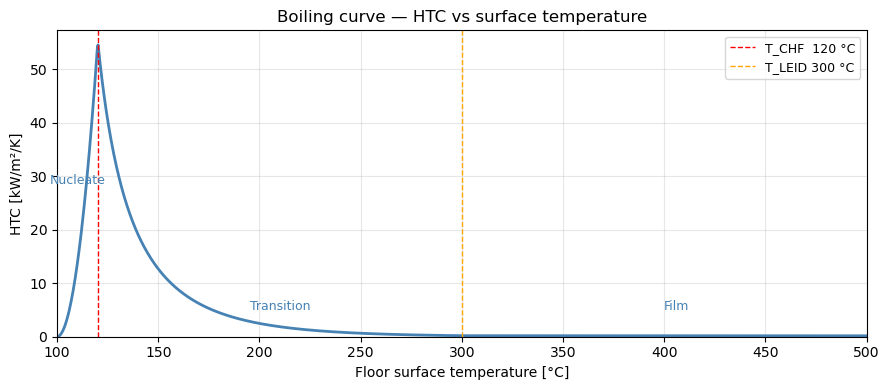

T_CHF  = 120.1 °C   h_CHF  = 55.1 kW/m²/K
T_LEID = 300.0 °C   h_LEID = 0.2 kW/m²/K  (film side)
HTC ratio (CHF/LEID): 289×


In [53]:
# ── Boiling curve: HTC vs floor surface temperature ──────────────────────────
_T_surf = np.linspace(T_sat + 1, 773, 1200)
_htc    = np.array([boiling_htc(Ti) for Ti in _T_surf])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(_T_surf - 273.15, _htc / 1e3, color='steelblue', lw=2)

ax.axvline(T_CHF  - 273.15, color='red',    lw=1, ls='--', label=f'T_CHF  {T_CHF -273.15:.0f} °C')
ax.axvline(T_LEID - 273.15, color='orange', lw=1, ls='--', label=f'T_LEID {T_LEID-273.15:.0f} °C')

# Annotate regimes
ax.text((T_sat + T_CHF) /2 - 273.15,  ax.get_ylim()[1]*0.5 if ax.get_ylim()[1]>0 else 20,
        'Nucleate', ha='center', fontsize=9, color='steelblue')
ax.text((T_CHF + T_LEID)/2 - 273.15,  5, 'Transition', ha='center', fontsize=9, color='steelblue')
ax.text(T_LEID - 273.15 + 100,        5, 'Film',        ha='left',  fontsize=9, color='steelblue')

ax.set_xlabel('Floor surface temperature [°C]')
ax.set_ylabel('HTC [kW/m²/K]')
ax.set_title('Boiling curve — HTC vs surface temperature')
ax.set_xlim(T_sat - 273.15, 500)
ax.set_ylim(bottom=0)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"T_CHF  = {T_CHF -273.15:.1f} °C   h_CHF  = {boiling_htc(T_CHF) /1e3:.1f} kW/m²/K")
print(f"T_LEID = {T_LEID-273.15:.1f} °C   h_LEID = {boiling_htc(T_LEID)/1e3:.1f} kW/m²/K  (film side)")
print(f"HTC ratio (CHF/LEID): {boiling_htc(T_CHF)/boiling_htc(T_LEID):.0f}×")


  Wall->gas steam LUT (path=2.12 m)... done  alpha=1.000 at 120°C (0.000 transmitted)
  floor_transient: LUT built (380 pts), dx=3.0 mm, ρ=170.0 kg/m³, cp=2000.0 J/kg/K
  [120C] radial floor: activated at t=0.1s  T_s=120C  h=54495 W/m2/K  R_o=2.39m  dr=0.024m  ramp_t=5s
  [120C block] floor: film -> nucleate boiling at t=0.1 s  (T_surf=120C  T_wall=120C  xH2O_h=0.0%  n_h=1431 mol  T_h=120C  Pg_h=0.00 Pg_c=0.00 inH2O)
  [120C] radial floor: reverted to lumped at t=5.5s  T_avg=102C
  [BACKFLOW t=12.1s] P_h=106169 P_c=106178 n_h=1499.9 T_h=393K T_mix=313K
  [ctrl 120C] t=70.3s  Pg_c=-0.001 inH2O  e=+0.499  de/dt=+0.000  Q_chill=400 kW (100%)  purge=ON
  [ctrl 120C] t=75.3s  Pg_c=0.361 inH2O  e=+0.826  de/dt=+0.036  Q_chill=400 kW (100%)  purge=ON
  [ctrl 120C] t=80.3s  Pg_c=0.441 inH2O  e=+0.942  de/dt=-0.001  Q_chill=400 kW (100%)  purge=ON
  [ctrl 120C] t=85.4s  Pg_c=0.464 inH2O  e=+0.972  de/dt=-0.008  Q_chill=400 kW (100%)  purge=ON
  [ctrl 120C] t=90.4s  Pg_c=0.472 inH2O  e=+0.982  d

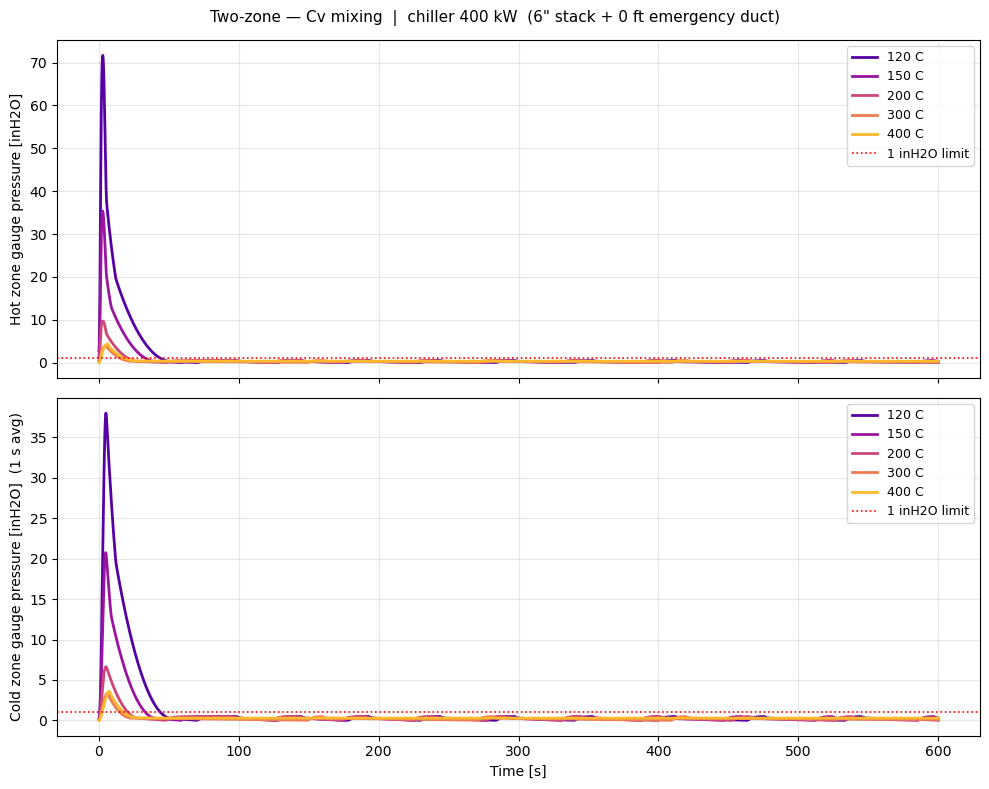

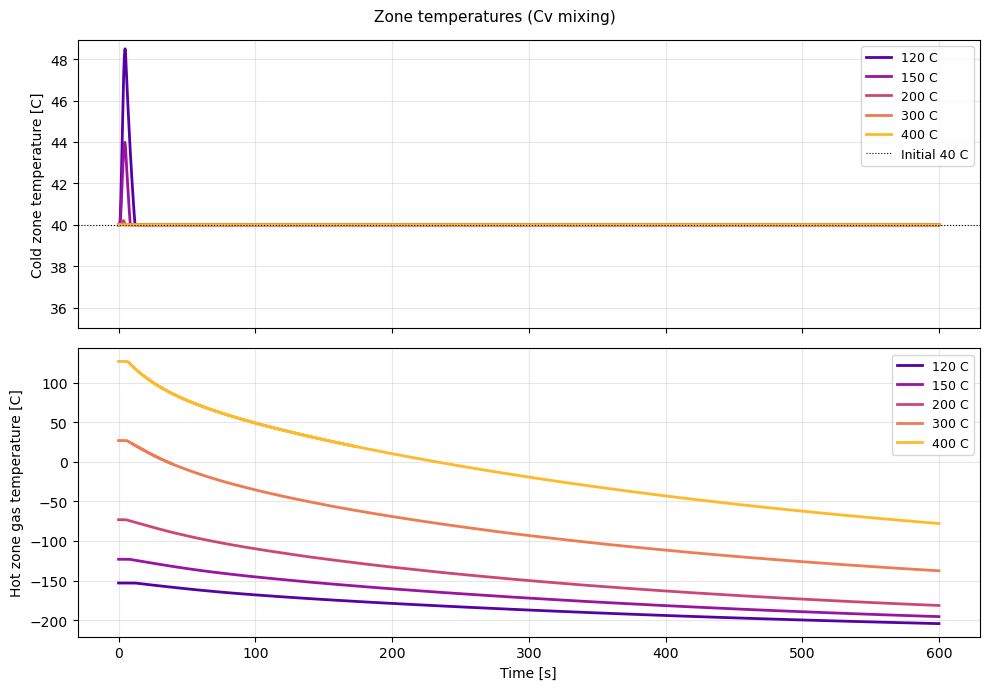

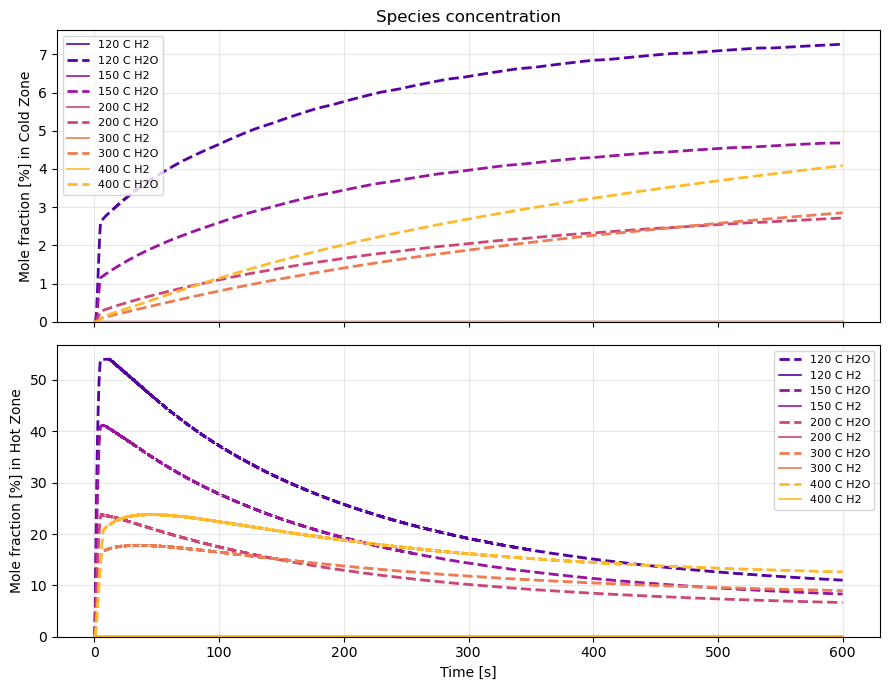

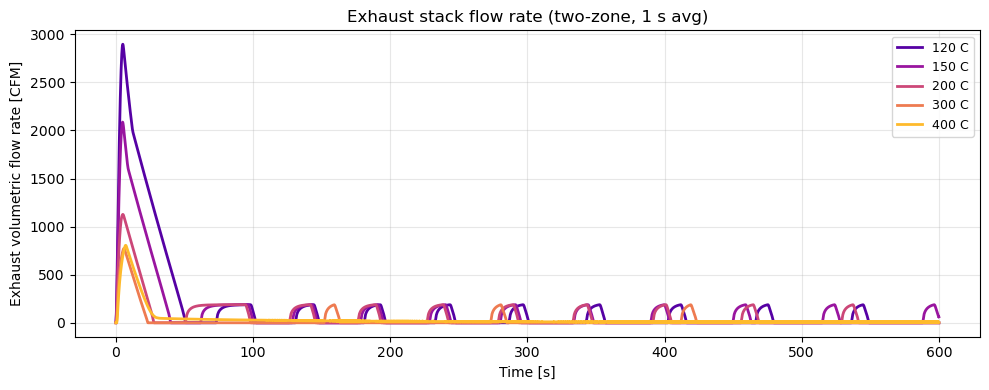

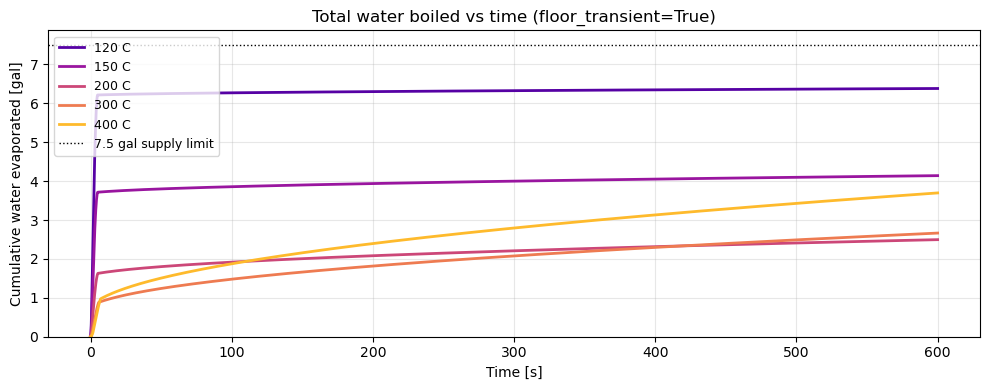

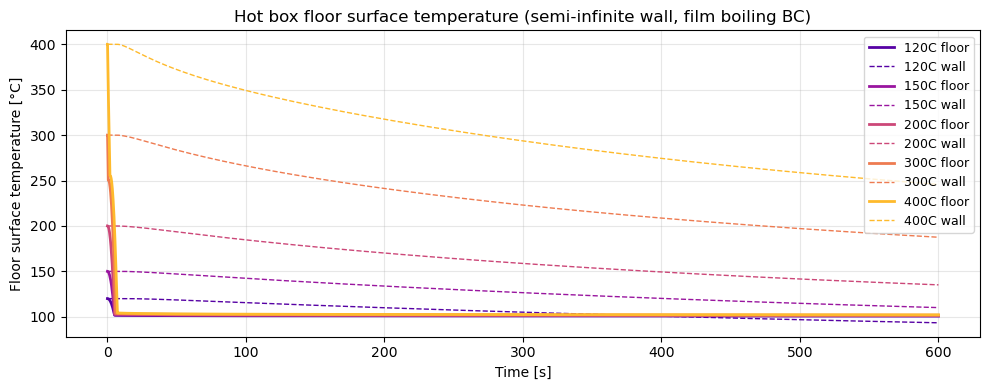


Hot zone wall loads  (two-zone, liner_break, 6" stack + 0 ft emergency duct)
    T [C]    dP_peak [Pa]   dP [inH2O]   F_sides [kN]   F_floor [kN]   F_ceil [kN]   Tc_peak [C]   Qex_peak [CFM]   H2_c_peak [%]
      120         13791.8      55.3688         600.44         248.25        246.97         48.50           2913.5            0.00
      150          6564.7      26.3548         285.80         118.16        117.55         43.98           2097.8            0.00
      200          1614.5       6.4816          70.29          29.06         28.91         40.20           1131.9            0.00
      300           378.9       1.5213          16.50           6.82          6.79         40.00            779.4            0.00
      400           393.4       1.5792          17.13           7.08          7.04         40.00            811.7            0.00
  Loads = peak dP x surface area


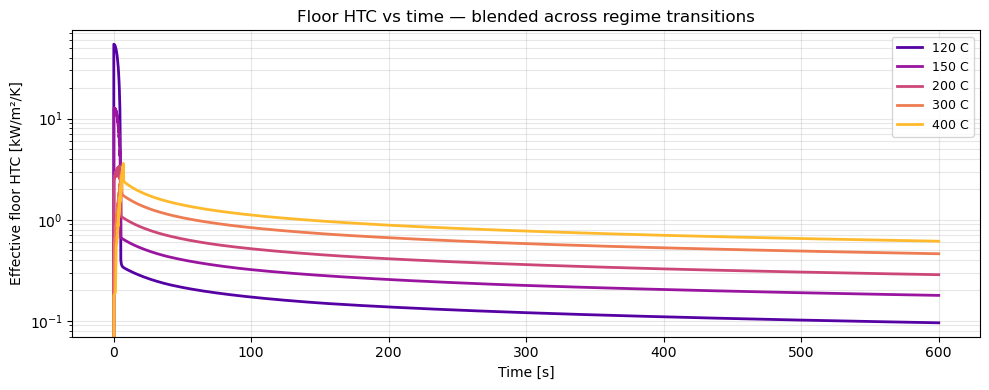

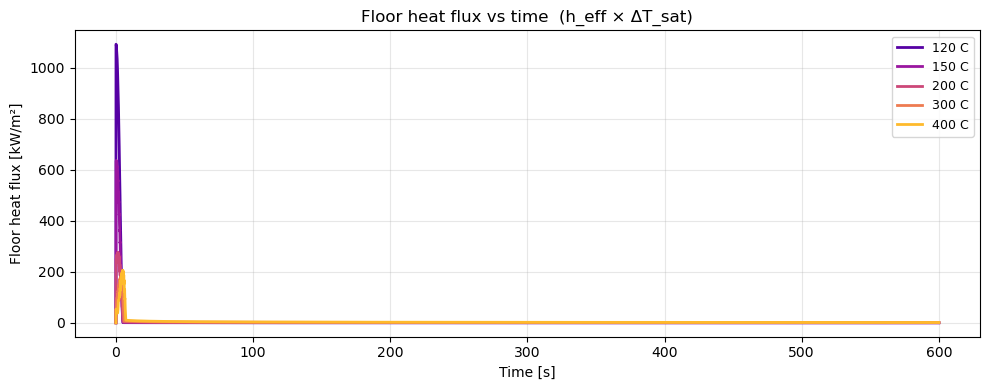

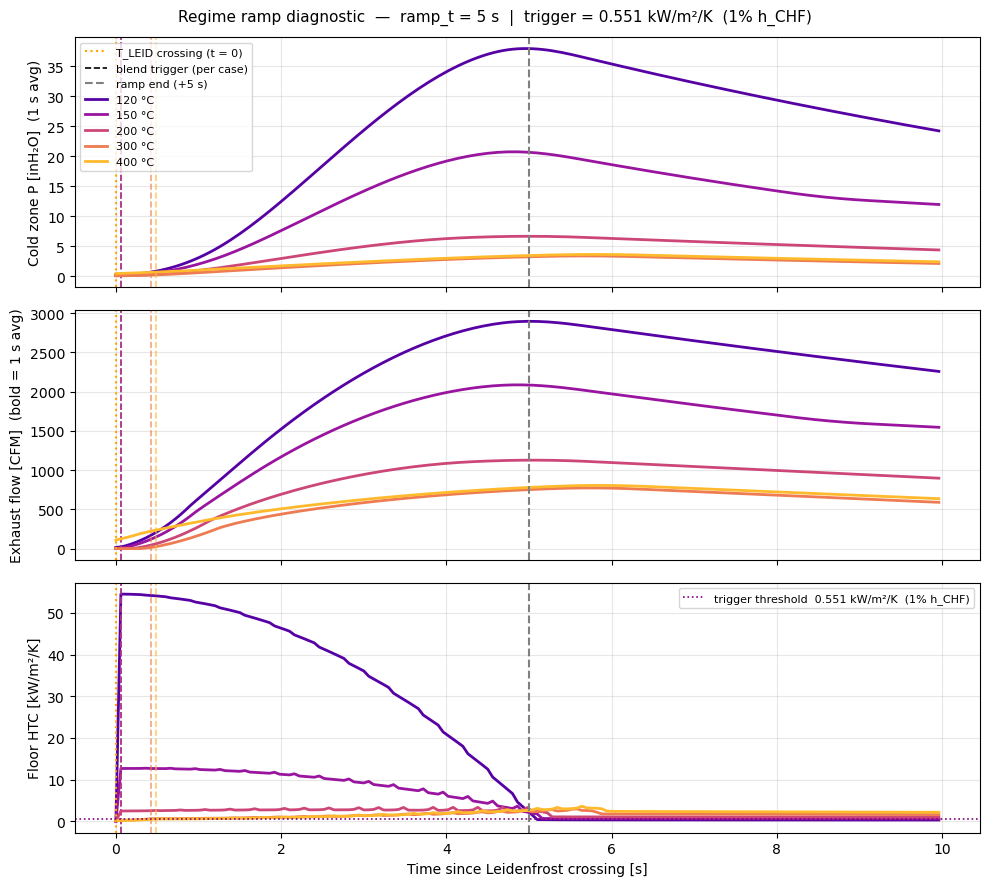

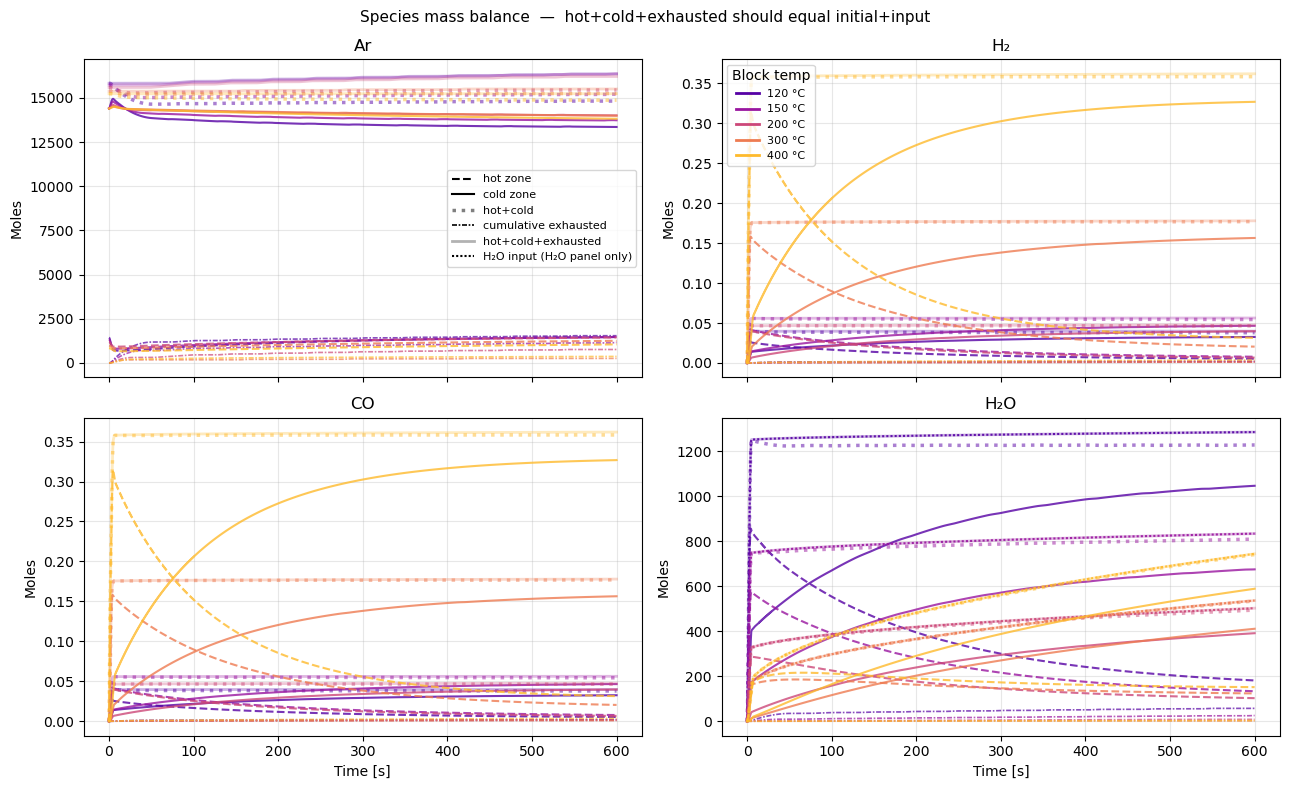

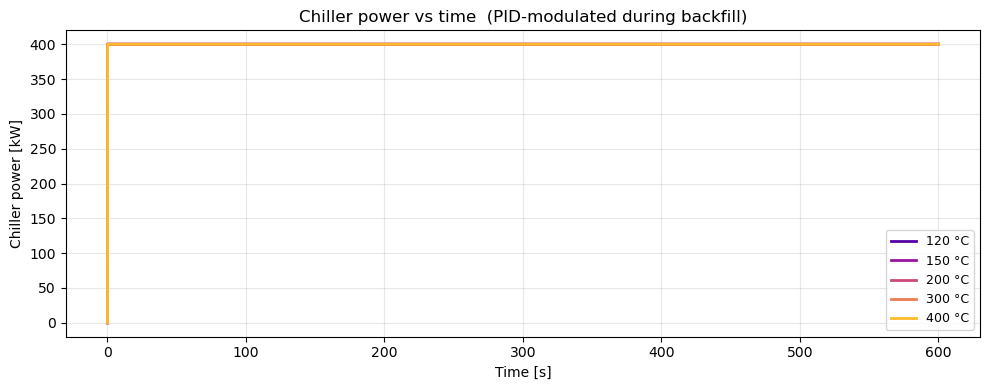

In [54]:
from scipy.ndimage import uniform_filter1d
T_blocks_2z = [120, 150, 200, 300, 400]
colors_2z   = plt.cm.plasma(np.linspace(0.15, 0.85, len(T_blocks_2z)))
V_spill_gal = 7.5
m_water_kg = V_spill_gal * gal_m3 * rho_l
water_gas_reaction = True   # CO + H2 from water-gas reaction (otherwise just H2O)
_sims_2z = {}
d_stack_default = 6 * in_m
d_emerg = 0.01
for T_C, col in zip(T_blocks_2z, colors_2z):
    t, Pg_h, Pg_c, dP, lds, conc, Tc, flows = simulate_two_zone(
        T_C + 273.15, d_stack_default, t_end=600, n=10000,
        regime_ramp_t = 5, chiller_on=True, Q_chiller_W=400e3, Pg_bf_setpoint=-0.5, chiller_Kp=0.5, chiller_Ki=0.005, chiller_Kd=2.0, chiller_tau_d=1.0, chiller_ramp_rate=0.2, chiller_tt=5.0,
        floor_transient=True, Q_backfill_cfm=200.0,
        exhaust_crack_inH2O=0.3, exhaust_close_inH2O=0.28, exhaust_louver_dP_inH2O=0.15)
    _sims_2z[T_C] = dict(t=t, Pg_h=Pg_h, Pg_c=Pg_c, dP=dP,
                         lds=lds, conc=conc, Tc=Tc, flows=flows, col=col)

# ── Hot zone and cold zone pressures ─────────────────────────────────────────
fig, (ax_h, ax_c) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.suptitle('Two-zone — Cv mixing  |  chiller 400 kW  '
             f'({d_stack_default/in_m:.0f}" stack + {d_emerg/ft_m:.0f} ft emergency duct)',
             fontsize=11)

for T_C, d in _sims_2z.items():
    lbl = f'{T_C} C'
    _dt_p  = d['t'][1] - d['t'][0] if len(d['t']) > 1 else 0.02
    _win_p = max(1, int(1.0 / _dt_p))
    ax_h.plot(d['t'], uniform_filter1d(d['Pg_h'], size=_win_p), color=d['col'], lw=2, label=lbl)
    ax_c.plot(d['t'], uniform_filter1d(d['Pg_c'], size=_win_p), color=d['col'], lw=2, label=lbl)

ax_h.axhline(1.0, color='red', lw=1.2, ls=':', label='1 inH2O limit')
ax_h.set_ylabel('Hot zone gauge pressure [inH2O]')
ax_h.legend(fontsize=9);  ax_h.grid(True, alpha=0.3)#;  ax_h.set_ylim(bottom=0)
#ax_h.legend(fontsize=9);  ax_h.grid(True, alpha=0.3);  ax_h.set_ylim(bottom=0);  ax_h.set_xlim(0, 30)

ax_c.axhline(1.0, color='red', lw=1.2, ls=':', label='1 inH2O limit')
ax_c.set_ylabel('Cold zone gauge pressure [inH2O]  (1 s avg)')
ax_c.set_xlabel('Time [s]')
ax_c.legend(fontsize=9);  ax_c.grid(True, alpha=0.3)#;  ax_c.set_ylim(bottom=0)
#ax_c.legend(fontsize=9);  ax_c.grid(True, alpha=0.3);  ax_c.set_ylim(bottom=0);  ax_c.set_xlim(0, 30)
plt.tight_layout();  plt.show()

# ── Zone temperatures ─────────────────────────────────────────────────────────────
fig, (ax_tc, ax_th) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
fig.suptitle('Zone temperatures (Cv mixing)', fontsize=11)
for T_C, d in _sims_2z.items():
    ax_tc.plot(d['t'], d['Tc'], color=d['col'], lw=2, label=f'{T_C} C')
    ax_th.plot(d['t'], d['flows']['T_h'] - 273.15, color=d['col'], lw=2, label=f'{T_C} C')
ax_tc.axhline(T_cold_2z - 273.15, color='k', lw=0.8, ls=':',
             label=f'Initial {T_cold_2z-273.15:.0f} C')
ax_tc.set_ylabel('Cold zone temperature [C]')
ax_tc.legend(fontsize=9);  ax_tc.grid(True, alpha=0.3)
ax_tc.set_ylim(bottom=T_cold_2z - 273.15 - 5)
ax_th.set_ylabel('Hot zone gas temperature [C]')
ax_th.set_xlabel('Time [s]')
ax_th.legend(fontsize=9);  ax_th.grid(True, alpha=0.3)
plt.tight_layout();  plt.show()

# ── Gas concentration ─────────────────────────────────────────────────────────
fig, (ax, ax_wh) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for T_C, d in _sims_2z.items():
    ax.plot(d['t'], d['conc']['H2']*100,   color=d['col'], lw=1.2,   label=f'{T_C} C H2')
    ax.plot(d['t'], d['conc']['H2O']*100, color=d['col'], lw=2, ls='--', label=f'{T_C} C H2O')
ax.set_ylabel('Mole fraction [%] in Cold Zone')
ax.set_title('Species concentration')
ax.legend(fontsize=8);  ax.grid(True, alpha=0.3);  ax.set_ylim(bottom=0)
for T_C, d in _sims_2z.items():
    ax_wh.plot(d['t'], d['conc']['H2O_h']*100, color=d['col'], lw=2, ls='--', label=f'{T_C} C H2O')
    ax_wh.plot(d['t'], d['conc']['H2_h']*100, color=d['col'], lw=1.2, label=f'{T_C} C H2')
ax_wh.set_xlabel('Time [s]')
ax_wh.set_ylabel('Mole fraction [%] in Hot Zone')
ax_wh.legend(fontsize=8);  ax_wh.grid(True, alpha=0.3);  ax_wh.set_ylim(bottom=0)
plt.tight_layout();  plt.show()

# ── Exhaust volumetric flow rate ─────────────────────────────────────────────
fig, ax_q = plt.subplots(figsize=(10, 4))
for T_C, d in _sims_2z.items():
    _dt_s = d["t"][1] - d["t"][0] if len(d["t"]) > 1 else 0.02
    _win  = max(1, int(1.0 / _dt_s))
    _qex  = uniform_filter1d(d["flows"]["Qex"] * 60 / ft3_m3, size=_win)
    ax_q.plot(d["t"], _qex, color=d["col"], lw=2, label=f"{T_C} C")
ax_q.set_xlabel("Time [s]")
ax_q.set_ylabel("Exhaust volumetric flow rate [CFM]")
ax_q.set_title("Exhaust stack flow rate (two-zone, 1 s avg)")
ax_q.legend(fontsize=9);  ax_q.grid(True, alpha=0.3)#;  ax_q.set_xlim(0, 30)
#ax_q.set_xscale("log");  ax_q.set_yscale("log");  ax_q.set_ylim(bottom=1);  ax_q.legend(fontsize=9);  ax_q.grid(True, alpha=0.3, which="both")
plt.tight_layout();  plt.show()

# ── Cumulative water boiled ─────────────────────────────────────────────
fig, ax_mw = plt.subplots(figsize=(10, 4))
for T_C, d in _sims_2z.items():
    m_gal = d["flows"]["m_used"] / (rho_l * gal_m3)
    ax_mw.plot(d["t"], m_gal, color=d["col"], lw=2, label=f"{T_C} C")
ax_mw.axhline(V_spill_gal, color="k", lw=1, ls=":",
              label=f"{V_spill_gal:.1f} gal supply limit")
ax_mw.set_xlabel("Time [s]")
ax_mw.set_ylabel("Cumulative water evaporated [gal]")
ax_mw.set_title("Total water boiled vs time (floor_transient=True)")
ax_mw.legend(fontsize=9);  ax_mw.grid(True, alpha=0.3);  ax_mw.set_ylim(bottom=0)
plt.tight_layout();  plt.show()

# ── Floor surface temperature ────────────────────────────────────────
fig, ax_ts = plt.subplots(figsize=(10, 4))
for T_C, d in _sims_2z.items():
    ax_ts.plot(d["t"], d["flows"]["T_surf"],      color=d["col"], lw=2, label=f"{T_C}C floor")
    ax_ts.plot(d["t"], d["flows"]["T_wall_surf"], color=d["col"], lw=1, ls="--", label=f"{T_C}C wall")
ax_ts.set_xlabel("Time [s]")
ax_ts.set_ylabel("Floor surface temperature [°C]")
ax_ts.set_title("Hot box floor surface temperature (semi-infinite wall, film boiling BC)")
ax_ts.legend(fontsize=9);  ax_ts.grid(True, alpha=0.3)
plt.tight_layout();  plt.show()

# ── Wall load table ───────────────────────────────────────────────────────────
print(f"\nHot zone wall loads  (two-zone, liner_break, "
      f"{d_stack_default/in_m:.0f}\" stack + {d_emerg/ft_m:.0f} ft emergency duct)")
print(f"  {'T [C]':>7}  {'dP_peak [Pa]':>14}  {'dP [inH2O]':>11}  "
      f"{'F_sides [kN]':>13}  {'F_floor [kN]':>13}  {'F_ceil [kN]':>12}  {'Tc_peak [C]':>12}  {'Qex_peak [CFM]':>15}  {'H2_c_peak [%]':>14}")
for T_C, d in _sims_2z.items():
    ld = d['lds']
    print(f"  {T_C:>7}  {ld['dP_peak_Pa']:>14.1f}  "
          f"{ld['dP_peak_Pa']*Pa_inH2O:>11.4f}  "
          f"{ld['F_sidewalls_kN']:>13.2f}  "
          f"{ld['F_floor_kN']:>13.2f}  "
          f"{ld['F_ceiling_kN']:>12.2f}  "
          f"{max(d['Tc']):>12.2f}  "
          f"{max(d['flows']['Qex']) / ft3_m3 * 60:>15.1f}  "
          f"{max(d['conc']['H2'])*100:>14.2f}")
print("  Loads = peak dP x surface area")

# ── Effective floor HTC vs time ──────────────────────────────────────────────
fig, ax_h = plt.subplots(figsize=(10, 4))
for T_C, d in _sims_2z.items():
    _heff = d['flows']['h_eff']
    ax_h.plot(d['t'], _heff / 1e3, color=d['col'], lw=2, label=f'{T_C} C')
ax_h.set_xlabel('Time [s]')
ax_h.set_ylabel('Effective floor HTC [kW/m²/K]')
ax_h.set_title('Floor HTC vs time — blended across regime transitions')
ax_h.set_yscale('log')
ax_h.legend(fontsize=9);  ax_h.grid(True, alpha=0.3, which='both')
plt.tight_layout();  plt.show()

# ── Floor heat flux vs time ─────────────────────────────────────────────────────────────────────────────────────────────────
_T_sat_C = T_sat - 273.15
fig, ax_qf = plt.subplots(figsize=(10, 4))
for T_C, d in _sims_2z.items():
    _h    = d['flows']['h_eff']
    _dT   = d['flows']['T_surf'] - _T_sat_C
    _qkW  = _h * np.maximum(_dT, 0.0) / 1e3
    ax_qf.plot(d['t'], _qkW, color=d['col'], lw=2, label=f'{T_C} C')
ax_qf.set_xlabel('Time [s]')
ax_qf.set_ylabel('Floor heat flux [kW/m²]')
ax_qf.set_title('Floor heat flux vs time  (h_eff × ΔT_sat)')
ax_qf.legend(fontsize=9);  ax_qf.grid(True, alpha=0.3)
plt.tight_layout();  plt.show()

# ── Diagnostic: zoomed to Leidenfrost crossing window ────────────────────────
_T_LEID_C  = T_LEID - 273.15
_first_d   = next(iter(_sims_2z.values()))
_ramp_t    = _first_d['flows'].get('ramp_t', 5)
_h_trig_kW = _first_d['flows'].get('h_trigger', 0.01 * boiling_htc(T_CHF)) / 1e3
_pct_label = f"{_h_trig_kW / (boiling_htc(T_CHF) / 1e3) * 100:.0f}% h_CHF"

fig2, axes2 = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax_p2, ax_q2, ax_h2 = axes2

for T_C, d in _sims_2z.items():
    _ts          = d['t']
    _surf        = d['flows']['T_surf']
    _hkW         = d['flows']['h_eff'] / 1e3
    _dt_s        = d['t'][1] - d['t'][0] if len(d['t']) > 1 else 0.02
    _win         = max(1, int(1.0 / _dt_s))
    _qcfm_raw    = d['flows']['Qex'] / ft3_m3 * 60
    _qcfm_flt    = uniform_filter1d(_qcfm_raw, size=_win)
    _dt_z        = d['t'][1] - d['t'][0] if len(d['t']) > 1 else 0.02
    _win_z       = max(1, int(1.0 / _dt_z))
    _pgc         = uniform_filter1d(d['Pg_c'], size=_win_z)
    _t_trig_abs  = d['flows']['t_trigger']

    _below = np.where(_surf < _T_LEID_C)[0]
    if not len(_below):
        continue
    _t0       = _ts[_below[0]]
    _t_trig_r = _t_trig_abs - _t0 if not np.isnan(_t_trig_abs) else None

    _mask  = (_ts >= _t0) & (_ts <= _t0 + 10)
    _t_rel = _ts[_mask] - _t0

    ax_p2.plot(_t_rel, _pgc[_mask],  color=d['col'], lw=2, label=f'{T_C} °C')
    #ax_q2.plot(_t_rel, _qcfm_raw[_mask], color=d['col'], lw=1, alpha=0.35)
    ax_q2.plot(_t_rel, _qcfm_flt[_mask], color=d['col'], lw=2)
    ax_h2.plot(_t_rel, _hkW[_mask],  color=d['col'], lw=2)

    if _t_trig_r is not None:
        for _ax in (ax_p2, ax_q2, ax_h2):
            _ax.axvline(_t_trig_r, color=d['col'], lw=1.2, ls='--', alpha=0.7)

for _ax in (ax_p2, ax_q2, ax_h2):
    _ax.axvline(0,        color='orange', lw=1.5, ls=':')
    _ax.axvline(_ramp_t,  color='gray',   lw=1.5, ls='--')
    _ax.grid(True, alpha=0.3)

ax_h2.axhline(_h_trig_kW, color='purple', lw=1.2, ls=':',
              label=f'trigger threshold  {_h_trig_kW:.3f} kW/m²/K  ({_pct_label})')
ax_p2.set_ylabel('Cold zone P [inH₂O]  (1 s avg)')
ax_q2.set_ylabel('Exhaust flow [CFM]  (bold = 1 s avg)')
ax_h2.set_ylabel('Floor HTC [kW/m²/K]')
ax_h2.set_xlabel('Time since Leidenfrost crossing [s]')

from matplotlib.lines import Line2D
_leg_handles = [
    Line2D([0],[0], color='orange', ls=':',  lw=1.5, label='T_LEID crossing (t = 0)'),
    Line2D([0],[0], color='k',      ls='--', lw=1.2, label='blend trigger (per case)'),
    Line2D([0],[0], color='gray',   ls='--', lw=1.5, label=f'ramp end (+{_ramp_t} s)'),
]
ax_p2.legend(handles=_leg_handles + list(ax_p2.get_legend_handles_labels()[0]), fontsize=8)
ax_h2.legend(fontsize=8)
fig2.suptitle(
    f'Regime ramp diagnostic  —  ramp_t = {_ramp_t} s  |  trigger = {_h_trig_kW:.3f} kW/m²/K  ({_pct_label})',
    fontsize=11)
plt.tight_layout();  plt.show()

# ── Mass balance: total moles per species in hot & cold zones ─────────────────
_mb_specs = [
    ('Ar',  'n_Ar_h',  'n_Ar_c',  'cum_ex_Ar',  None),
    ('H₂',  'n_H2_h',  'n_H2_c',  'cum_ex_H2',  None),
    ('CO',  'n_CO_h',  'n_CO_c',  'cum_ex_CO',  None),
    ('H₂O', 'n_H2O_h', 'n_H2O_c', 'cum_ex_H2O', 'cum_H2O_in'),
]
fig_mb, axes_mb = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
axes_mb = axes_mb.flatten()
for ax_i, (sp_name, k_h, k_c, k_ex, k_in) in enumerate(_mb_specs):
    ax_mb = axes_mb[ax_i]
    for T_C, d in _sims_2z.items():
        _lc  = d['col']
        _nh  = d['conc'][k_h]
        _nc  = d['conc'][k_c]
        _nex = d['conc'][k_ex]
        ax_mb.plot(d['t'], _nh,              color=_lc, lw=1.5, ls='--',         alpha=0.8)
        ax_mb.plot(d['t'], _nc,              color=_lc, lw=1.5, ls='-',          alpha=0.8)
        ax_mb.plot(d['t'], _nh + _nc,        color=_lc, lw=2.5, ls=':',          alpha=0.5)
        ax_mb.plot(d['t'], _nex,             color=_lc, lw=1.2, ls=(0,(3,1,1,1)),alpha=0.7)
        ax_mb.plot(d['t'], _nh + _nc + _nex, color=_lc, lw=2.0, ls='-',          alpha=0.3)
        if k_in:
            ax_mb.plot(d['t'], d['conc'][k_in], color=_lc, lw=1.5, ls=(0,(1,1)), alpha=0.9)
    ax_mb.set_title(sp_name)
    ax_mb.set_ylabel('Moles')
    ax_mb.grid(True, alpha=0.3)
    if ax_i >= 2:
        ax_mb.set_xlabel('Time [s]')

from matplotlib.lines import Line2D
_mb_leg = [
    Line2D([0],[0], color='k', ls='--',           lw=1.5,       label='hot zone'),
    Line2D([0],[0], color='k', ls='-',            lw=1.5,       label='cold zone'),
    Line2D([0],[0], color='k', ls=':',            lw=2.5, alpha=0.5, label='hot+cold'),
    Line2D([0],[0], color='k', ls=(0,(3,1,1,1)), lw=1.2,       label='cumulative exhausted'),
    Line2D([0],[0], color='k', ls='-',            lw=2.0, alpha=0.3, label='hot+cold+exhausted'),
    Line2D([0],[0], color='k', ls=(0,(1,1)),      lw=1.5,       label='H₂O input (H₂O panel only)'),
]
axes_mb[0].legend(handles=_mb_leg, fontsize=8)
axes_mb[1].legend(
    handles=[Line2D([0],[0], color=d['col'], ls='-', lw=2, label=f'{T_C} °C')
             for T_C, d in _sims_2z.items()],
    fontsize=8, title='Block temp')
fig_mb.suptitle(
    'Species mass balance  —  hot+cold+exhausted should equal initial+input',
    fontsize=11)
plt.tight_layout();  plt.show()

# ── Chiller power vs time ─────────────────────────────────────────────────────────────────────────────
fig, ax_qc = plt.subplots(figsize=(10, 4))
for T_C, d in _sims_2z.items():
    _qc = d['flows'].get('Q_chill', np.zeros_like(d['t'])) / 1e3
    ax_qc.plot(d['t'], _qc, color=d['col'], lw=2, label=f'{T_C} °C')
ax_qc.set_xlabel('Time [s]')
ax_qc.set_ylabel('Chiller power [kW]')
ax_qc.set_title('Chiller power vs time  (PID-modulated during backfill)')
ax_qc.legend(fontsize=9);  ax_qc.grid(True, alpha=0.3)
plt.tight_layout();  plt.show()


  Wall->gas steam LUT (path=2.12 m)... done  alpha=0.927 at 1800°C (0.073 transmitted)
  floor_transient: LUT built (380 pts), dx=3.0 mm, ρ=170.0 kg/m³, cp=2000.0 J/kg/K
  [1800C block] floor: film -> transition boiling at t=42.7 s  (T_surf=300C  T_wall=1443C  xH2O_h=77.8%  n_h=330 mol  T_h=1434C  Pg_h=0.65 Pg_c=0.32 inH2O)
  [1800C] radial floor: activated at t=44.7s  T_s=255C  h=567 W/m2/K  R_o=2.39m  dr=0.024m  ramp_t=5s
  [1800C block] floor: transition -> nucleate boiling at t=49.8 s  (T_surf=120C  T_wall=1399C  xH2O_h=88.1%  n_h=342 mol  T_h=1380C  Pg_h=1.82 Pg_c=0.31 inH2O)
  [ctrl 1800C] t=99.1s  Pg_c=-0.012 inH2O  e=+0.488  de/dt=+0.000  Q_chill=400 kW (100%)  purge=ON
  [1800C block] floor: nucleate -> transition boiling at t=99.1 s  (T_surf=121C  T_wall=1479C  xH2O_h=98.2%  n_h=321 mol  T_h=1478C  Pg_h=-0.01 Pg_c=-0.11 inH2O)
  [BACKFLOW t=99.2s] P_h=101272 P_c=101276 n_h=321.2 T_h=1751K T_mix=402K
  [1800C] radial floor: reverted to lumped at t=102.1s  T_avg=255C
  [1800C b

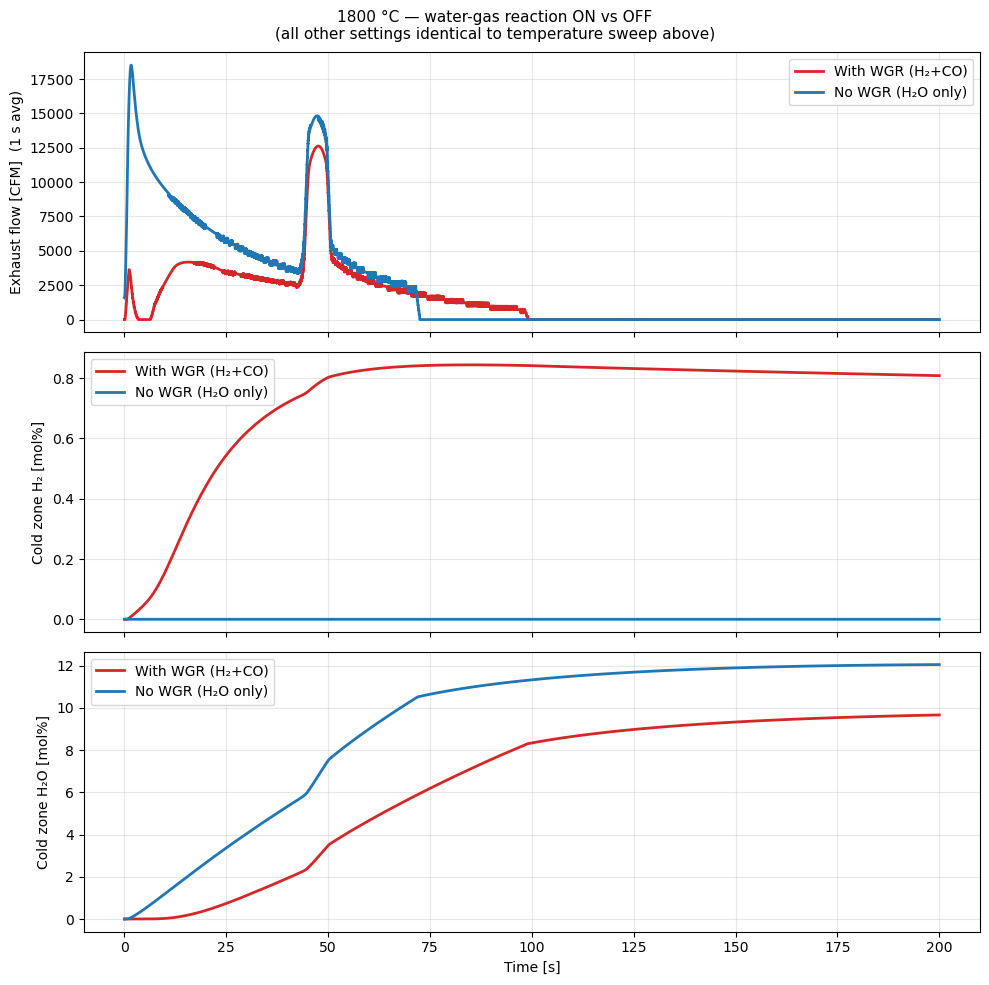

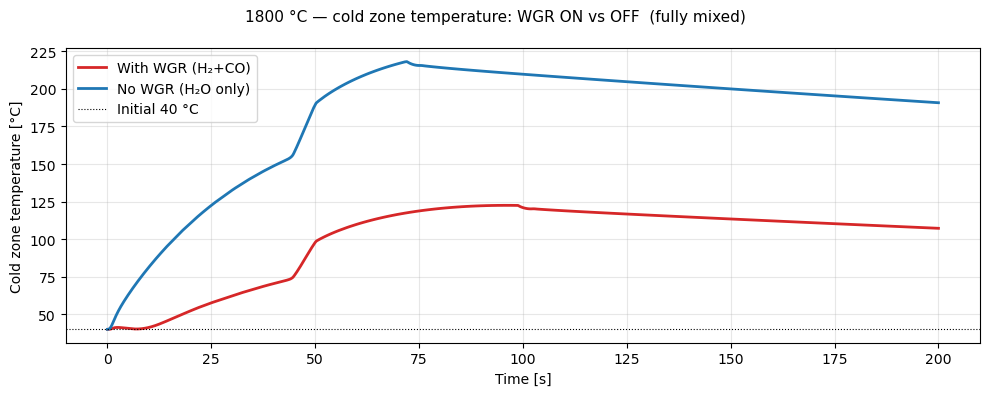

In [1164]:
# ── 1800 C: water-gas reaction ON vs OFF ─────────────────────────────────────
# Same settings as the temperature sweep cell; only water_gas_reaction changes.
_T_wgr_C = 1800
_cases_wgr = {}

for _label, _wgr in [('With WGR (H₂+CO)', True), ('No WGR (H₂O only)', False)]:
    water_gas_reaction = _wgr
    _t, _Pg_h, _Pg_c, _dP, _lds, _conc, _Tc, _flows = simulate_two_zone(
        _T_wgr_C + 273.15, d_stack_default, t_end=200, n=10000,
        regime_ramp_t=5, chiller_on=True, Q_chiller_W=400e3,
        Pg_bf_setpoint=-0.5, chiller_Kp=0.5, chiller_Ki=0.005,
        chiller_Kd=2.0, chiller_tau_d=1.0, chiller_ramp_rate=0.2, chiller_tt=5.0,
        floor_transient=True, Q_backfill_cfm=200.0,
        f_mix=0.75,
        exhaust_crack_inH2O=0.3, exhaust_close_inH2O=0.28,
        exhaust_louver_dP_inH2O=0.15)
    _cases_wgr[_label] = dict(t=_t, Pg_h=_Pg_h, Pg_c=_Pg_c,
                               conc=_conc, Tc=_Tc, flows=_flows)

water_gas_reaction = True  # restore module-level default

_clr_wgr = {'With WGR (H₂+CO)': 'tab:red', 'No WGR (H₂O only)': 'tab:blue'}

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
fig.suptitle(f'{_T_wgr_C} °C — water-gas reaction ON vs OFF\n'
             '(all other settings identical to temperature sweep above)', fontsize=11)

# Exhaust flow rate
ax = axes[0]
for _lbl, _d in _cases_wgr.items():
    _dt_s = _d['t'][1] - _d['t'][0]
    _win  = max(1, int(1.0 / _dt_s))
    _qex  = uniform_filter1d(_d['flows']['Qex'] / ft3_m3 * 60, size=_win)
    ax.plot(_d['t'], _qex, color=_clr_wgr[_lbl], lw=2, label=_lbl)
ax.set_ylabel('Exhaust flow [CFM]  (1 s avg)')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

# Cold zone H2 mole fraction
ax = axes[1]
for _lbl, _d in _cases_wgr.items():
    ax.plot(_d['t'], _d['conc']['H2'] * 100, color=_clr_wgr[_lbl], lw=2, label=_lbl)
ax.set_ylabel('Cold zone H₂ [mol%]')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

# Cold zone H2O mole fraction
ax = axes[2]
for _lbl, _d in _cases_wgr.items():
    ax.plot(_d['t'], _d['conc']['H2O'] * 100, color=_clr_wgr[_lbl], lw=2, label=_lbl)
ax.set_ylabel('Cold zone H₂O [mol%]')
ax.set_xlabel('Time [s]')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
fig2, ax_tc = plt.subplots(figsize=(10, 4))
fig2.suptitle(f'{_T_wgr_C} °C — cold zone temperature: WGR ON vs OFF  (fully mixed)', fontsize=11)
for _lbl, _d in _cases_wgr.items():
    ax_tc.plot(_d['t'], _d['Tc'], color=_clr_wgr[_lbl], lw=2, label=_lbl)
ax_tc.axhline(T_cold_2z - 273.15, color='k', lw=0.8, ls=':', label=f'Initial {T_cold_2z-273.15:.0f} °C')
ax_tc.set_ylabel('Cold zone temperature [°C]')
ax_tc.set_xlabel('Time [s]')
ax_tc.legend(fontsize=10); ax_tc.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()



  Wall->gas steam LUT (path=2.12 m)... 

done  alpha=0.827 at 2400°C (0.173 transmitted)
  [BACKFLOW t=8.6s] P_h=101455 P_c=101455 n_h=210.8 T_h=2673K T_mix=1206K
  [2400C block] Pg_h: min=-0.023 inH2O at t=12.0s, max=142.942 inH2O at t=2.2s; Pg_c min=-0.036 inH2O at t=12.0s
  Wall->gas steam LUT (path=2.12 m)... done  alpha=0.827 at 2400°C (0.173 transmitted)
  floor_transient: LUT built (380 pts), dx=3.0 mm, ρ=170.0 kg/m³, cp=2000.0 J/kg/K
  [2400C block] Pg_h: min=-6.781 inH2O at t=52.6s, max=26.907 inH2O at t=1.3s; Pg_c min=-6.788 inH2O at t=52.6s
  Wall->gas steam LUT (path=2.12 m)... done  alpha=0.827 at 2400°C (0.173 transmitted)
  [BACKFLOW t=17.9s] P_h=101324 P_c=101325 n_h=568.8 T_h=989K T_mix=653K
  [2400C block] Pg_h: min=-4.063 inH2O at t=22.5s, max=32.271 inH2O at t=1.6s; Pg_c min=-4.067 inH2O at t=22.5s
  Wall->gas steam LUT (path=2.12 m)... done  alpha=0.827 at 2400°C (0.173 transmitted)
  floor_transient: LUT built (380 pts), dx=3.0 mm, ρ=170.0 kg/m³, cp=2000.0 J/kg/K
  [2400C block] Pg_h: min=0.000 inH2O at 

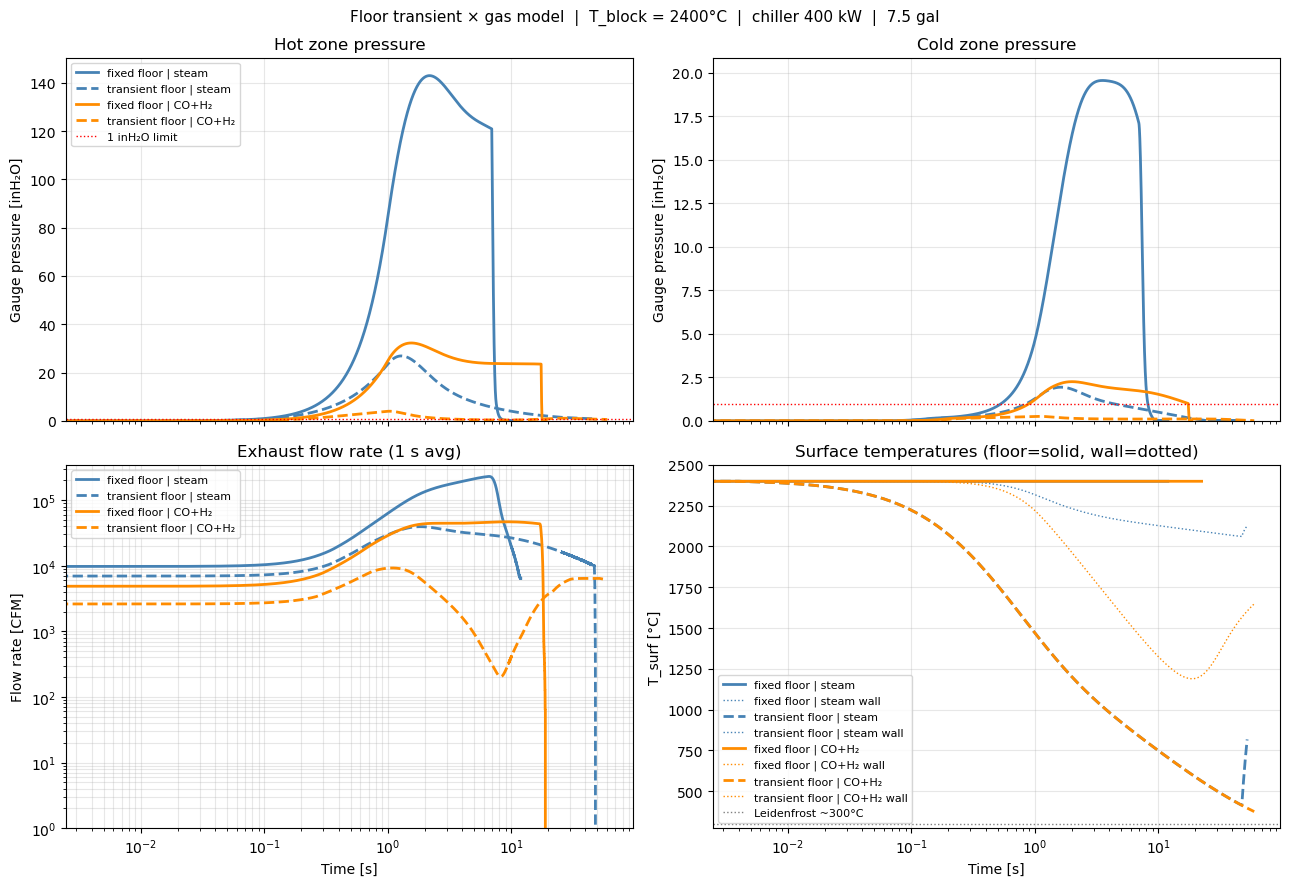

In [774]:
# ── Comparison: floor_transient × reaction model at T_block = 2400°C ─────────────
# Fixed vs transient floor  ×  pure steam vs CO+H₂ (water-gas reaction)
# All else equal: chiller 400 kW, default stack, 7.5 gal spill
_T_cmp  = 2400 + 273.15
_t_cmp  = 60
_n_cmp  = 15000

_cases_cmp = [
    dict(ft=False, wgr=False, label='fixed floor | steam',          color='steelblue',  ls='-'),
    dict(ft=True,  wgr=False, label='transient floor | steam',      color='steelblue',  ls='--'),
    dict(ft=False, wgr=True,  label='fixed floor | CO+H₂',       color='darkorange', ls='-'),
    dict(ft=True,  wgr=True,  label='transient floor | CO+H₂',   color='darkorange', ls='--'),
]

_wgr_save = water_gas_reaction
_sims_cmp = []
for _c in _cases_cmp:
    water_gas_reaction = _c['wgr']
    t, Pg_h, Pg_c, dP, lds, conc, Tc, flows = simulate_two_zone(
        _T_cmp, d_stack_default, t_end=_t_cmp, n=_n_cmp,
        chiller_on=True, Q_chiller_W=400e3,
        floor_transient=_c['ft'])
    _sims_cmp.append(dict(**_c, t=t, Pg_h=Pg_h, Pg_c=Pg_c, conc=conc, flows=flows))
water_gas_reaction = _wgr_save

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
fig.suptitle('Floor transient × gas model  |  T_block = 2400°C  |  chiller 400 kW  |  7.5 gal',
             fontsize=11)
(ax_ph, ax_pc), (ax_mw, ax_ts) = axes

from scipy.ndimage import uniform_filter1d
for _c in _sims_cmp:
    kw = dict(color=_c['color'], ls=_c['ls'], lw=2, label=_c['label'])
    _dt_s = _c['t'][1] - _c['t'][0] if len(_c['t']) > 1 else 0.02
    _win  = max(1, int(1.0 / _dt_s))
    ax_ph.plot(_c['t'], _c['Pg_h'], **kw)
    ax_pc.plot(_c['t'], _c['Pg_c'], **kw)
    ax_mw.plot(_c['t'], uniform_filter1d(_c['flows']['Qex'] * 60 / ft3_m3, size=_win), **kw)
    ax_ts.plot(_c['t'], _c['flows']['T_surf'],      **kw)
    ax_ts.plot(_c['t'], _c['flows']['T_wall_surf'], color=_c['color'], ls=':', lw=1, label=_c['label']+' wall')

for ax, title, ylabel in [
        (ax_ph, 'Hot zone pressure',  'Gauge pressure [inH₂O]'),
        (ax_pc, 'Cold zone pressure', 'Gauge pressure [inH₂O]')]:
    ax.axhline(1.0, color='red', lw=1, ls=':', label='1 inH₂O limit')
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0); ax.grid(True, alpha=0.3)

ax_ph.legend(fontsize=8)

ax_mw.set_title('Exhaust flow rate (1 s avg)'); ax_mw.set_ylabel('Flow rate [CFM]')
ax_mw.set_xlabel('Time [s]'); ax_mw.set_xscale('log'); ax_mw.set_yscale('log'); ax_mw.set_ylim(bottom=1); ax_mw.grid(True, alpha=0.3, which='both')
ax_mw.legend(fontsize=8)

ax_ts.set_title('Surface temperatures (floor=solid, wall=dotted)'); ax_ts.set_ylabel('T_surf [°C]')
ax_ts.set_xlabel('Time [s]'); ax_ts.grid(True, alpha=0.3)
ax_ts.axhline(300, color='gray', lw=1, ls=':', label='Leidenfrost ~300°C')
ax_ts.legend(fontsize=8)

plt.tight_layout(); plt.show()


  floor_transient: LUT built (200 pts), dx=3.0 mm, ρ=170.0 kg/m³, cp=2000.0 J/kg/K


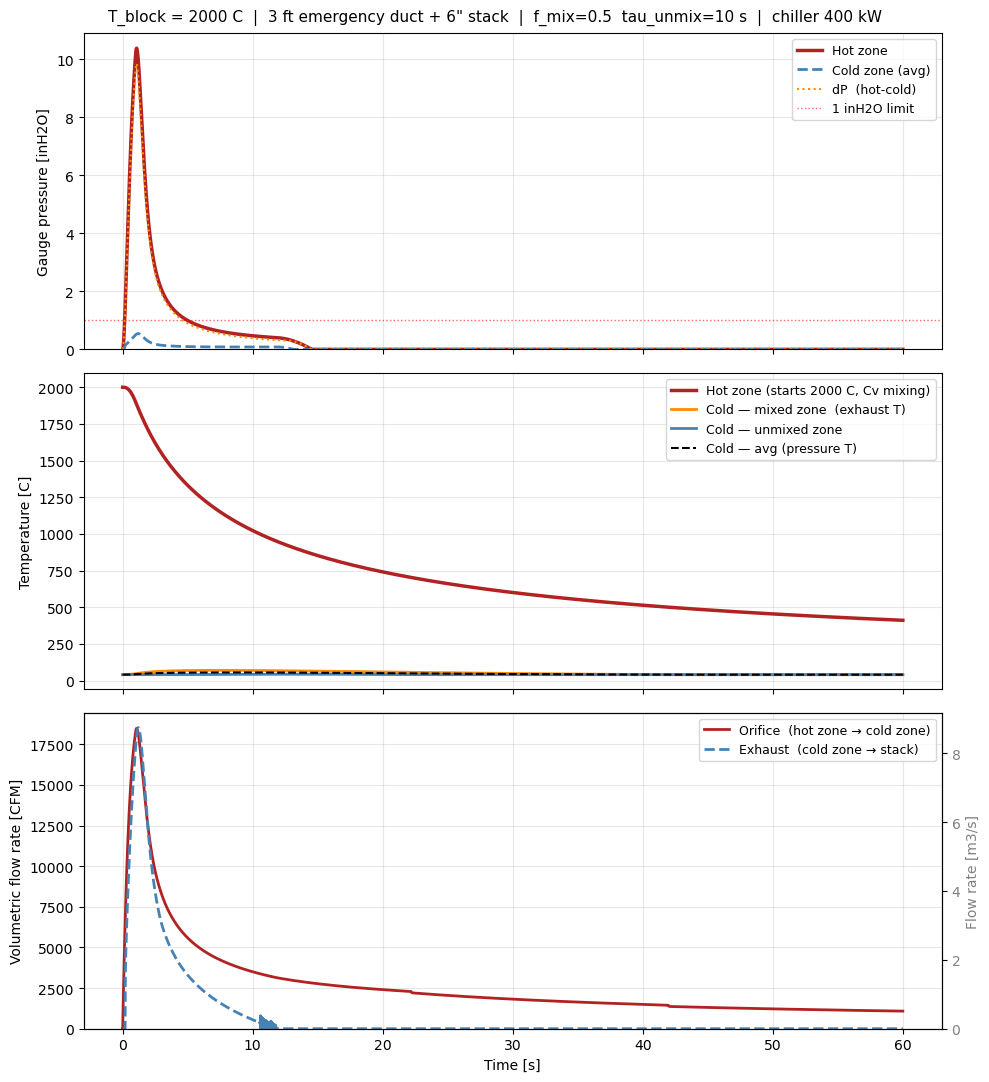

Generated gas temperature:    178.6 C  (at exit from film boiling zone)
Peak hot zone pressure:       10.3779 inH2O
Peak cold zone pressure:      0.5440 inH2O
Peak dP (hot-cold):           9.8509 inH2O  =  2453.8 Pa
Peak mixed zone temp:         69.609 C  (exhaust temperature)
Peak unmixed zone temp:       43.159 C
Peak avg cold zone temp:      55.272 C  (rise = 15.272 C)
Peak orifice flow:            18487.0 CFM  (8.725 m3/s)
Peak exhaust flow:            18526.4 CFM  (8.744 m3/s)

Wall loads at peak dP = 2453.8 Pa:
  Side walls (43.54 m2):  106.827 kN
  Floor      (18.0 m2):   44.168 kN
  Ceiling    (17.907 m2): 43.940 kN


In [307]:
# ── Single case: T_block = 2400 C, 3 ft emergency duct + 6" stack ─────────────
# Cold zone: f_mix=0.5 (upper half mixed, lower half unmixed)
#   tau_mix=2s   — internal mixing time of upper zone (treated as well-mixed)
#   tau_unmix=10s — unmixed zone relaxes toward mixed zone with this lag
T_bk   = 2000 + 273.15
d_case = d_stack_default

t, Pg_h, Pg_c, dP_Pa, lds, conc, Tc_avg, flows = simulate_two_zone(
    T_bk, d_case, t_end=60, n=12000,
    f_mix=0.5, tau_mix=2.0, tau_unmix=10.0,
    chiller_on=True, Q_chiller_W=400e3, floor_transient=True)

dP      = Pg_h - Pg_c
T_mix_C   = flows['T_mix']
T_unmix_C = flows['T_unmix']
Qori_cf   = flows['Qori'] / ft3_m3 * 60
Qex_cf    = flows['Qex']  / ft3_m3 * 60
T_h_C     = flows['T_h']

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 11), sharex=True)
fig.suptitle(f'T_block = {T_bk-273.15:.0f} C  |  3 ft emergency duct + 6" stack  '
             f'|  f_mix=0.5  tau_unmix=10 s  |  chiller 400 kW', fontsize=11)

# Pressure
ax1.plot(t, Pg_h, color='firebrick',  lw=2.5, label='Hot zone')
ax1.plot(t, Pg_c, color='steelblue',  lw=2,   ls='--', label='Cold zone (avg)')
ax1.plot(t, dP,   color='darkorange', lw=1.5, ls=':',  label='dP  (hot-cold)')
ax1.axhline(1.0, color='red', lw=1, ls=':', alpha=0.6, label='1 inH2O limit')
ax1.set_ylabel('Gauge pressure [inH2O]')
ax1.legend(fontsize=9);  ax1.grid(True, alpha=0.3);  ax1.set_ylim(bottom=0)

# Temperature — three curves
ax2.plot(t, T_h_C, color='firebrick', lw=2.5,
         label=f'Hot zone (starts {T_bk-273.15:.0f} C, Cv mixing)')
ax2.plot(t, T_mix_C,   color='darkorange', lw=2,   label='Cold — mixed zone  (exhaust T)')
ax2.plot(t, T_unmix_C, color='steelblue',  lw=2,   label='Cold — unmixed zone')
ax2.plot(t, Tc_avg,    color='k',          lw=1.5, ls='--', label='Cold — avg (pressure T)')
ax2.set_ylabel('Temperature [C]')
ax2.legend(fontsize=9);  ax2.grid(True, alpha=0.3)

# Volumetric flow rates
ax3.plot(t, Qori_cf, color='firebrick', lw=2,      label='Orifice  (hot zone → cold zone)')
ax3.plot(t, Qex_cf,  color='steelblue', lw=2, ls='--', label='Exhaust  (cold zone → stack)')
ax3.set_ylabel('Volumetric flow rate [CFM]')
ax3.set_xlabel('Time [s]')
ax3.legend(fontsize=9);  ax3.grid(True, alpha=0.3);  ax3.set_ylim(bottom=0)

ax3b = ax3.twinx()
ax3b.set_ylabel('Flow rate [m3/s]', color='gray')
ax3b.set_ylim(np.array(ax3.get_ylim()) * ft3_m3 / 60)
ax3b.tick_params(axis='y', labelcolor='gray')

plt.tight_layout();  plt.show()

# ── Summary ───────────────────────────────────────────────────────────────────
dP_Pa_pk = lds['dP_peak_Pa']
print(f"Generated gas temperature:    {lds['T_gas_C']:.1f} C  (at exit from film boiling zone)")
print(f"Peak hot zone pressure:       {max(Pg_h):.4f} inH2O")
print(f"Peak cold zone pressure:      {max(Pg_c):.4f} inH2O")
print(f"Peak dP (hot-cold):           {max(dP):.4f} inH2O  =  {dP_Pa_pk:.1f} Pa")
print(f"Peak mixed zone temp:         {max(T_mix_C):.3f} C  (exhaust temperature)")
print(f"Peak unmixed zone temp:       {max(T_unmix_C):.3f} C")
print(f"Peak avg cold zone temp:      {max(Tc_avg):.3f} C  (rise = {max(Tc_avg)-(T_cold_2z-273.15):.3f} C)")
print(f"Peak orifice flow:            {max(Qori_cf):.1f} CFM  ({max(flows['Qori']):.3f} m3/s)")
print(f"Peak exhaust flow:            {max(Qex_cf):.1f} CFM  ({max(flows['Qex']):.3f} m3/s)")
print()
print(f"Wall loads at peak dP = {dP_Pa_pk:.1f} Pa:")
print(f"  Side walls ({A_walls_hz:.2f} m2):  {lds['F_sidewalls_kN']:.3f} kN")
print(f"  Floor      ({A_fl_2z:.1f} m2):   {lds['F_floor_kN']:.3f} kN")
print(f"  Ceiling    ({A_ceil_hz-A_ori:.3f} m2): {lds['F_ceiling_kN']:.3f} kN")


In [ ]:
# ── Parametric sweep: T_block=2400C, 3ft duct — chiller on/off x mixing on/off
# "Full mixing"  : f_mix=1.0, tau_unmix→0  (entire cold zone instantly well-mixed)
# "Two-zone mix" : f_mix=0.5, tau_unmix=10s (upper 50% mixed, lower 50% lags 10s)

T_bk   = 2000 + 273.15
d_case = d_stack_default

_cases = [
    dict(label='No chiller  |  Full mix',    chiller_on=False, f_mix=1.0, tau_unmix=0.01,
         color='steelblue',  ls='-'),
    dict(label='No chiller  |  Two-zone mix', chiller_on=False, f_mix=0.5, tau_unmix=10.0,
         color='steelblue',  ls='--'),
    dict(label='Chiller 400 kW  |  Full mix',    chiller_on=True,  f_mix=1.0, tau_unmix=0.01,
         color='firebrick',  ls='-'),
    dict(label='Chiller 400 kW  |  Two-zone mix', chiller_on=True,  f_mix=0.5, tau_unmix=10.0,
         color='firebrick',  ls='--'),
]

_results = []
for c in _cases:
    t, Pg_h, Pg_c, dP_Pa, lds, conc, Tc_avg, flows = simulate_two_zone(
        T_bk, d_case, t_end=180, n=18000,
        f_mix=c['f_mix'], tau_mix=2.0, tau_unmix=c['tau_unmix'],
        chiller_on=c['chiller_on'], Q_chiller_W=400e3,
        floor_transient=True)
    _results.append(dict(t=t, Pg_h=Pg_h, Pg_c=Pg_c, Tc_avg=Tc_avg,
                         T_mix=flows['T_mix'], T_unmix=flows['T_unmix'],
                         lds=lds, **c))

# ── Hot zone and cold zone pressure ───────────────────────────────────────────
fig, (ax_h, ax_c) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.suptitle(f'T_block = {T_bk-273.15:.0f} C  |  3 ft emergency duct + 6" stack  '
             f'|  parametric: chiller x mixing', fontsize=11)

for r in _results:
    ax_h.plot(r['t'], r['Pg_h'], color=r['color'], ls=r['ls'], lw=2, label=r['label'])
    ax_c.plot(r['t'], r['Pg_c'], color=r['color'], ls=r['ls'], lw=2, label=r['label'])

for ax in (ax_h, ax_c):
    ax.axhline(1.0, color='k', lw=1, ls=':', alpha=0.5, label='1 inH2O')
    ax.legend(fontsize=8);  ax.grid(True, alpha=0.3);  ax.set_ylim(bottom=0)
ax_h.set_ylabel('Hot zone gauge pressure [inH2O]')
ax_c.set_ylabel('Cold zone gauge pressure [inH2O]')
ax_c.set_xlabel('Time [s]')
plt.tight_layout();  plt.show()

# ── Cold zone temperatures ─────────────────────────────────────────────────────
fig, ax_t = plt.subplots(figsize=(10, 4))
for r in _results:
    ax_t.plot(r['t'], r['Tc_avg'], color=r['color'], ls=r['ls'], lw=2, label=r['label'])
ax_t.axhline(T_cold_2z - 273.15, color='k', lw=0.8, ls=':', label=f'Initial {T_cold_2z-273.15:.0f} C')
ax_t.set_ylabel('Cold zone avg temperature [C]')
ax_t.set_xlabel('Time [s]')
ax_t.set_title('Cold zone average temperature (pressure-equivalent)')
ax_t.legend(fontsize=8);  ax_t.grid(True, alpha=0.3)
plt.tight_layout();  plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\nT_block = {T_bk-273.15:.0f} C  |  3 ft emergency duct + 6\" stack")
print(f"  {'Case':<40}  {'Ph_peak':>9}  {'Pc_peak':>9}  {'dP_peak':>9}  {'Tc_peak':>9}")
print(f"  {'':40}  {'[inH2O]':>9}  {'[inH2O]':>9}  {'[inH2O]':>9}  {'[C]':>9}")
for r in _results:
    print(f"  {r['label']:<40}  "
          f"{max(r['Pg_h']):>9.4f}  "
          f"{max(r['Pg_c']):>9.4f}  "
          f"{max(r['Pg_h']-r['Pg_c']):>9.4f}  "
          f"{max(r['Tc_avg']):>9.3f}")


In [ ]:
# ── Seam width sweep: gaps along vertical edges + ceiling perimeter of hot zone ──
# Base orifice A_ori (floor break) is fixed.  Seam width w is uniform along:
#   - 4 vertical corner edges  (height H_hot_2z each)
#   - 4 ceiling-perimeter edges (width _side_hz each)
# Total seam area = w * L_seam_hz.  Cd = 0.61 same as main orifice.

T_bk   = 2000 + 273.15
d_case = d_stack_default
_t_wall_in = 0.5                        # wall thickness (flow path depth) [inches]
_t_wall    = _t_wall_in * in_m          # [m]

_seam_widths_in = [0, 1/16, 1/8, 1/4, 1/2, 1]        # seam widths [inches]
_seam_widths_m  = [w * in_m for w in _seam_widths_in]  # converted to [m]
_colors_seam    = plt.cm.plasma(np.linspace(0.1, 0.85, len(_seam_widths_m)))

print(f"Hot zone seam geometry:")
print(f"  Vertical edges (x4): {H_hot_2z/in_m:.1f} in  ({H_hot_2z:.3f} m) each")
print(f"  Ceiling edges  (x4): {_side_hz/in_m:.1f} in  ({_side_hz:.3f} m) each")
print(f"  Total seam length L_seam_hz = {L_seam_hz:.3f} m  ({L_seam_hz/in_m:.1f} in)")
print(f"  Wall thickness (flow path)   = {_t_wall_in:.3f} in  ({_t_wall*1000:.2f} mm)")
print(f"  Base orifice A_ori = {A_ori:.4f} m2  ({A_ori*144/in_m**2:.1f} in2)")
print()
print(f"  {'w [in]':>8}  {'w [mm]':>8}  {'A_seam [m2]':>12}  {'A_tot [m2]':>11}")
for _w_in, _w_m in zip(_seam_widths_in, _seam_widths_m):
    print(f"  {_w_in:>8.4f}  {_w_m*1000:>8.2f}  {_w_m*L_seam_hz:>12.4f}  "
          f"{A_ori + _w_m*L_seam_hz:>11.4f}")

_seam_results = []
for _w_in, _w_m, _col in zip(_seam_widths_in, _seam_widths_m, _colors_seam):
    _A_seam = _w_m * L_seam_hz
    _A_tot  = A_ori + _A_seam
    _lbl    = (f'w={_w_in:5.3f} in  A_seam={_A_seam:.3f} m2  A_tot={_A_tot:.3f} m2'
               if _w_in > 0 else
               f'w=0 (no seam)          A_tot={A_ori:.3f} m2')
    _t, _Pg_h, _Pg_c, _dP_Pa, _lds, _conc, _Tc, _flows = simulate_two_zone(
        T_bk, d_case, t_end=180, n=18000,
        chiller_on=True, Q_chiller_W=400e3,
        seam_width=_w_m, t_wall=_t_wall,
        floor_transient=True)
    _seam_results.append(dict(t=_t, Pg_h=_Pg_h, Pg_c=_Pg_c, lds=_lds, Tc=_Tc,
                              w_in=_w_in, w_m=_w_m, A_tot=_A_tot,
                              label=_lbl, color=_col))

# ── Hot zone and cold zone pressure ───────────────────────────────────────────
fig, (ax_h, ax_c) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.suptitle(f'T_block = {T_bk-273.15:.0f} C  |  chiller 400 kW  '
             f'|  sweep: seam width along {L_seam_hz:.2f} m of edges '
             f'(4 vert + ceiling perimeter)',
             fontsize=10)

for _r in _seam_results:
    ax_h.plot(_r['t'], _r['Pg_h'], color=_r['color'], lw=2, label=_r['label'])
    ax_c.plot(_r['t'], _r['Pg_c'], color=_r['color'], lw=2, label=_r['label'])

for ax in (ax_h, ax_c):
    ax.axhline(1.0, color='red', lw=1, ls=':', alpha=0.7, label='1 inH2O limit')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
ax_h.set_ylabel('Hot zone gauge pressure [inH2O]')
ax_c.set_ylabel('Cold zone gauge pressure [inH2O]')
ax_c.set_xlabel('Time [s]')
plt.tight_layout();  plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\nT_block = {T_bk-273.15:.0f} C  |  chiller 400 kW")
print(f"  {'w [in]':>8}  {'A_seam [m2]':>12}  {'A_tot [m2]':>11}  "
      f"{'Ph_peak [inH2O]':>16}  {'Pc_peak [inH2O]':>16}")
for _r in _seam_results:
    _A_seam = _r['w_m'] * L_seam_hz
    print(f"  {_r['w_in']:>8.4f}  {_A_seam:>12.4f}  {_r['A_tot']:>11.4f}  "
          f"  {max(_r['Pg_h']):>14.4f}  {max(_r['Pg_c']):>16.4f}")


In [ ]:
# ── Extra 1.25-inch circular wall orifice sweep at 2400 C, chiller on ────────────
# 6-inch round orifices use Cd = 0.61 (same as main floor orifice) — valid
# because hydraulic diameter D_h = 6 in >> wall thickness, so pipe friction
# is negligible and area summation is equivalent to summing individual flows.

T_bk   = 2000 + 273.15
d_case = d_stack_default

_n_extra_cases = [0, 20, 50, 100, 200, 500]
_colors_ori    = plt.cm.viridis(np.linspace(0.1, 0.9, len(_n_extra_cases)))

print(f"1.25-inch orifice geometry:")
print(f"  A_6in_ori = {A_6in_ori*1e4:.2f} cm2  ({A_6in_ori*144/in_m**2:.2f} in2)")
print(f"  Base floor orifice A_ori = {A_ori:.4f} m2  ({A_ori*144/in_m**2:.1f} in2)")
print()
print(f"  {'n_extra':>8}  {'A_extra [m2]':>13}  {'A_tot [m2]':>11}  "
      f"{'A_extra/A_base':>15}")
for _n in _n_extra_cases:
    _Ax = _n * A_6in_ori
    print(f"  {_n:>8}  {_Ax:>13.4f}  {A_ori+_Ax:>11.4f}  {_Ax/A_ori:>15.2f}x")

_ori_results = []
for _n_ex, _col in zip(_n_extra_cases, _colors_ori):
    _A_extra = _n_ex * A_6in_ori
    _lbl = (f'n={_n_ex:3d}  A_extra={_A_extra:.3f} m2'
            if _n_ex > 0 else 'n=0  (no extra orifices)')
    _t, _Pg_h, _Pg_c, _dP_Pa, _lds, _conc, _Tc, _flows = simulate_two_zone(
        T_bk, d_case, t_end=180, n=18000,
        chiller_on=True, Q_chiller_W=400e3,
        n_extra_ori=_n_ex,
        floor_transient=True)
    _ori_results.append(dict(t=_t, Pg_h=_Pg_h, Pg_c=_Pg_c, lds=_lds, Tc=_Tc,
                             n_ex=_n_ex, A_extra=_A_extra, label=_lbl, color=_col))

# ── Hot zone and cold zone pressure ───────────────────────────────────────────
fig, (ax_h, ax_c) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
fig.suptitle(f'T_block = {T_bk-273.15:.0f} C  |  chiller 400 kW  '
             f'|  sweep: additional 1.25-inch wall orifices (Cd = 0.61)',
             fontsize=10)

for _r in _ori_results:
    ax_h.plot(_r['t'], _r['Pg_h'], color=_r['color'], lw=2, label=_r['label'])
    ax_c.plot(_r['t'], _r['Pg_c'], color=_r['color'], lw=2, label=_r['label'])

for ax in (ax_h, ax_c):
    ax.axhline(1.0, color='red', lw=1, ls=':', alpha=0.7, label='1 inH2O limit')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
ax_h.set_ylabel('Hot zone gauge pressure [inH2O]')
ax_c.set_ylabel('Cold zone gauge pressure [inH2O]')
ax_c.set_xlabel('Time [s]')
plt.tight_layout();  plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\nT_block = {T_bk-273.15:.0f} C  |  chiller 400 kW  |  Cd = 0.61 for all orifices")
print(f"  {'n_extra':>8}  {'A_extra [m2]':>13}  {'A_tot [m2]':>11}  "
      f"{'Ph_peak [inH2O]':>16}  {'Pc_peak [inH2O]':>16}")
for _r in _ori_results:
    print(f"  {_r['n_ex']:>8}  {_r['A_extra']:>13.4f}  {A_ori+_r['A_extra']:>11.4f}  "
          f"  {max(_r['Pg_h']):>14.4f}  {max(_r['Pg_c']):>16.4f}")


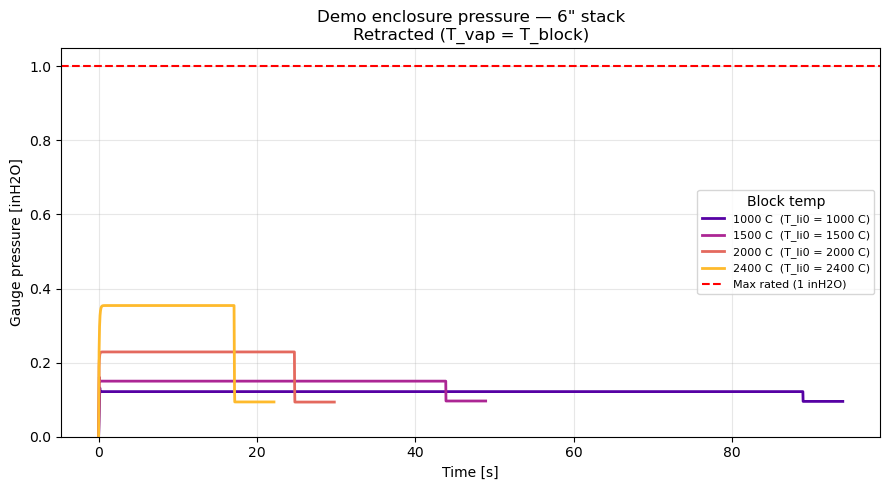

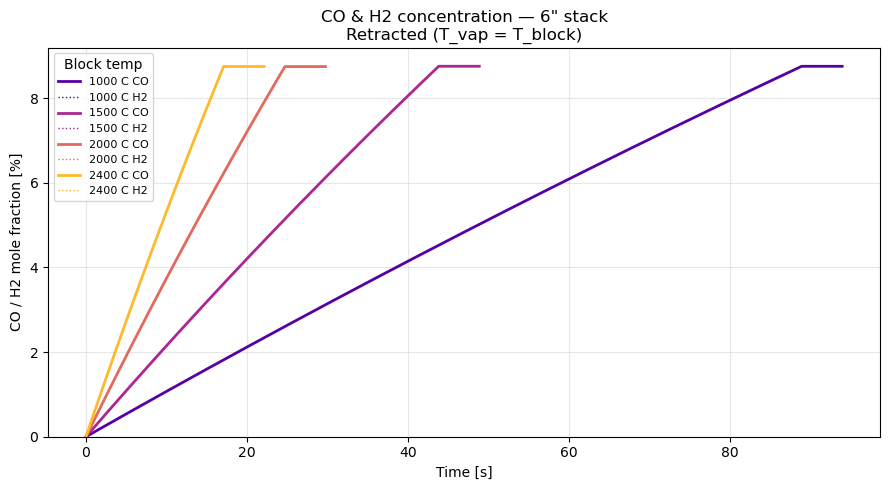

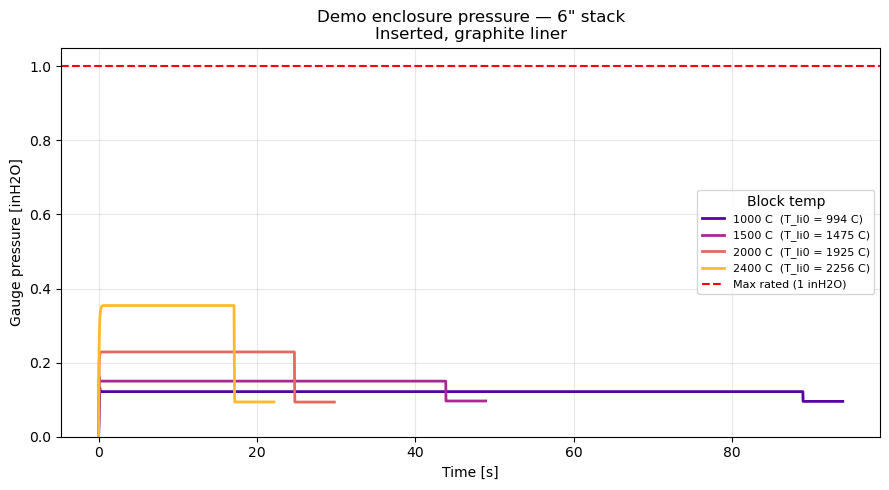

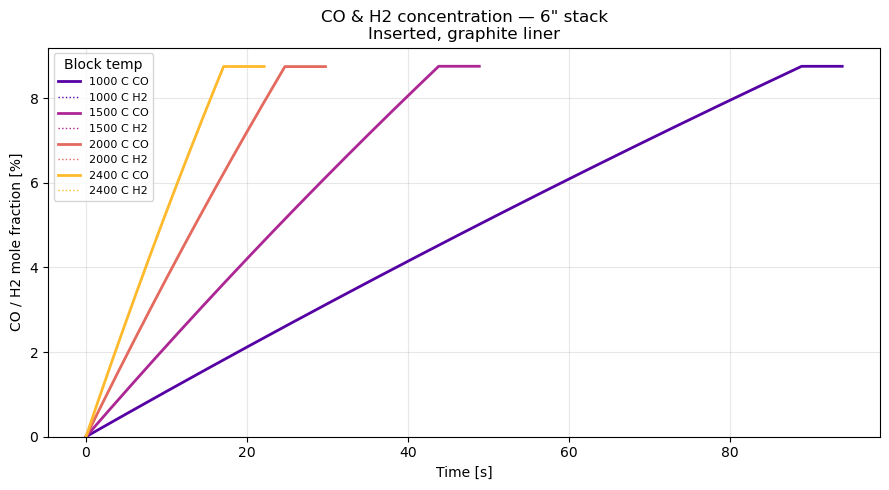

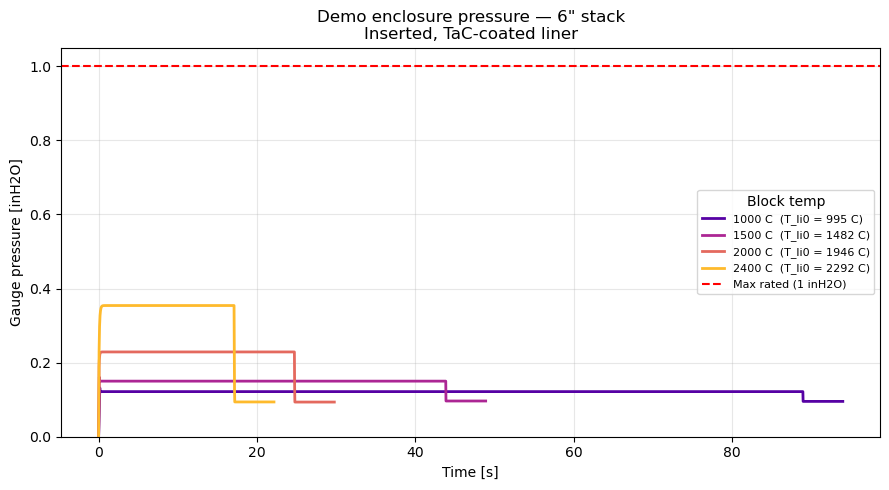

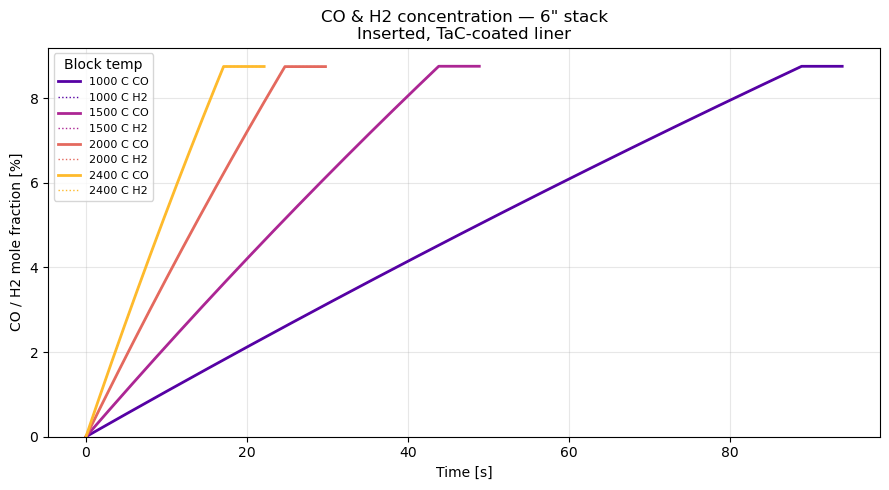

In [185]:
T_blocks_C = [1000, 1500, 2000, 2400]
colors1    = plt.cm.plasma(np.linspace(0.15, 0.85, len(T_blocks_C)))

liner_cases = [
    ('Retracted (T_vap = T_block)', False, False),
    ('Inserted, graphite liner',    False, True),
    ('Inserted, TaC-coated liner',  True,  True),
]

for lbl, coat, ins in liner_cases:
    _sims = {}
    for T_C, col in zip(T_blocks_C, colors1):
        T_K   = T_C + 273.15
        T_vap = liner_inner_temp(T_K, stick_inserted=ins, coated=coat)
        t, Pg, conc = simulate(T_K, d_stack_default,
                              stick_inserted=ins, coated=coat, t_end=120, n=4000,
                              liner_break=liner_break,
                              water_shutoff=water_shutoff)
        _sims[T_C] = (t, Pg, conc, col, T_vap)

    fig, ax = plt.subplots(figsize=(9, 5))
    for T_C, (t, Pg, conc, col, T_vap) in _sims.items():
        ax.plot(t, Pg, color=col, lw=2,
                label=f'{T_C} C  (T_li0 = {T_vap-273.15:.0f} C)')
    ax.axhline(1.0, color='red', lw=1.5, ls='--', label='Max rated (1 inH2O)')
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Gauge pressure [inH2O]')
    ax.set_title(f'Demo enclosure pressure \u2014 6" stack\n{lbl}')
    ax.legend(title='Block temp', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    for T_C, (t, Pg, conc, col, T_vap) in _sims.items():
        if water_gas_reaction:
            ax.plot(t, conc['CO'] * 100, color=col, lw=2, label=f'{T_C} C CO')
            ax.plot(t, conc['H2'] * 100, color=col, lw=1, ls=':', label=f'{T_C} C H2')
        else:
            ax.plot(t, conc['H2O'] * 100, color=col, lw=2, label=f'{T_C} C')
    ax.set_xlabel('Time [s]')
    _conc_lbl = 'CO / H2 mole fraction [%]' if water_gas_reaction else 'Water vapour [%]'
    ax.set_ylabel(_conc_lbl)
    ax.set_title(('CO & H2 concentration' if water_gas_reaction else 'Water vapour concentration') + f' — 6" stack\n{lbl}')
    ax.legend(title='Block temp', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()


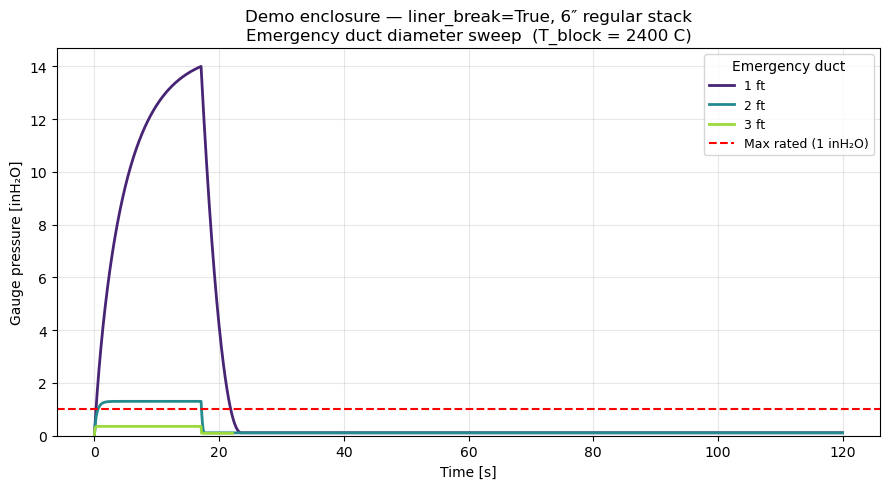

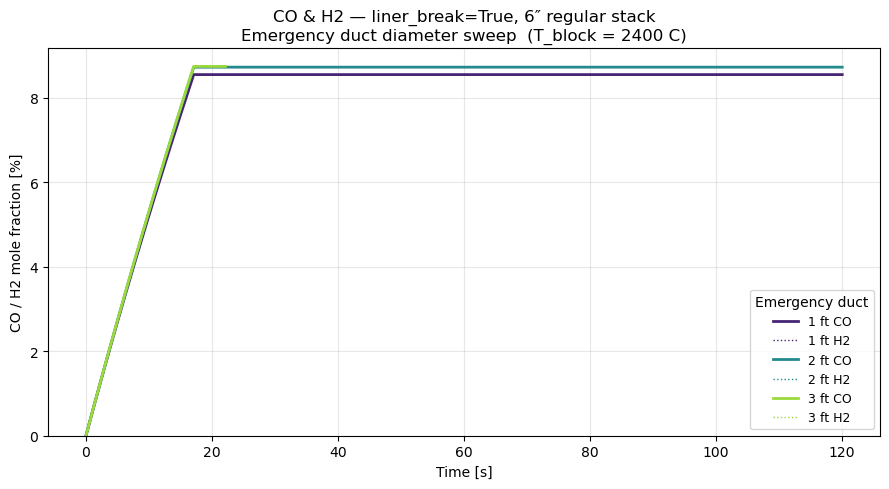

Computing peak pressures (liner_break=True) ...
  1 ft done
  2 ft done
  3 ft done


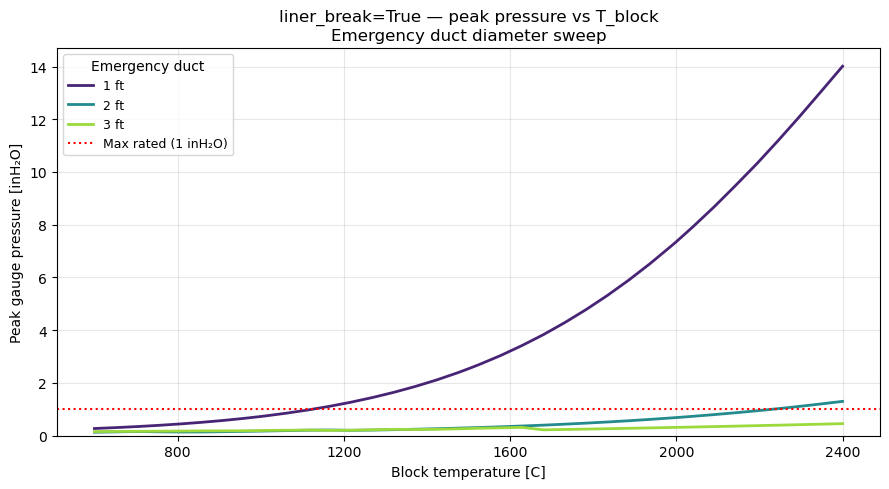

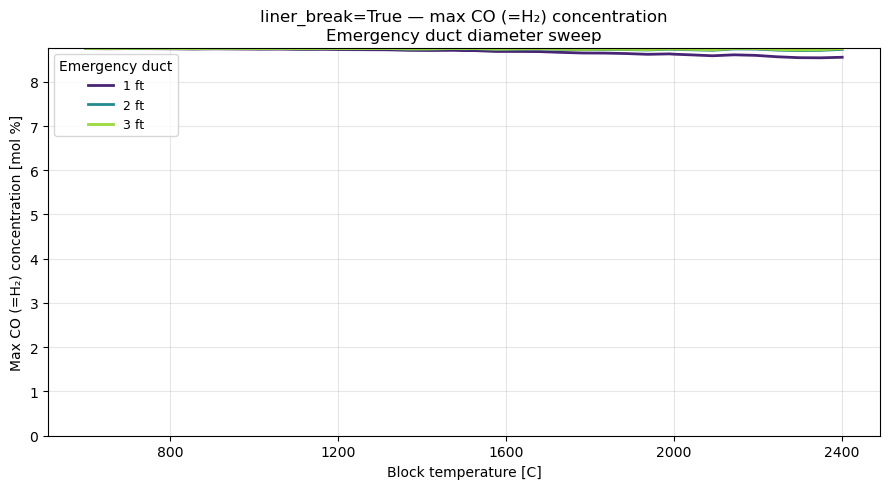


=== Peak pressure [inH₂O] — liner_break=True ===
   d_emerg  1000C   1500C   2000C   2400C 
      1 ft   0.73    2.54!   7.36!  14.01!
      2 ft   0.18    0.30    0.69    1.30!
      3 ft   0.20    0.27    0.32    0.46 
  ! = exceeds 1 inH₂O  |  units: inH₂O


In [172]:
_d_emerg_ft = [1, 2, 3]
_d_emerg_m  = [d * ft_m for d in _d_emerg_ft]
colors_e    = plt.cm.viridis(np.linspace(0.1, 0.85, len(_d_emerg_ft)))
T_block_fixed = 2400 + 273.15

_d_emerg_saved = d_emerg   # restored at end of cell

# ── P vs time at T_block = 2400 C ─────────────────────────────────────────────────
_sims_e = {}
for d_ft, d_m in zip(_d_emerg_ft, _d_emerg_m):
    d_emerg = d_m
    t, Pg, conc = simulate(T_block_fixed, d_stack_default,
                           liner_break=True, water_shutoff=water_shutoff,
                           t_end=120, n=4000)
    _sims_e[d_ft] = (t, Pg, conc)

fig, ax = plt.subplots(figsize=(9, 5))
for d_ft, col in zip(_d_emerg_ft, colors_e):
    t, Pg, conc = _sims_e[d_ft]
    ax.plot(t, Pg, color=col, lw=2, label=f'{d_ft} ft')
ax.axhline(1.0, color='red', lw=1.5, ls='--', label='Max rated (1 inH₂O)')
ax.set_xlabel('Time [s]')
ax.set_ylabel('Gauge pressure [inH₂O]')
ax.set_title('Demo enclosure — liner_break=True, 6\u2033 regular stack\n'
             'Emergency duct diameter sweep  (T_block = 2400 C)')
ax.legend(title='Emergency duct', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for d_ft, col in zip(_d_emerg_ft, colors_e):
    t, Pg, conc = _sims_e[d_ft]
    if water_gas_reaction:
        ax.plot(t, conc['CO'] * 100, color=col, lw=2, label=f'{d_ft} ft CO')
        ax.plot(t, conc['H2'] * 100, color=col, lw=1, ls=':', label=f'{d_ft} ft H2')
    else:
        ax.plot(t, conc['H2O'] * 100, color=col, lw=2, label=f'{d_ft} ft')
ax.set_xlabel('Time [s]')
_conc_lbl = 'CO / H2 mole fraction [%]' if water_gas_reaction else 'Water vapour [%]'
ax.set_ylabel(_conc_lbl)
_conc_title = 'CO & H2' if water_gas_reaction else 'Water vapour'
ax.set_title(f'{_conc_title} — liner_break=True, 6\u2033 regular stack\n'
             'Emergency duct diameter sweep  (T_block = 2400 C)')
ax.legend(title='Emergency duct', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

# ── Parametric sweep: peak pressure vs block temperature ────────────────────────
T_sweep = np.array(sorted(set(
    list(np.linspace(600, 2400, 36)) + [1000., 1500., 2000., 2400.]
)))

print("Computing peak pressures (liner_break=True) ...")
_peak_e      = {}
_peak_conc_e = {}
for d_ft, d_m in zip(_d_emerg_ft, _d_emerg_m):
    d_emerg = d_m
    peaks = []; peak_concs = []
    for T_C in T_sweep:
        _, Pg, _c = simulate(T_C + 273.15, d_stack_default,
                             liner_break=True, water_shutoff=water_shutoff,
                             t_end=600, n=6000)
        peaks.append(float(np.max(Pg)))
        _pk_key = 'CO' if water_gas_reaction else 'H2O'
        peak_concs.append(float(np.max(_c[_pk_key])) * 100)
    _peak_e[d_ft]      = np.array(peaks)
    _peak_conc_e[d_ft] = np.array(peak_concs)
    print(f"  {d_ft} ft done")

d_emerg = _d_emerg_saved   # restore

fig, ax = plt.subplots(figsize=(9, 5))
for d_ft, col in zip(_d_emerg_ft, colors_e):
    ax.plot(T_sweep, _peak_e[d_ft], lw=2, color=col, label=f'{d_ft} ft')
ax.axhline(1.0, color='red', lw=1.5, ls=':', label='Max rated (1 inH₂O)')
ax.set_xlabel('Block temperature [C]')
ax.set_ylabel('Peak gauge pressure [inH₂O]')
ax.set_title('liner_break=True — peak pressure vs T_block\nEmergency duct diameter sweep')
ax.set_xticks(np.arange(800, 2401, 400))
ax.legend(title='Emergency duct', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

_conc_species = 'CO (=H₂)' if water_gas_reaction else 'H₂O'
fig, ax = plt.subplots(figsize=(9, 5))
for d_ft, col in zip(_d_emerg_ft, colors_e):
    ax.plot(T_sweep, _peak_conc_e[d_ft], lw=2, color=col, label=f'{d_ft} ft')
ax.set_xlabel('Block temperature [C]')
ax.set_ylabel(f'Max {_conc_species} concentration [mol %]')
ax.set_title(f'liner_break=True — max {_conc_species} concentration\nEmergency duct diameter sweep')
ax.set_xticks(np.arange(800, 2401, 400))
ax.legend(title='Emergency duct', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

T_Cs = [1000, 1500, 2000, 2400]
idx  = [int(np.argmin(np.abs(T_sweep - T))) for T in T_Cs]
hdr  = f"  {'d_emerg':>8}" + ''.join(f'  {T}C ' for T in T_Cs)
print(f'\n=== Peak pressure [inH₂O] — liner_break=True ===')
print(hdr)
for d_ft in _d_emerg_ft:
    row = f'  {d_ft:>5} ft'
    for j in idx:
        P = _peak_e[d_ft][j]
        row += f'  {P:5.2f}{"!" if P > 1 else " "}'
    print(row)
print('  ! = exceeds 1 inH₂O  |  units: inH₂O')


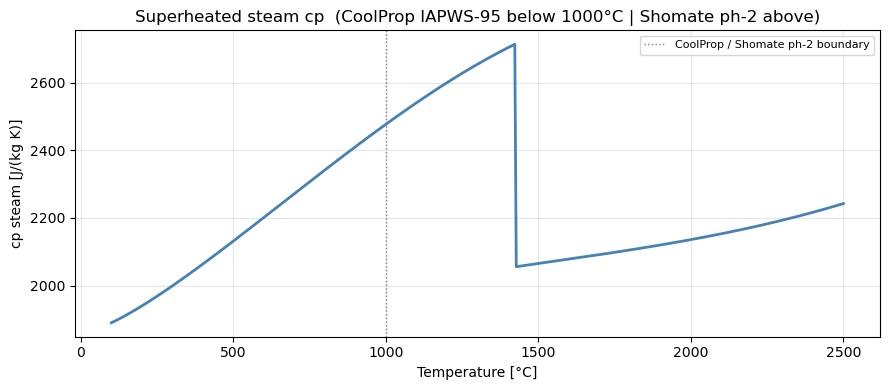

In [275]:
# ── cp_steam vs temperature (NIST Shomate) ────────────────────────────
_T_K = np.linspace(373, 2773, 500)   # 100 – 1500 °C
_T_C = _T_K - 273.15
_cp  = cp_steam(_T_K)                # J/(kg K)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(_T_C, _cp, color="steelblue", lw=2)
ax.set_xlabel("Temperature [°C]")
ax.set_ylabel("cp steam [J/(kg K)]")
ax.axvline(1273 - 273.15, color="gray", lw=1, ls=":",
           label="CoolProp / Shomate ph-2 boundary")
ax.legend(fontsize=8)
ax.set_title("Superheated steam cp  (CoolProp IAPWS-95 below 1000°C | Shomate ph-2 above)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
